# Notebook 02 — Environmental Feature Extraction and Data Understanding

**Malaysia Landslide FYP · Chapters 4.3 (Pre-processing) and 4.4 (Data Understanding)**

### Execution stages (important)

| Stage | Main sections | Observations | Main outputs | Run when? |
|---|---|---|---|---|
| A — Original inventory features | 0–10 | Landslide candidates from Notebook 01 only | `environmental_features.csv` | Initial preparation or verified upstream change |
| B — Post-matching environmental enhancements | 10A–10D | **Actual landslide and matched-background sample coordinates from Notebook 03** | Historical enhancement and curvature/TWI `sample_id` sidecars | After Notebook 03; resume/reuse existing files |
| C — Documentation evidence | Final QA section | Read-only existing outputs | Chapter 4 summary CSVs and plots | Any time after outputs exist |

**Why two stages?** Notebook 03 must create background locations before those locations can receive environmental values. Notebook 02's later 10A–10D cells therefore intentionally depend on Notebook 03. **Do not interpret their physical cell order as an instruction to rerun the entire notebook.**

No earth-engine fetch is needed to create documentation figures. The data-understanding section below reads saved outputs only. Provenance/status fields are audit metadata, not model predictors. Historical time-dependent factors must be referenced to the event date, not the present day.


## 0. Dependencies and settings

VS Code: run from the project notebook folder. Install if necessary: `%pip install pandas numpy matplotlib rasterio geopandas shapely pyproj earthengine-api` (Earth Engine required only when the optional switch is enabled). Earth Engine requires a registered project and authentication.

In [1]:
from pathlib import Path
from collections import defaultdict
import re, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from rasterio.warp import transform as warp_xy
from rasterio.windows import Window
from shapely.geometry import Point
from pyproj import Geod
from IPython.display import display

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'data'/'raw'/'references').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run in the Landslide_FYP project or set ROOT to your project path')
REF = ROOT/'data'/'raw'/'references'
INPUT = ROOT/'data'/'processed'/'inventory'/'event_candidates.csv'
FEATURE_OUT = ROOT/'data'/'processed'/'features'/'environmental_features.csv'
AUDIT_OUT = ROOT/'outputs'/'audits'/'environmental_layer_audit.csv'
SUMMARY_OUT = ROOT/'outputs'/'audits'/'environmental_feature_summary.csv'
FIG_OUT = ROOT/'outputs'/'figures'/'environmental_feature_overview.png'
for p in (FEATURE_OUT,AUDIT_OUT,SUMMARY_OUT,FIG_OUT):p.parent.mkdir(parents=True,exist_ok=True)
# Before/after audit: existing file is read only, compared only for matching event IDs.
old_feature = pd.read_csv(FEATURE_OUT,low_memory=False).set_index('event_candidate_id') if FEATURE_OUT.exists() else None

RUN_EARTH_ENGINE = True  # Set True after verifying credentials; avoids unexpected network requests
EE_PROJECT_ID = 'fyplandslide'         # Your registered Earth Engine Cloud Project ID
EE_RUN_MODE = 'full'          # 'test' first; change to 'full' after inspecting outputs
EE_MAX_DATED_EVENTS = 30      # Applies to TEST only, not ML eligibility
EE_BATCH_SIZE = 35            # Maximum events in one same-date EE reduceRegions request
EE_RETRIES = 3
EE_GET_EXPLORATORY_ARCHIVE = True   # Extract archive values for QC, never approve archive for ML
EE_CHECKPOINT = ROOT/'data'/'processed'/'features'/'.ee_temporal_checkpoint.csv'
EE_PIPELINE_VERSION = 'imerg_v07_era5_daily_dw_preevent_v2'

# Optional, independent predicted-soil fallback (does NOT edit any raw SoilGrids TIFF).
# First run 'test' on up to 10 deficient locations; set 'full' after checking results.
RUN_SOIL_FALLBACK = True
SOIL_FALLBACK_MODE = 'full'  # 'test' or 'full'
SOIL_FALLBACK_TEST_LIMIT = 10
SOIL_FALLBACK_BATCH_SIZE = 40

# Source expansion is OFF by default. Switch each to TEST deliberately after reading Section 6.1/8.1.
# JMG requests use the official public FeatureServer; no paid API is required.
RUN_JMG_API_ENRICHMENT = True  # Enable after reading Section 6.1
JMG_API_MODE = 'full'  # 'test' (10 missing points) or 'full'
JMG_API_TEST_LIMIT = 10
JMG_API_REQUEST_DELAY_S = 0.35  # Public server; avoid burst requests
# For events without a state label, first try a verified admin-1 polygon file.
# Optional: place a Malaysian state-level GeoJSON/shapefile under data/raw/references/admin/
# with a state/name attribute. Never use admin-0 as an admin-1 substitute.
JMG_ADMIN_STATE_FILE = ''  # optional absolute or project-relative state boundary file
JMG_ADMIN_STATE_FIELD = '' # optional explicit property; autodetect otherwise
# Extra point-by-point state search is expensive: 15 layers maximum per location.
JMG_UNKNOWN_STATE_SCAN = True  # test only; do not blindly send 3000 requests
JMG_UNKNOWN_STATE_SCAN_LIMIT = 250
JMG_FAULT_SEARCH_RADIUS_DEG = 0.55  # bounded search; NOT assured global nearest
JMG_API_RETRY_COUNT = 2
RUN_ERA5_HOURLY_RECHECK = False  # optional 3-record same-source test; off until reviewed
ERA5_HOURLY_MAX_TEST = 3
RUN_GLDAS_MOISTURE_DIAGNOSTIC = True # enable explicitly after JMG test
GLDAS_MODE = 'full'    # 'test' for 10 missing; 'full' for all dated gaps
GLDAS_TEST_LIMIT = 10
GLDAS_COMPARE_LIMIT = 12  # simultaneous ERA5/GLDAS samples for bias context, not calibration


# Post-checkpoint ERA5 native-grid resampling: only the still-missing dated points.
# This does not repeat historical IMERG or Dynamic World requests.
RUN_ERA5_NATIVE_RECHECK = True
ERA5_NATIVE_TEST_LIMIT = None   # None = attempt all still-missing dated locations
# Use a fresh exploratory GLDAS value only if paired validation is acceptable.
# No automatic GLDAS->ERA5 substitution; distinct 0–10cm vs 0–7cm depths.
JMG_VERIFY_ALL_POINTS = True  # full, independently query JMG material for all 713 points
JMG_AUTODISCOVER_STATE_LAYERS = True  # query only relevant MyGEMS layer extents
JMG_STATE_METADATA_CACHE = ROOT/'data'/'processed'/'features'/'.jmg_state_layer_extents.json'

EE_RAIN_WINDOWS = (1,3,7,14,30)
EE_GET_TERRAIN = True
EE_GET_RAIN = True
EE_GET_MOISTURE = True
EE_GET_DYNAMIC_WORLD = True
EE_TERRAIN_CHUNK_SIZE = 125
EE_SCALE_RAIN_M = 11132
EE_SCALE_SOIL_M = 11132
EE_SCALE_DW_M = 10
print('Project:',ROOT,'| Earth Engine enabled:',RUN_EARTH_ENGINE)

Project: C:\landslide_fyp | Earth Engine enabled: True


## 1. Load the curated event candidates; preserve provenance and eligibility

The JMG archive may have provisional CRS and duplicate-review flags. Retain these even when environmental sampling succeeds. Sampling a pixel is **not** independent event verification.

In [2]:
if not INPUT.exists():raise FileNotFoundError(f'Run Notebook 01 first: {INPUT}')
events=pd.read_csv(INPUT,low_memory=False)
required={'event_candidate_id','source','longitude_candidate','latitude_candidate','event_date','date_precision','static_candidate','temporal_candidate'}
if required-set(events):raise ValueError('Inventory schema missing: '+str(sorted(required-set(events))))
if not events.event_candidate_id.is_unique:raise ValueError('Duplicate event_candidate_id values')
features=events.copy()
for c in ('longitude_candidate','latitude_candidate'):features[c]=pd.to_numeric(features[c],errors='coerce')
# Only day-precision dates should be used for antecedent weather. Do not invent day/month.
features['event_dt']=pd.to_datetime(features.event_date,errors='coerce')
features['event_year']=pd.to_numeric(features.get('reported_year',np.nan),errors='coerce')
features['event_year']=features['event_year'].fillna(features.event_dt.dt.year)
features['point_valid']=features.longitude_candidate.between(98,120)&features.latitude_candidate.between(0,9)
features['day_precision']=features.date_precision.astype(str).str.lower().isin(['day','day_timestamp_field']) & features.event_dt.notna()
for c in ['static_candidate','temporal_candidate']:
    features[c]=features[c].astype('boolean').fillna(False).astype(bool)
features['exploratory_static_eligible']=features.point_valid
features['exploratory_temporal_eligible']=features.point_valid & features.day_precision
# Expanded flags from revised Notebook 01; they do not certify independent events.
for col in ('expanded_static_candidate','expanded_temporal_candidate'):
    if col not in features:
        raise ValueError(f'Updated Notebook 01 required: missing {col}. Run Notebook 01 first.')
    features[col] = features[col].astype('boolean').fillna(False).astype(bool)
features['expanded_static_inventory_eligible'] = features.expanded_static_candidate & features.point_valid
features['expanded_temporal_inventory_eligible'] = (
    features.expanded_temporal_candidate & features.point_valid & features.day_precision)
features['strict_static_inventory_eligible']=features.static_candidate & features.point_valid
features['strict_temporal_inventory_eligible']=features.temporal_candidate & features.point_valid & features.day_precision
print('Records:',len(features),'| Coordinate ranges valid:',features.point_valid.sum())
display(features.groupby('source').agg(records=('source','size'),coordinates=('point_valid','sum'),complete_day=('day_precision','sum')))

Records: 713 | Coordinate ranges valid: 713


,records,coordinates,complete_day
source,,,
COOLR,236,236,236
GFLD,61,61,61
JMG_archive,364,364,361
JMG_original,52,52,47


## 2. Inventory of reference assets

Detect the exact project folders: `terrain`, `soil`, `geology/Faults`, `geology/Lithology`, `landcover/GLC_FCS30D`, `landcover/Dynamic_World`, `rainfall`, `roads`, `waterways`. The `Original_JMG_Geology` folder contains duplicates of the five-AOI layers and is deliberately ignored to avoid double counting.

In [3]:
audit=[]
def add_audit(category, item, path='', status='', detail=''):
    audit.append(dict(category=category,asset=item,file=str(path),status=status,detail=str(detail)))
rasters = sorted(p for p in REF.rglob('*') if p.suffix.lower() in {'.tif','.tiff'} and p.is_file())
for p in rasters:
    try:
        with rasterio.open(p) as ds:
            add_audit(p.relative_to(REF).parts[0],p.name,p.relative_to(ROOT),'readable',
                      f'CRS={ds.crs}; bands={ds.count}; nodata={ds.nodata}; res={ds.res}; bounds={tuple(round(v,2) for v in ds.bounds)}')
    except Exception as exc: add_audit('raster',p.name,p.relative_to(ROOT),'ERROR',str(exc))
for category in ['terrain','soil','landcover','rainfall','geology','roads','waterways']:
    d=REF/category
    if not d.exists(): add_audit(category,'folder',d,'missing_directory')
    else: add_audit(category,'folder',d.relative_to(ROOT),'directory_exists',f'{len(list(d.rglob("*.shp")))} shapefiles; {len(list(d.rglob("*.tif")))} tifs')
print('Rasters:',len(rasters),'| Shapefiles:',len(list(REF.rglob('*.shp'))))
display(pd.DataFrame(audit).groupby(['category','status']).size().rename('count').reset_index())

Rasters: 408 | Shapefiles: 24


,category,status,count
0,geology,directory_exists,1
1,landcover,directory_exists,1
2,landcover,readable,176
3,rainfall,directory_exists,1
4,roads,directory_exists,1
5,soil,directory_exists,1
6,soil,readable,4
7,terrain,directory_exists,1
8,terrain,readable,228
9,waterways,directory_exists,1


## 3. Safe raster point sampling and nodata checks

Samples using each raster's actual CRS. Masked, infinite and missing values become `NaN`. The nearest pixel is used for categorical raster and point-context features; no nearest-valid-pixel replacement is performed, because that can move landslides to different terrain.

In [1]:
# Safe sampling returns an explicit reason for every missing value.
# Handles raster CRS, dataset masks, explicit nodata, out-of-bounds and transform errors.
REASONS={'SOURCE_NOT_AVAILABLE','OUTSIDE_SPATIAL_COVERAGE','YEAR_NOT_AVAILABLE',
         'EVENT_DATE_INCOMPLETE','RASTER_NODATA','INVALID_GEOMETRY',
         'CRS_TRANSFORMATION_ERROR','API_REQUEST_FAILED','EXTRACTION_ERROR',
         'NOT_REQUESTED','NOT_IN_TEST_SAMPLE','OUTSIDE_VALIDATED_AOI',
         'INVALID_SOURCE_VALUE','UNVERIFIED_UNITS','AMBIGUOUS_SPATIAL_JOIN'}
def blank_reason():
    return np.full(len(features),'SOURCE_NOT_AVAILABLE',dtype=object)

def raster_sample(path,frame,band=1,kind='continuous'):
    values=np.full(len(frame),np.nan)
    reasons=np.full(len(frame),'INVALID_GEOMETRY',dtype=object)
    local_valid=frame.point_valid.to_numpy(dtype=bool)
    if not Path(path).exists():
        reasons[local_valid]='SOURCE_NOT_AVAILABLE';return values,reasons
    with rasterio.open(path) as ds:
        reasons[local_valid]='EXTRACTION_ERROR'
        if ds.crs is None or band>ds.count:
            reasons[local_valid]='CRS_TRANSFORMATION_ERROR';return values,reasons
        inds=np.flatnonzero(local_valid)
        for k in inds:
            try:
                lon=float(frame.iloc[k].longitude_candidate);lat=float(frame.iloc[k].latitude_candidate)
                xx,yy=([lon],[lat]) if ds.crs.to_epsg()==4326 else warp_xy('EPSG:4326',ds.crs,[lon],[lat])
                x,y=xx[0],yy[0]
                if not (np.isfinite(x) and np.isfinite(y)):
                    reasons[k]='CRS_TRANSFORMATION_ERROR';continue
                row,col=ds.index(x,y)
                if row<0 or row>=ds.height or col<0 or col>=ds.width:
                    reasons[k]='OUTSIDE_SPATIAL_COVERAGE';continue
                sample=ds.read(band,window=Window(col,row,1,1),masked=True)
                if np.ma.getmaskarray(sample).any():
                    reasons[k]='RASTER_NODATA';continue
                val=float(sample[0,0])
                if not np.isfinite(val):reasons[k]='RASTER_NODATA';continue
                if kind=='soil_bdod' and val<=0:
                    reasons[k]='INVALID_SOURCE_VALUE';continue
                if kind=='landcover' and (val<=0 or val>255):
                    reasons[k]='RASTER_NODATA';continue
                values[k]=val;reasons[k]=''
            except (rasterio.errors.RasterioError,ValueError,OverflowError,TypeError):
                reasons[k]='EXTRACTION_ERROR'
            except Exception:
                reasons[k]='CRS_TRANSFORMATION_ERROR'
    return values,reasons

def candidates_under(directory,suffix='.tif'):
    return sorted(p for p in directory.rglob('*') if p.is_file() and p.suffix.lower() in {suffix,'.tiff'}) if directory.exists() else []

## 4. SoilGrids — six depth bands, units and invalid-zero QC

SoilGrids source units should be checked against the actual raster metadata. Common SoilGrids convention: clay/sand/silt in g/kg (divide by 10 for %); bdod in cg/cm³ (divide by 100 for g/cm³). Each file contains six standard depth intervals (0–5, 5–15, 15–30, 30–60, 60–100, 100–200 cm), **only if source metadata confirms band order**. This notebook exposes all six raw bands for inspection and computes *provisional* topsoil conversions with an explicit assumption flag, rather than silently asserting verified units.

In [5]:
SOIL_DEPTHS=['0_5','5_15','15_30','30_60','60_100','100_200']
soil_paths={}
for key in ('clay','sand','silt','bdod'):
    matches=[p for p in candidates_under(REF/'soil') if key in p.stem.lower()]
    if len(matches)==1:soil_paths[key]=matches[0]
    else:add_audit('soil',key,'','missing_or_ambiguous',str(len(matches))+' matching files')
for key in ('clay','sand','silt','bdod'):
    features[f'soil_{key}_surface']=np.nan
    features[f'soil_{key}_reason']=blank_reason()
    if key not in soil_paths:continue
    p=soil_paths[key]
    with rasterio.open(p) as ds:
        desc=[str(x or '') for x in ds.descriptions]
        if ds.count!=6:
            add_audit('soil',key,str(p),'unexpected_band_count',str(ds.count));continue
        # Require source band descriptions (present in the uploaded layer audit).
        expected=('0-5','5-15','15-30','30-60','60-100','100-200')
        if any(t not in d.replace('_','-') for t,d in zip(expected,desc)):
            add_audit('soil',key,str(p),'depth_metadata_unverified',str(desc));continue
    for j,depth in enumerate(SOIL_DEPTHS,1):
        raw,reason=raster_sample(p,features,j,kind='soil_bdod' if key=='bdod' else 'continuous')
        features[f'soil_{key}_{depth}_raw']=raw
        if j==1:
            # SoilGrids standard conversion: texture g/kg -> percent /10; bdod cg/cm3 -> g/cm3 /100.
            factor=100 if key=='bdod' else 10
            features[f'soil_{key}_surface']=raw/factor
            features[f'soil_{key}_reason']=reason
    add_audit('soil',key,p.relative_to(ROOT),'sampled','Six described bands; source-standard scaling applied; check against raster provider metadata')
soil_cols=[f'soil_{x}_surface' for x in ('clay','sand','silt','bdod')]
# Single-variable pixel values are not invalid merely because another variable is missing.
for key in ('clay','sand','silt','bdod'):
    c=f'soil_{key}_surface'; rc=f'soil_{key}_reason'
    if key=='bdod': bad=features[c].notna() & ~features[c].between(.1,3.0)
    else: bad=features[c].notna() & ~features[c].between(0,100)
    features.loc[bad,rc]='INVALID_SOURCE_VALUE'
    features.loc[bad,c]=np.nan
texture=features[soil_cols[:3]]
features['soil_composition_sum_pct']=texture.sum(axis=1,min_count=3)
# Joint zero texture / near-zero total is not genuine zero soil; source mask may encode nodata as zero.
zero_texture=texture.notna().all(axis=1) & (texture.sum(axis=1)==0)
implausible=texture.notna().all(axis=1) & ~features.soil_composition_sum_pct.between(90,110)
for key in ('clay','sand','silt'):
    c=f'soil_{key}_surface';rc=f'soil_{key}_reason'
    bad=(zero_texture|implausible) & features[c].notna()
    features.loc[bad,rc]='INVALID_SOIL_COMPOSITION'
    features.loc[bad,c]=np.nan
features['soil_qc_reason']=np.where(zero_texture,'ALL_ZERO_TEXTURE',
                             np.where(implausible,'INVALID_SOIL_COMPOSITION',
                             np.where(features[soil_cols].notna().all(axis=1),'', 'INCOMPLETE_SOURCE_PIXELS')))
features['soil_surface_usable']=features[soil_cols].notna().all(axis=1)
features['soil_units_provisional']=True
print('Soil source pixels absent / invalid values:')
for key in ('clay','sand','silt','bdod'):
    print(key,features[f'soil_{key}_reason'].replace('', 'VALID').value_counts().to_dict())
print('Soil complete after QC:',int(features.soil_surface_usable.sum()))
display(features[soil_cols+['soil_composition_sum_pct']].describe().T)

Soil source pixels absent / invalid values:
clay {'VALID': 546, 'INVALID_SOIL_COMPOSITION': 167}
sand {'VALID': 546, 'INVALID_SOIL_COMPOSITION': 167}
silt {'VALID': 546, 'INVALID_SOIL_COMPOSITION': 167}
bdod {'VALID': 540, 'INVALID_SOURCE_VALUE': 173}
Soil complete after QC: 531


,count,mean,std,min,25%,50%,75%,max
soil_clay_surface,546.0,36.681868,3.726146,26.40,33.625,36.80,38.900,54.30
soil_sand_surface,546.0,33.955861,4.106470,10.60,32.100,34.10,36.375,45.30
soil_silt_surface,546.0,29.363919,3.834709,14.60,26.800,29.10,32.800,41.30
soil_bdod_surface,540.0,1.075981,0.111258,0.66,1.050,1.11,1.140,1.32
soil_composition_sum_pct,713.0,76.579102,42.381586,0.00,99.900,100.00,100.000,100.10


### 4.1 Soil source validation, spatial-mask diagnostics, and OPTIONAL independent fallback

The ISRIC GEE mask diagnostic returned `valid_mask=0` at five missing-soil sites.
This is a masked source pixel, not an API-token problem. We first preserve the
original local SoilGrids values/reasons. Optionally, **OpenLandMap** provides an
independent 250 m predicted-soil surface. Its b0 estimates refer to 0 cm depth,
whereas SoilGrids 0-5 cm is a depth interval. Thus fallback estimates are not
exact replacements; every fallback retains a source label and a depth caveat.
OpenLandMap provides clay/sand but no separate continuous silt fraction in the
consulted EE catalogue. We derive silt=100-clay-sand only when BOTH OpenLandMap
texture percentages are credible, and flag this derivation explicitly.

In test mode only a handful of missing locations are attempted; in full mode all
locally incomplete points are attempted. No values are fabricated or extrapolated
to a nearest non-missing pixel. Existing valid SoilGrids texture triples remain
untouched. Do NOT run this on a paid/unregistered Earth Engine project.

In [6]:
# Provenance is tracked per physical property; original local extraction retained.
for soil_key in ('clay','sand','silt','bdod'):
    name=f'soil_{soil_key}_surface'
    features[f'{name}_isric_original']=features[name].copy()
    features[f'soil_{soil_key}_source']=np.where(features[name].notna(),'ISRIC_SoilGrids_local_0_5cm','unavailable')
    features[f'soil_{soil_key}_fallback_reason']='NOT_REQUESTED'

features['soil_fallback_attempted']=False
features['soil_fallback_depth_note']='OpenLandMap b0=0cm; SoilGrids surface=0-5cm; not strictly equivalent'

# Source dataset metadata from the official Earth Engine catalogue.
# Clay/sand b0 values are already percent. Bulk density b0 values are
# 10*kg/m3; raw / 100 therefore gives g/cm3 (e.g. 130 -> 1.30).
OPENLANDMAP_ASSETS = {
    'clay': 'OpenLandMap/SOL/SOL_CLAY-WFRACTION_USDA-3A1A1A_M/v02',
    'sand': 'OpenLandMap/SOL/SOL_SAND-WFRACTION_USDA-3A1A1A_M/v02',
    'bdod': 'OpenLandMap/SOL/SOL_BULKDENS-FINEEARTH_USDA-4A1H_M/v02',
}

def apply_openlandmap_soil(records_by_id):
    """Use whole alternative texture trio together; keep local originals for audit."""
    recovered_texture=recovered_density=0
    for i,r in features.loc[features.point_valid].iterrows():
        rec=records_by_id.get(str(r.event_candidate_id))
        if rec is None:
            continue
        features.at[i,'soil_fallback_attempted']=True
        raw_clay=rec.get('olm_clay');raw_sand=rec.get('olm_sand');raw_bdod=rec.get('olm_bdod')
        def finite_number(x):
            try: return float(x) if x is not None and np.isfinite(float(x)) else None
            except (ValueError,TypeError): return None
        clay,sand,bdod=map(finite_number,(raw_clay,raw_sand,raw_bdod))
        # Avoid combining texture fractions from two independently calibrated maps.
        incomplete_texture=not all(pd.notna(features.at[i,f'soil_{key}_surface']) for key in ('clay','sand','silt'))
        if incomplete_texture:
            if clay is not None and sand is not None and 0<=clay<=100 and 0<=sand<=100 and 0<=100-clay-sand<=100:
                alternative={'clay':clay,'sand':sand,'silt':100-clay-sand}
                for key,val in alternative.items():
                    features.at[i,f'soil_{key}_surface']=val
                    features.at[i,f'soil_{key}_reason']=''
                    features.at[i,f'soil_{key}_source']=('OpenLandMap_b0_derived_silt' if key=='silt' else 'OpenLandMap_b0')
                    features.at[i,f'soil_{key}_fallback_reason']=''
                recovered_texture+=1
            else:
                for key in ('clay','sand','silt'):
                    features.at[i,f'soil_{key}_fallback_reason']=('ALTERNATIVE_PIXEL_MASKED' if clay is None or sand is None else 'INVALID_ALTERNATIVE_TEXTURE')
        if pd.isna(features.at[i,'soil_bdod_surface']):
            density=bdod/100 if bdod is not None else None
            if density is not None and .1<=density<=3.0:
                features.at[i,'soil_bdod_surface']=density
                features.at[i,'soil_bdod_reason']=''
                features.at[i,'soil_bdod_source']='OpenLandMap_b0'
                features.at[i,'soil_bdod_fallback_reason']=''
                recovered_density+=1
            else:
                features.at[i,'soil_bdod_fallback_reason']=('ALTERNATIVE_PIXEL_MASKED' if density is None else 'INVALID_ALTERNATIVE_DENSITY')
    return recovered_texture,recovered_density

if RUN_SOIL_FALLBACK:
    if SOIL_FALLBACK_MODE not in ('test','full'):
        raise ValueError('SOIL_FALLBACK_MODE must be test or full')
    if not EE_PROJECT_ID:
        raise ValueError('Set EE_PROJECT_ID before using the optional soil fallback')
    import ee
    ee.Initialize(project=EE_PROJECT_ID)
    # Only candidates with at least one missing soil property, and valid coordinates.
    needed=features.loc[features.point_valid & ~features.soil_surface_usable].copy()
    if SOIL_FALLBACK_MODE=='test':
        # Evenly spread source/region categories for a representative smoke test.
        needed=needed.sort_values(['source','longitude_candidate','latitude_candidate'])
        needed=needed.iloc[np.unique(np.linspace(0,len(needed)-1,min(len(needed),SOIL_FALLBACK_TEST_LIMIT),dtype=int))] if len(needed) else needed
    print(f'OpenLandMap soil {SOIL_FALLBACK_MODE}: querying {len(needed)} deficient candidate points.')
    # Construct ONE three-band image; no per-property HTTP calls.
    soil_image=ee.Image.cat([
        ee.Image(OPENLANDMAP_ASSETS['clay']).select('b0').rename('olm_clay'),
        ee.Image(OPENLANDMAP_ASSETS['sand']).select('b0').rename('olm_sand'),
        ee.Image(OPENLANDMAP_ASSETS['bdod']).select('b0').rename('olm_bdod'),
    ])
    responses={}
    for start in range(0,len(needed),SOIL_FALLBACK_BATCH_SIZE):
        batch=needed.iloc[start:start+SOIL_FALLBACK_BATCH_SIZE]
        points=ee.FeatureCollection([
            ee.Feature(ee.Geometry.Point([float(r.longitude_candidate),float(r.latitude_candidate)]),
                       {'event_candidate_id':str(r.event_candidate_id)})
            for _,r in batch.iterrows()
        ])
        last_error=None
        for attempt in range(EE_RETRIES):
            try:
                data=soil_image.reduceRegions(collection=points,reducer=ee.Reducer.first(),scale=250).getInfo()
                for ft in data.get('features',[]):
                    props=ft.get('properties') or {}
                    rid=props.get('event_candidate_id')
                    if rid is not None:responses[str(rid)]=props
                last_error=None
                break
            except Exception as exc:
                last_error=exc
                if attempt+1<EE_RETRIES:
                    import time
                    time.sleep(min(12,2**attempt*2))
        if last_error is not None:
            add_audit('soil','OpenLandMap_b0', '', 'API_REQUEST_FAILED',str(last_error)[:200])
            for idx in batch.index:
                for key in ('clay','sand','silt','bdod'):
                    features.at[idx,f'soil_{key}_fallback_reason']='API_REQUEST_FAILED'
    texture_added,density_added=apply_openlandmap_soil(responses)
    add_audit('soil','OpenLandMap_b0', '', 'optional_alternative',
              f'mode={SOIL_FALLBACK_MODE}; queried={len(needed)}; returned={len(responses)}; texture_triples={texture_added}; bulk_density={density_added}; depth=0cm')
    print(f'Validated alternative texture triples: {texture_added}; alternative bulk density: {density_added}')
else:
    add_audit('soil','OpenLandMap_b0', '', 'disabled', 'No fallback queries; local ISRIC values preserved')

# Update completeness *after* optional fallback; keep individual source provenance.
texture=features[['soil_clay_surface','soil_sand_surface','soil_silt_surface']]
features['soil_composition_sum_pct']=texture.sum(axis=1,min_count=3)
features['soil_surface_usable']=features[['soil_clay_surface','soil_sand_surface','soil_silt_surface','soil_bdod_surface']].notna().all(axis=1)
features['soil_qc_reason']=np.where(features.soil_surface_usable,'',
    np.where(features.soil_fallback_attempted,'INCOMPLETE_AFTER_ALTERNATIVE_QC',
             features.soil_qc_reason))
print('Soil complete after optional fallback:',int(features.soil_surface_usable.sum()),'of',len(features))
print('Soil property provenance:')
for soil_key in ('clay','sand','silt','bdod'):
    print(soil_key,features[f'soil_{soil_key}_source'].value_counts().to_dict())

OpenLandMap soil full: querying 182 deficient candidate points.
Validated alternative texture triples: 160; alternative bulk density: 165
Soil complete after optional fallback: 705 of 713
Soil property provenance:
clay {'ISRIC_SoilGrids_local_0_5cm': 546, 'OpenLandMap_b0': 160, 'unavailable': 7}
sand {'ISRIC_SoilGrids_local_0_5cm': 546, 'OpenLandMap_b0': 160, 'unavailable': 7}
silt {'ISRIC_SoilGrids_local_0_5cm': 546, 'OpenLandMap_b0_derived_silt': 160, 'unavailable': 7}
bdod {'ISRIC_SoilGrids_local_0_5cm': 540, 'OpenLandMap_b0': 165, 'unavailable': 8}


## 5. SRTM DEM — elevation, slope and aspect (only if available locally)

A valid DEM must have known elevation units (usually metres), a valid CRS and continuous neighbouring pixels. The slope/aspect computation uses a 3×3 neighbourhood and geodesic spacing for geographic CRS, rather than treating decimal degrees as metres. Edge or nodata cells remain missing. **Do not interpret slope/aspect as completed if `terrain/` is empty.**

In [7]:
dems=[p for p in candidates_under(REF/'terrain') if any(k in p.name.lower() for k in ['srtm','dem','elevation']) and not any(k in p.name.lower() for k in ['slope','aspect'])]
features['elevation_m']=np.nan;features['slope_deg']=np.nan;features['aspect_deg']=np.nan
GEOD=Geod(ellps='WGS84')
def terrain_at_pixel(ds,lon,lat):
    xs,ys=([lon],[lat]) if str(ds.crs).upper()=='EPSG:4326' else warp_xy('EPSG:4326',ds.crs,[lon],[lat])
    row,col=ds.index(xs[0],ys[0]); a=ds.read(1,window=rasterio.windows.Window(col-1,row-1,3,3),boundless=True,masked=True)
    if a.shape!=(3,3) or np.ma.getmaskarray(a).any():return (np.nan,np.nan,np.nan)
    v=np.asarray(a,dtype=float)
    if not np.isfinite(v).all():return (np.nan,np.nan,np.nan)
    elev=v[1,1]
    if ds.crs.is_geographic:
        # Longitudinal and latitudinal cell size in metres at this point.
        _,_,dx=GEOD.inv(lon,lat,lon+abs(ds.res[0]),lat)
        _,_,dy=GEOD.inv(lon,lat,lon,lat+abs(ds.res[1]))
    else: dx,dy=abs(ds.res[0]),abs(ds.res[1])
    if dx<=0 or dy<=0:return (elev,np.nan,np.nan)
    dzdx=((v[0,2]+2*v[1,2]+v[2,2])-(v[0,0]+2*v[1,0]+v[2,0]))/(8*dx)
    dzdy=((v[2,0]+2*v[2,1]+v[2,2])-(v[0,0]+2*v[0,1]+v[0,2]))/(8*dy)
    slope=np.degrees(np.arctan(np.hypot(dzdx,dzdy)))
    aspect=(np.degrees(np.arctan2(-dzdx,dzdy))+360)%360
    return elev,slope,aspect
if dems:
    # Multiple DEM tiles: first tile with valid data wins; no arbitrary nearest-tile extrapolation.
    for p in dems:
        with rasterio.open(p) as ds:
            if not ds.crs: add_audit('terrain',p.name,p,'missing_crs');continue
            for i,r in features.loc[features.point_valid & features.elevation_m.isna()].iterrows():
                try:
                    e,s,a=terrain_at_pixel(ds,float(r.longitude_candidate),float(r.latitude_candidate))
                    if np.isfinite(e): features.loc[i,['elevation_m','slope_deg','aspect_deg']]=[e,s,a]
                except (ValueError,IndexError,rasterio.errors.RasterioError):pass
        add_audit('terrain',p.name,p.relative_to(ROOT),'DEM_sampled','check vertical datum and metres')
else: add_audit('terrain','SRTM DEM','','not_available','Terrain extraction requires validated local DEM; no invented values')
for col in ('elevation_m','slope_deg','aspect_deg'):
    features[col+'_reason']=np.where(features[col].notna(),'',np.where(~features.point_valid,'INVALID_GEOMETRY',
            'SOURCE_NOT_AVAILABLE' if not dems else 'RASTER_NODATA'))
print('DEM elevation coverage:',features.elevation_m.notna().sum())

DEM elevation coverage: 713


## 6. Local vector factors — lithology, faults, roads and waterways

Use only `geology/Lithology` and `geology/Faults`, ignoring duplicate copies under `Original_JMG_Geology`. JMG coverage is limited to five AOIs. Missing lithology outside polygons means **not mapped**, not 'no lithology'. Roads and waterways are current OSM snapshots, not verified conditions in historical event years. Distances use appropriate regional UTM zones for Peninsular/East Malaysia; cross-region outliers are not extrapolated.

In [8]:
def load_shapes(folder,geom_types=None):
    if not folder.exists():return []
    parts=[]
    for p in sorted(folder.rglob('*.shp')):
        try:
            g=gpd.read_file(p)
            if g.crs is None or g.empty:
                add_audit('vector',p.name,p,'missing_crs_or_empty');continue
            g=g[g.geometry.notna()&~g.geometry.is_empty].copy()
            g=g[g.geometry.is_valid]  # Invalid polygons must not silently become matches
            if geom_types:g=g[g.geometry.geom_type.isin(geom_types)]
            if g.empty:continue
            g=g.to_crs(4326)
            g['_layer']=p.stem
            parts.append(g)
            add_audit('vector',p.name,p.relative_to(ROOT),'loaded',f'{len(g)} geometries')
        except Exception as exc:add_audit('vector',p.name,p,'EXTRACTION_ERROR',str(exc)[:160])
    return parts

geo_parts=load_shapes(REF/'geology'/'Lithology',{'Polygon','MultiPolygon'})
features['lithology_code']=pd.NA
features['lithology_layer']=pd.NA
features['lithology_polygon_matches']=0
features['lithology_reason']=np.where(features.point_valid,'SOURCE_NOT_AVAILABLE','INVALID_GEOMETRY')
if geo_parts:
    valid_ids=np.flatnonzero(features.point_valid.to_numpy())
    pts=gpd.GeoDataFrame({'_row':valid_ids},geometry=gpd.points_from_xy(features.iloc[valid_ids].longitude_candidate,features.iloc[valid_ids].latitude_candidate),crs=4326)
    hits=defaultdict(list)
    for g in geo_parts:
        attrs=[c for c in ['GLN','GLL','AGE','AGECODE','NAM'] if c in g.columns]
        try:
            joined=gpd.sjoin(pts,g[attrs+['_layer','geometry']],predicate='intersects',how='inner')
            for _,r in joined.iterrows():
                label=' | '.join(f'{a}:{r[a]}' for a in attrs if pd.notna(r[a])) or 'no_label'
                hits[int(r['_row'])].append((str(r['_layer']),label))
        except Exception as exc:add_audit('lithology',str(g['_layer'].iloc[0]),'','EXTRACTION_ERROR',str(exc)[:180])
    for i in valid_ids:
        h=hits.get(int(i),[]);features.at[i,'lithology_polygon_matches']=len(h)
        if len(h)==1:
            features.at[i,'lithology_code']=h[0][1]
            features.at[i,'lithology_layer']=h[0][0]
            features.at[i,'lithology_reason']=''
        elif len(h)>1:
            features.at[i,'lithology_reason']='AMBIGUOUS_SPATIAL_JOIN'
        else:features.at[i,'lithology_reason']='OUTSIDE_SPATIAL_COVERAGE'  # polygon coverage, NOT evidence of geology absence
print('Unique lithology matches:',int(features.lithology_code.notna().sum()))

Unique lithology matches: 178


In [9]:
# ============================================================
# Distance Feature Extraction — Optimised
# Faults, roads and waterways
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd

from shapely.geometry import Point
from shapely.ops import transform as geom_transform
from pyproj import CRS, Transformer

# EPSG:4087 is used only to locate nearby geometries efficiently.
# Final distances are calculated in a point-centred AEQD projection.
SEARCH_CRS = "EPSG:4087"
SEARCH_TRANSFORMER = Transformer.from_crs(
    "EPSG:4326", SEARCH_CRS, always_xy=True
)

# These are screening parameters, not verified geographic coverage.
FAULT_BBOX_BUFFER_DEG = 0.25
SEARCH_TOLERANCE = 0.02
SEARCH_BUFFER_M = 30


def network_distances(folder, regional=False):

    parts = load_shapes(
        folder, {"LineString", "MultiLineString"}
    )

    out = np.full(len(features), np.nan)
    reason = np.where(
        features["point_valid"].to_numpy(),
        "SOURCE_NOT_AVAILABLE",
        "INVALID_GEOMETRY"
    ).astype(object)

    if not parts:
        return out, reason

    # 1. Combine and clean source geometries
    network = gpd.GeoDataFrame(
        pd.concat(
            [p[["geometry"]] for p in parts],
            ignore_index=True
        ),
        crs="EPSG:4326"
    )

    network = network[
        network.geometry.notna()
        & ~network.geometry.is_empty
        & network.geometry.is_valid
    ].copy()

    if network.empty:
        return out, reason

    # Preserve source layer extents for the regional fault check
    regional_bounds = [p.total_bounds for p in parts]

    # 2. Project network ONCE, not once for every point
    network_m = network.to_crs(SEARCH_CRS).reset_index(drop=True)

    # Build spatial index once
    tree = network_m.sindex

    print(f"Loaded {len(network_m):,} network geometries")

    # 3. Iterate over valid landslide locations
    for pos, row in enumerate(features.itertuples(index=False)):

        if not row.point_valid:
            continue

        lon = float(row.longitude_candidate)
        lat = float(row.latitude_candidate)

        try:
            # Preserve regional screening for JMG faults.
            # A buffered bounding box is only a coverage heuristic.
            if regional:
                within_region = any(
                    bounds[0] - FAULT_BBOX_BUFFER_DEG <= lon
                    <= bounds[2] + FAULT_BBOX_BUFFER_DEG
                    and
                    bounds[1] - FAULT_BBOX_BUFFER_DEG <= lat
                    <= bounds[3] + FAULT_BBOX_BUFFER_DEG
                    for bounds in regional_bounds
                )

                if not within_region:
                    reason[pos] = "OUTSIDE_VALIDATED_AOI"
                    continue

            # Project one point into search CRS
            x, y = SEARCH_TRANSFORMER.transform(lon, lat)
            point_m = Point(x, y)

            # 4. Find nearest geometry using spatial index
            nearest = tree.nearest(
                point_m,
                return_all=False
            )

            if nearest.shape[1] == 0:
                reason[pos] = "OUTSIDE_SPATIAL_COVERAGE"
                continue

            nearest_idx = int(nearest[1, 0])

            # Coarse distance to nearest geometry
            coarse_distance = point_m.distance(
                network_m.geometry.iloc[nearest_idx]
            )

            # 5. Search a small neighbourhood around the nearest
            # geometry to account for small CRS distance distortion.
            search_radius = (
                coarse_distance * (1 + SEARCH_TOLERANCE)
                + SEARCH_BUFFER_M
            )

            candidates = list(
                tree.query(point_m.buffer(search_radius))
            )

            if not candidates:
                candidates = [nearest_idx]

            # 6. Use a point-centred metric projection for final distance
            local_crs = CRS.from_proj4(
                f"+proj=aeqd +lat_0={lat} +lon_0={lon} "
                "+datum=WGS84 +units=m +no_defs"
            )

            transformer = Transformer.from_crs(
                SEARCH_CRS,
                local_crs,
                always_xy=True
            )

            project = transformer.transform

            distances = []

            for j in candidates:
                geometry = network_m.geometry.iloc[int(j)]
                local_geometry = geom_transform(project, geometry)

                distances.append(
                    local_geometry.distance(Point(0, 0))
                )

            if distances:
                out[pos] = float(min(distances))
                reason[pos] = ""
            else:
                reason[pos] = "OUTSIDE_SPATIAL_COVERAGE"

        except Exception:
            reason[pos] = "EXTRACTION_ERROR"

    return out, reason


# ============================================================
# Extract all three distance variables
# ============================================================

distance_sources = [
    ("fault", REF / "geology" / "Faults", True),
    ("road", REF / "roads", False),
    ("waterway", REF / "waterways", False)
]

for name, path, regional in distance_sources:

    val, reason = network_distances(path, regional)

    features[f"{name}_distance_m"] = val
    features[f"{name}_distance_m_reason"] = reason

    print(
        f"{name}: {np.isfinite(val).sum():,} valid distances"
    )


# Preserve data-source limitations
features["fault_distance_partial_AOI_only"] = True
features["road_network_current_snapshot"] = True
features["waterway_network_current_snapshot"] = True

print("\nDistance feature extraction completed.")

Loaded 56 network geometries
fault: 400 valid distances
Loaded 1,932,747 network geometries
road: 713 valid distances
Loaded 50,027 network geometries
waterway: 713 valid distances

Distance feature extraction completed.


### 6.1 Verify additional JMG lithology and **major fault** features (optional)

**Enable a safe API test:** in Section 0 set `RUN_JMG_API_ENRICHMENT = True`, `JMG_API_MODE = 'test'`, and `JMG_API_TEST_LIMIT = 10`. Run the notebook through this cell. The test targets **different states when possible**, focusing on records missing local geology. It queries the official JMG MyGEMS GIS FeatureServer; use an internet connection. If the test succeeds and the returned descriptions and distances are plausible, switch to `JMG_API_MODE = 'full'` for the remaining records.

The enriched columns **remain separate**: `jmg_api_lithology` and `jmg_major_fault_distance_m`. A valid JMG `HOR` rock description is preferred to geological age. `jmg_major_fault_distance_m` means distance to **mapped major faults found within a limited search envelope**, not distance to all geological faults; an empty API search is *not* evidence that a fault is absent. Do not automatically replace regional local-JMG faults or promote uncertain inventory rows to strict ML eligibility.

**API checks:** response HTTP status, GeoJSON error payload, zero/multiple polygon matches, unknown state names, metric point-centred distance, request failures and record counts are all recorded. Full mode can be lengthy and is subject to the provider's service usage restrictions. Source: [JMG lithology](https://mygems.jmg.gov.my/server/rest/services/Demarcation/Litology_by_Negeri/FeatureServer) · [JMG Major Fault](https://mygems.jmg.gov.my/server/rest/services/GeologiAsas/Major_Fault/FeatureServer/5).

**Coverage recovery:** Missing source-state labels can be resolved using verified Malaysia admin-1 polygons (set `JMG_ADMIN_STATE_FILE`, e.g. `data/raw/references/admin/malaysia_states.geojson`). This is a new enrichment attribute only; the upstream inventory remains unchanged. If you cannot supply state boundaries, `JMG_UNKNOWN_STATE_SCAN=True` permits a limited, slower test querying up to 15 JMG state layers per location; do not use unrestricted full scanning without confirming service use and quota. `JMG_API_MODE='full'` alone does not resolve unknown states.

**Fault caveat:** A successful query within ±0.55° finds the closest *returned* major fault, not necessarily the national nearest. Keep mapped major-fault distance separate from original regional fault distance.


In [10]:
# Optional JMG MyGEMS API verification; separate from existing local predictors.
# Read the guidance directly above before enabling.
import requests, json, time
from shapely.geometry import shape
from shapely.ops import transform as shape_transform
from pyproj import CRS, Transformer

JMG_LITH_BASE = 'https://mygems.jmg.gov.my/server/rest/services/Demarcation/Litology_by_Negeri/FeatureServer'
JMG_FAULT_LAYER = 'https://mygems.jmg.gov.my/server/rest/services/GeologiAsas/Major_Fault/FeatureServer/5'
JMG_LAYER_BY_STATE = {
    'perlis': 0, 'kedah': 2, 'pulau pinang': 4, 'penang': 4,
    'perak': 6, 'kelantan': 8, 'terengganu': 10, 'pahang': 12,
    'selangor': 14, 'putrajaya': 16, 'kuala lumpur': 18,
    'negeri sembilan': 20, 'melaka': 22, 'malacca': 22,
    'johor': 24, 'sabah': 26, 'sarawak': 28,
}

# JMG lithology descriptions must be stored as text.

features["jmg_api_lithology"] = pd.Series(
    pd.NA,
    index=features.index,
    dtype="string"
)

features["jmg_api_lithology_reason"] = pd.Series(
    "NOT_REQUESTED",
    index=features.index,
    dtype="string"
)

features["jmg_major_fault_distance_m_reason"] = pd.Series(
    "NOT_REQUESTED",
    index=features.index,
    dtype="string"
)

features['jmg_major_fault_distance_m'] = np.nan
features['jmg_geology_api_run'] = False
features['jmg_api_lithology_layer_id'] = np.nan
features['jmg_major_fault_search_radius_deg'] = np.nan



# Geological attributes returned by JMG MyGEMS.

for col in [
    "jmg_api_lithology_HOR",
    "jmg_api_lithology_GLS",
    "jmg_api_lithology_FNM",
    "jmg_api_lithology_AGE",
    "jmg_api_lithology_evidence",
    "jmg_major_fault_source_status",
    "jmg_state_resolution_source"
]:
    features[col] = pd.Series(
        pd.NA,
        index=features.index,
        dtype="string"
    )

features["jmg_api_lithology_evidence"] = "NOT_REQUESTED"
features["jmg_major_fault_source_status"] = "NOT_REQUESTED"
features["jmg_state_resolution_source"] = "NOT_REQUESTED"

features["jmg_api_lithology_material_verified_in_service"] = False
# Reuse only JMG point-query lithology explicitly validated as HOR material
# (older unverified labels are deliberately not restored). The source CSV
# is already the existing feature output, so no new cache file is needed.
if old_feature is not None and all(x in old_feature.columns for x in
        ['longitude_candidate','latitude_candidate','jmg_api_lithology',
         'jmg_api_lithology_evidence']):
    previous=old_feature.reindex(features.event_candidate_id)
    oldlon=pd.to_numeric(previous.longitude_candidate,errors='coerce').to_numpy()
    oldlat=pd.to_numeric(previous.latitude_candidate,errors='coerce').to_numpy()
    oldlabel=previous.jmg_api_lithology.replace('',np.nan)
    same=(np.isfinite(oldlon)&np.isfinite(oldlat)&
          np.isclose(oldlon,features.longitude_candidate.to_numpy(dtype=float),rtol=0,atol=1e-9)&
          np.isclose(oldlat,features.latitude_candidate.to_numpy(dtype=float),rtol=0,atol=1e-9))
    valid=same & oldlabel.notna().to_numpy() & previous.jmg_api_lithology_evidence.eq(
        'OFFICIAL_POINT_POLYGON_HOR').fillna(False).to_numpy()
    features.loc[valid,'jmg_api_lithology']=oldlabel.to_numpy()[valid]
    features.loc[valid,'jmg_api_lithology_reason']=''
    features.loc[valid,'jmg_api_lithology_evidence']='OFFICIAL_POINT_POLYGON_HOR'
    features.loc[valid,'jmg_api_lithology_material_verified_in_service']=True
    
    # Restore previously verified JMG lithology attributes.
    # Text attributes are converted to string before assignment.

    text_columns = [
        "jmg_api_lithology_HOR",
        "jmg_api_lithology_GLS",
        "jmg_api_lithology_FNM",
        "jmg_api_lithology_AGE"
    ]

    for col in text_columns:
        if col in previous.columns:

            # Ensure cached numeric and text values are handled consistently.
            cached_values = previous.loc[:, col].astype("string")

            features.loc[valid, col] = (
                cached_values.to_numpy()[valid]
            )

    # Restore the JMG layer ID separately as numeric data.
    if "jmg_api_lithology_layer_id" in previous.columns:

        cached_layer_ids = pd.to_numeric(
            previous["jmg_api_lithology_layer_id"],
            errors="coerce"
        )

        features.loc[valid, "jmg_api_lithology_layer_id"] = (
            cached_layer_ids.to_numpy()[valid]
        )

    print('Reused previously verified HOR lithology point queries:',int(valid.sum()))

# Reuse only prior, successfully retrieved API *major-fault* distances when the
# event ID and exact coordinates match. This avoids needless public requests.
features['jmg_major_fault_source_status'] = 'NOT_REQUESTED'
if old_feature is not None and all(x in old_feature.columns for x in
        ['longitude_candidate','latitude_candidate','jmg_major_fault_distance_m']):
    prior=old_feature.reindex(features.event_candidate_id)
    oldlon=pd.to_numeric(prior.longitude_candidate,errors='coerce').to_numpy()
    oldlat=pd.to_numeric(prior.latitude_candidate,errors='coerce').to_numpy()
    newlon=features.longitude_candidate.to_numpy(dtype=float)
    newlat=features.latitude_candidate.to_numpy(dtype=float)
    matched=(np.isfinite(oldlon) & np.isfinite(oldlat) &
             np.isclose(oldlon,newlon,atol=1e-9,rtol=0) &
             np.isclose(oldlat,newlat,atol=1e-9,rtol=0))
    oldvalue=pd.to_numeric(prior.jmg_major_fault_distance_m,errors='coerce').to_numpy()
    ok=matched & np.isfinite(oldvalue) & (oldvalue>=0)
    features.loc[ok,'jmg_major_fault_distance_m']=oldvalue[ok]
    features.loc[ok,'jmg_major_fault_distance_m_reason']=''
    features.loc[ok,'jmg_major_fault_source_status']='CACHED_PREVIOUS_BOUNDED_SEARCH'
    print('Reused existing major-fault distances:',int(ok.sum()),
          '(bounded-window distances; not certified nationwide nearest)')



# State-name resolution from a verified admin-1 polygon (if supplied).
# This does NOT alter the inventory's original state fields or quality flags.
_JMG_STATE_LAYER = None
_JMG_STATE_LABEL_COL = None
_JMG_STATE_CACHE = {}

def _load_state_polygons():
    global _JMG_STATE_LAYER, _JMG_STATE_LABEL_COL
    if not JMG_ADMIN_STATE_FILE:
        return
    path = Path(JMG_ADMIN_STATE_FILE)
    if not path.is_absolute():
        path = ROOT / path
    if not path.exists():
        add_audit('jmg_api','state_boundaries',path,'SOURCE_NOT_AVAILABLE','No state boundary file at configured path')
        return
    try:
        g = gpd.read_file(path)
        if g.crs is None:
            raise ValueError('state polygons have no CRS')
        g = g[g.geometry.notna() & ~g.geometry.is_empty].to_crs('EPSG:4326')
        candidates = ([JMG_ADMIN_STATE_FIELD] if JMG_ADMIN_STATE_FIELD else
                      ['state','STATE','state_name','NAME_1','NAME_1_EN','ADM1_EN','shapeName','name','NAME'])
        col = next((x for x in candidates if x in g.columns),None)
        if col is None:
            raise ValueError('No recognizable state-name attribute. Set JMG_ADMIN_STATE_FIELD.')
        # Exclude admin-0 mistaken for admin-1: require >= 10 distinct mapped state names.
        known = g[col].astype(str).map(_state_id_from_label)
        if known.dropna().nunique() < 10:
            raise ValueError('Not enough recognized Malaysian states. Verify ADMIN-1 polygons and labels.')
        g = g.loc[known.notna(),[col,'geometry']].copy()
        _JMG_STATE_LAYER = g
        _JMG_STATE_LABEL_COL = col
        add_audit('jmg_api','state_boundaries',str(path),'loaded',f'{len(g)} polygons; state field={col}')
    except Exception as exc:
        add_audit('jmg_api','state_boundaries',str(path),'EXTRACTION_ERROR',str(exc)[:220])

def _state_id_from_label(st):
    st=str(st).casefold().replace('_',' ').strip()
    # Exact or word-bounded recognition; avoid accidental partial word matches.
    for key,lid in sorted(JMG_LAYER_BY_STATE.items(),key=lambda item:-len(item[0])):
        if re.search(r'(?<!\w)'+re.escape(key)+r'(?!\w)',st):
            return lid
    return None

def state_layer_id(r):
    for col in ('state_standard','state_raw'):
        if col in r.index:
            lid=_state_id_from_label(r.get(col,''))
            if lid is not None:
                return lid, 'INVENTORY_STATE'
    if _JMG_STATE_LAYER is not None:
        pt=Point(float(r.longitude_candidate),float(r.latitude_candidate))
        hits=_JMG_STATE_LAYER.loc[_JMG_STATE_LAYER.geometry.intersects(pt)]
        lids={_state_id_from_label(st) for st in hits[_JMG_STATE_LABEL_COL]}
        lids.discard(None)
        if len(lids)==1:
            return lids.pop(),'ADMIN1_POINT_JOIN'
    return None, 'UNRESOLVED_STATE'

def jmg_geojson(url, params):
    last=None
    for attempt in range(JMG_API_RETRY_COUNT):
        try:
            response=requests.get(url+'/query',params={'f':'geojson',**params},timeout=45)
            response.raise_for_status()
            data=response.json()
            if not isinstance(data,dict) or 'error' in data:
                raise RuntimeError(str(data.get('error',data))[:300])
            if data.get('type')!='FeatureCollection' or not isinstance(data.get('features'),list):
                raise RuntimeError('Unexpected response from GIS service')
            return data['features']
        except Exception as exc:
            last=exc
            if attempt+1<JMG_API_RETRY_COUNT:
                time.sleep(2*(attempt+1))
    raise RuntimeError(str(last))

# Official layer extent metadata narrows candidate state scans using coordinates.
# A successful point polygon intersection, NOT the extent alone, supplies lithology.
def _jmg_layer_extent_candidates(lon,lat):
    if not JMG_AUTODISCOVER_STATE_LAYERS:
        return sorted(set(JMG_LAYER_BY_STATE.values()))
    import os
    cache_file=Path(JMG_STATE_METADATA_CACHE)
    cache_file.parent.mkdir(parents=True,exist_ok=True)
    cache_data={}
    if cache_file.exists():
        try: cache_data=json.loads(cache_file.read_text(encoding='utf-8'))
        except (ValueError,OSError): cache_data={}
    if len(cache_data)<15:
        for layer_id in sorted(set(JMG_LAYER_BY_STATE.values())):
            k=str(layer_id)
            if k in cache_data: continue
            try:
                res=requests.get(f'{JMG_LITH_BASE}/{layer_id}',params={'f':'json'},timeout=35)
                res.raise_for_status()
                data=res.json()
                e=data.get('extent') or data.get('fullExtent') or {}
                if e and 'xmin' in e:
                    crs=int((e.get('spatialReference') or {}).get('latestWkid') or
                            (e.get('spatialReference') or {}).get('wkid') or 4326)
                    if crs in (3857,102100,102113):
                        tr=Transformer.from_crs('EPSG:3857','EPSG:4326',always_xy=True)
                        x1,y1=tr.transform(e['xmin'],e['ymin']);x2,y2=tr.transform(e['xmax'],e['ymax'])
                    elif crs==4326:
                        x1,y1,x2,y2=e['xmin'],e['ymin'],e['xmax'],e['ymax']
                    else:
                        tr=Transformer.from_crs(f'EPSG:{crs}','EPSG:4326',always_xy=True)
                        x1,y1=tr.transform(e['xmin'],e['ymin']);x2,y2=tr.transform(e['xmax'],e['ymax'])
                    cache_data[k]=[float(min(x1,x2)),float(min(y1,y2)),float(max(x1,x2)),float(max(y1,y2))]
            except Exception as exc:
                add_audit('jmg_api',f'state_layer_extent_{layer_id}','','API_REQUEST_FAILED',str(exc)[:140])
        cache_file.write_text(json.dumps(cache_data,indent=2),encoding='utf-8')
    # Include layers without usable extents so metadata failures cannot silently
    # eliminate valid state polygons. A small 0.02 degree edge tolerance.
    return [lid for lid in sorted(set(JMG_LAYER_BY_STATE.values()))
            if str(lid) not in cache_data or
            (cache_data[str(lid)][0]-.02<=lon<=cache_data[str(lid)][2]+.02
             and cache_data[str(lid)][1]-.02<=lat<=cache_data[str(lid)][3]+.02)]

_JMG_SCAN_USED=0

def _find_state_layer_by_point(lon,lat):
    # Optional slow fallback for unknown-state records: stop at first match;
    # if more than one state intersects, mark ambiguous rather than guessing.
    global _JMG_SCAN_USED
    if not JMG_UNKNOWN_STATE_SCAN or _JMG_SCAN_USED>=JMG_UNKNOWN_STATE_SCAN_LIMIT:
        return None,'UNKNOWN_STATE_LAYER'
    _JMG_SCAN_USED+=1
    matches=[];failures=0
    params={'geometry':f'{lon},{lat}','geometryType':'esriGeometryPoint',
            'inSR':4326,'spatialRel':'esriSpatialRelIntersects',
            'outFields':'HOR,FNM,OBJECTID','returnGeometry':'false'}
    for lid in _jmg_layer_extent_candidates(lon,lat):
        try:
            hits=jmg_geojson(f'{JMG_LITH_BASE}/{lid}',params)
            if hits: matches.append((lid,hits))
        except Exception:
            failures+=1
        time.sleep(JMG_API_REQUEST_DELAY_S)
    if len(matches)==1:return matches[0][0],'STATE_DISCOVERED_FROM_JMG'
    if len(matches)>1:return None,'AMBIGUOUS_STATE_LAYER'
    return None,'API_REQUEST_FAILED' if failures else 'OUTSIDE_SPATIAL_COVERAGE'

_load_state_polygons()
features['jmg_state_resolution_source']='NOT_REQUESTED'
if RUN_JMG_API_ENRICHMENT:
    need = features.loc[
        features.point_valid & (
            ((features.lithology_code.isna() | JMG_VERIFY_ALL_POINTS)
             & features.jmg_api_lithology.isna())
            | (features.fault_distance_m.isna()
               & features.jmg_major_fault_distance_m.isna())
        )].copy()
    if JMG_API_MODE == 'test':
        # A state-diverse sample is more informative than taking the first ten rows.
        need['_state_group'] = need['state_standard'].fillna(need['state_raw']).astype(str)
        need = need.sort_values('event_candidate_id')
        buckets=[list(x.index) for _,x in need.groupby('_state_group',sort=True)]
        chosen=[]
        while len(chosen)<min(JMG_API_TEST_LIMIT,len(need)) and any(buckets):
            for bucket in buckets:
                if bucket and len(chosen)<min(JMG_API_TEST_LIMIT,len(need)):
                    chosen.append(bucket.pop(len(bucket)//2))
        need = need.loc[chosen]
    elif JMG_API_MODE != 'full':
        raise ValueError("JMG_API_MODE must be 'test' or 'full'")
    print(f'JMG mode={JMG_API_MODE}; attempting {len(need)} records with missing local geology')
    for idx,r in need.iterrows():
        lon,lat=float(r.longitude_candidate),float(r.latitude_candidate)
        features.at[idx,'jmg_geology_api_run'] = True
        if (pd.isna(r.lithology_code) or JMG_VERIFY_ALL_POINTS) and pd.isna(features.at[idx,'jmg_api_lithology']):
            lid,state_reason=state_layer_id(r)
            if lid is None:
                lid,state_reason=_find_state_layer_by_point(lon,lat)
            features.at[idx,'jmg_state_resolution_source']=state_reason
            if lid is None:
                features.at[idx,'jmg_api_lithology_reason']=state_reason
            else:
                features.at[idx,'jmg_api_lithology_layer_id']=lid
                try:
                    hits=jmg_geojson(f'{JMG_LITH_BASE}/{lid}', {
                        'geometry':f'{lon},{lat}', 'geometryType':'esriGeometryPoint',
                        'inSR':4326, 'spatialRel':'esriSpatialRelIntersects',
                        'outFields':'HOR,GLS,FNM,AGE,OBJECTID', 'returnGeometry':'false'})
                    if len(hits)==1:
                        props=hits[0].get('properties') or {}
                        for attr in ('HOR','GLS','FNM','AGE'):
                            val=props.get(attr)
                            if val is not None and str(val).strip():
                                features.at[idx,f'jmg_api_lithology_{attr}']=str(val).strip()

                        # HOR is displayed by the service's lithology renderer.
                        label=next((str(props[k]).strip() for k in ('HOR',)
                                    if props.get(k) is not None and str(props[k]).strip()),None)
                        if label:
                            features.at[idx,'jmg_api_lithology']=label
                            features.at[idx,'jmg_api_lithology_reason']=''
                            features.at[idx,'jmg_api_lithology_evidence']='OFFICIAL_POINT_POLYGON_HOR'
                            features.at[idx,'jmg_api_lithology_material_verified_in_service']=True
                        else:
                            features.at[idx,'jmg_api_lithology_reason']='NO_MATERIAL_ATTRIBUTE'
                            features.at[idx,'jmg_api_lithology_evidence']='GEOLOGICAL_UNIT_ONLY_NOT_LITHOLOGY'
                    else:
                        features.at[idx,'jmg_api_lithology_reason']=(
                            'OUTSIDE_SPATIAL_COVERAGE' if not hits else 'AMBIGUOUS_SPATIAL_JOIN')
                except Exception as exc:
                    features.at[idx,'jmg_api_lithology_reason']='API_REQUEST_FAILED'
                    add_audit('jmg_api','lithology','', 'API_REQUEST_FAILED',
                              f'{r.event_candidate_id}: {str(exc)[:200]}')
                time.sleep(JMG_API_REQUEST_DELAY_S)
        if pd.isna(r.fault_distance_m) and pd.isna(features.at[idx,'jmg_major_fault_distance_m']):
            # A 0.55 degree envelope is a screening window, NOT official coverage.
            delta=JMG_FAULT_SEARCH_RADIUS_DEG
            features.at[idx,'jmg_major_fault_search_radius_deg']=delta
            try:
                hits=jmg_geojson(JMG_FAULT_LAYER, {
                    'geometry':json.dumps({'xmin':lon-delta,'ymin':lat-delta,
                       'xmax':lon+delta,'ymax':lat+delta,'spatialReference':{'wkid':4326}}),
                    'geometryType':'esriGeometryEnvelope', 'inSR':4326,
                    'spatialRel':'esriSpatialRelIntersects','outSR':4326,
                    'outFields':'OBJECTID,Line_code','returnGeometry':'true',
                    'resultRecordCount':2000})
                if not hits:
                    features.at[idx,'jmg_major_fault_distance_m_reason']='NO_FAULT_RETURNED_IN_SEARCH_AREA'
                else:
                    crs=CRS.from_proj4(f'+proj=aeqd +lat_0={lat} +lon_0={lon} +datum=WGS84 +units=m +no_defs')
                    project=Transformer.from_crs('EPSG:4326',crs,always_xy=True).transform
                    distances=[]
                    for h in hits:
                        geom=h.get('geometry')
                        if geom:
                            try:
                                distances.append(shape_transform(project,shape(geom)).distance(Point(0,0)))
                            except Exception:
                                pass
                    if distances:
                        features.at[idx,'jmg_major_fault_distance_m']=float(min(distances))
                        features.at[idx,'jmg_major_fault_distance_m_reason']=''
                        features.at[idx,'jmg_major_fault_source_status']='MYGEMS_BOUNDED_SEARCH'
                    else:
                        features.at[idx,'jmg_major_fault_distance_m_reason']='INVALID_GEOMETRY'
                    if len(hits)>=2000:
                        add_audit('jmg_api','major_fault','','TRUNCATION_POSSIBLE',
                                  f'{r.event_candidate_id}: provider returned at least 2000 features; may not be nearest')
            except Exception as exc:
                features.at[idx,'jmg_major_fault_distance_m_reason']='API_REQUEST_FAILED'
                add_audit('jmg_api','major_fault','','API_REQUEST_FAILED',
                          f'{r.event_candidate_id}: {str(exc)[:200]}')
            time.sleep(JMG_API_REQUEST_DELAY_S)
    for name, col in [('Lithology','jmg_api_lithology'), ('Major fault','jmg_major_fault_distance_m')]:
        valid=(features[col].replace('',np.nan).notna().sum()
               if name=='Lithology' else features[col].notna().sum())
        reason=col+'_reason'
        print(name, 'valid:',int(valid), '| missing reasons:',
              features.loc[features.jmg_geology_api_run & features[col].replace('',np.nan).isna(),reason]
                      .value_counts().to_dict())
    print('JMG lithology: HOR is rock/material; FNM and AGE are NOT replacements for HOR.')
    print('Remote JMG geology remains distinct from older AOI geology until validation.')
else:
    print('JMG API is OFF. To test: RUN_JMG_API_ENRICHMENT=True, JMG_API_MODE="test".')


Reused previously verified HOR lithology point queries: 596
Reused existing major-fault distances: 292 (bounded-window distances; not certified nationwide nearest)
JMG mode=full; attempting 133 records with missing local geology
Lithology valid: 596 | missing reasons: {'API_REQUEST_FAILED': 103, 'OUTSIDE_SPATIAL_COVERAGE': 14}
Major fault valid: 292 | missing reasons: {'NOT_REQUESTED': 36, 'API_REQUEST_FAILED': 21}
JMG lithology: HOR is rock/material; FNM and AGE are NOT replacements for HOR.
Remote JMG geology remains distinct from older AOI geology until validation.


## 7. GLC_FCS30D — where to put downloaded historical land-cover tiles

**Folder (within your existing project):**

```text
Landslide_FYP/
  data/raw/references/landcover/GLC_FCS30D/
    GLC_FCS30D_20002022_E100N5_Annual_V1.1.tif
    GLC_FCS30D_20002022_E100N10_Annual_V1.1.tif
    GLC_FCS30D_20002022_E110N5_Annual_V1.1.tif
    GLC_FCS30D_20002022_E115N5_Annual_V1.1.tif
    GLC_FCS30D_20002022_E115N10_Annual_V1.1.tif
    ... other Malaysia-covering tiles
```

The example filenames illustrate the tile pattern; **only include files actually present in your download**. You may keep year-named legacy TIFFs in this folder too. The notebook searches all TIFFs recursively. Do not put ZIP archives directly in place of extracted TIFFs and do not rename bands or modify raw files. Place the `E100` package's Malaysia-covering tiles here after downloading. Files such as `E110S20` are outside Malaysia and can be kept outside the active folder.

The code audits each raster's **true bounds and band count**, not merely its filename. The 23-band `20002022` files are treated as years 2000–2022 only when the filename and band count agree; cross-check band descriptions against the supplier. It reports how many event coordinates each tile intersects. An exact-year class is descriptive, while the previous completed year is safer as a historical predictive input. Never use current land cover to label a past event.

**Overlapping GLC products:** v1.1 23-band annual classifications take priority over legacy single-year local rasters for the same year and location. The notebook records source filenames and marks disagreements in `landcover_exact_conflict` and `landcover_pre_event_conflict`. The codes of Dynamic World and GLC are NOT interchangeable.


In [11]:
# Historical GLC-FCS30D extraction: local single-year TIFFs AND 23-band annual tiles.
# Important: published tile names use TOP-LEFT coordinate; e.g. E110N5 covers 0–5 N.
# Same-year annual maps are descriptive, not guaranteed strictly pre-event.
features['landcover_class_raw']=np.nan
features['landcover_product']=''
features['landcover_year']=np.nan
features['landcover_class_raw_reason']=np.where(features.point_valid,'SOURCE_NOT_AVAILABLE','INVALID_GEOMETRY').astype(object)
features['landcover_pre_event_class']=np.nan
features['landcover_pre_event_year']=np.nan
features['landcover_pre_event_reason']=np.where(features.point_valid,'SOURCE_NOT_AVAILABLE','INVALID_GEOMETRY').astype(object)
files=candidates_under(REF/'landcover'/'GLC_FCS30D')

# Verify candidate years and band numbers from raster metadata, never from filename alone.
landcover_assets=[]
for p in files:
    try:
        with rasterio.open(p) as ds:
            if ds.crs is None: continue
            stem=p.stem.lower()
            if '20002022' in stem and ds.count==23:
                years={y:y-2000+1 for y in range(2000,2023)}
            elif '19851995' in stem and ds.count==3:
                years={1985:1,1990:2,1995:3}
            elif ds.count==1:
                ms=re.findall(r'(?<!\d)(?:19|20)\d{2}(?!\d)',p.stem)
                years={int(ms[-1]):1} if ms else {}
            else:
                add_audit('landcover',p.name,p,'UNVERIFIED_BAND_SCHEMA',f'{ds.count} bands')
                continue
            landcover_assets.append((p,years,ds.bounds))
    except Exception as e:
        add_audit('landcover',p.name,p,'RASTER_ERROR',str(e)[:160])
print('GLC recognized local assets:',len(landcover_assets))
# Report geographic relevance BEFORE extraction: avoid reading southern tiles for Malaysian points.
glc_rows=[]
for asset_path, years, bounds in landcover_assets:
    in_box=(features.point_valid & features.longitude_candidate.ge(bounds.left) &
            features.longitude_candidate.lt(bounds.right) &
            features.latitude_candidate.ge(bounds.bottom) &
            features.latitude_candidate.lt(bounds.top))
    npoints=int(in_box.sum())
    glc_rows.append({'tile':asset_path.name,'years':f'{min(years)}–{max(years)}' if years else '',
                     'event_points_in_bounds':npoints,'bounds':str(tuple(round(x,2) for x in bounds))})
    add_audit('landcover',asset_path.name,asset_path.relative_to(ROOT),
              'INTERSECTS_EVENTS' if npoints else 'NO_EVENT_INTERSECTION',
              f'{npoints} event coordinates; {len(years)} mapped years')
if glc_rows:
    display(pd.DataFrame(glc_rows).sort_values('event_points_in_bounds',ascending=False).head(30))
else:
    print('No readable GLC TIFF assets discovered. Extract TIFFs into',REF/'landcover'/'GLC_FCS30D')

# Prefer v1.1 23-band year-specific product over older 1-band rasters.
# Keep conflict flags when different products disagree; do not silently blend codes.
features['landcover_exact_source_file']=''
features['landcover_pre_event_source_file']=''
features['landcover_exact_conflict']=False
features['landcover_pre_event_conflict']=False

def glc_at_point(lon,lat,year):
    eligible=[(p,ym[year]) for p,ym,b in landcover_assets
              if year in ym and b.left<=lon<b.right and b.bottom<=lat<b.top]
    if not eligible:
        if not any(year in ym for _,ym,_ in landcover_assets):
            return np.nan,'YEAR_NOT_AVAILABLE','',False
        return np.nan,'OUTSIDE_SPATIAL_COVERAGE','',False
    hits=[];problems=[]
    row=pd.DataFrame([{'longitude_candidate':lon,'latitude_candidate':lat,'point_valid':True}])
    for p,band in eligible:
        v,why=raster_sample(p,row,band=band,kind='landcover')
        if np.isfinite(v[0]):
            is_new=('20002022' in p.stem.lower() and band>=1)
            hits.append((float(v[0]),p,is_new))
        else: problems.append(why[0])
    if not hits:
        return np.nan,('RASTER_NODATA' if 'RASTER_NODATA' in problems else 'EXTRACTION_ERROR'),'',False
    preferred=[x for x in hits if x[2]] or hits
    # Distinct codes among equally preferred source versions still require review.
    values={x[0] for x in preferred}
    if len(values)>1:
        return np.nan,'AMBIGUOUS_SPATIAL_JOIN','',True
    result=preferred[0]
    other_disagree=any(x[0]!=result[0] for x in hits)
    return result[0], '', result[1].name, other_disagree

for i,r in features.loc[features.point_valid].iterrows():
    if pd.isna(r.event_year):
        features.at[i,'landcover_class_raw_reason']='EVENT_DATE_INCOMPLETE'
        features.at[i,'landcover_pre_event_reason']='EVENT_DATE_INCOMPLETE'
        continue
    year=int(r.event_year)
    lon,lat=float(r.longitude_candidate),float(r.latitude_candidate)
    value,reason,source_file,conflict=glc_at_point(lon,lat,year)
    features.at[i,'landcover_exact_source_file']=source_file
    features.at[i,'landcover_exact_conflict']=bool(conflict)
    features.at[i,'landcover_class_raw_reason']=reason
    if pd.notna(value):
        features.at[i,'landcover_class_raw']=value
        features.at[i,'landcover_product']='GLC_FCS30D'
        features.at[i,'landcover_year']=year
    # Strict historical predictor: previous completed calendar year.
    py=year-1
    pval,preason,source_file,pconflict=glc_at_point(lon,lat,py)
    features.at[i,'landcover_pre_event_source_file']=source_file
    features.at[i,'landcover_pre_event_conflict']=bool(pconflict)
    features.at[i,'landcover_pre_event_reason']=preason
    if pd.notna(pval):
        features.at[i,'landcover_pre_event_class']=pval
        features.at[i,'landcover_pre_event_year']=py
print('GLC same-year:',int(features.landcover_class_raw.notna().sum()),
      '| previous-year:',int(features.landcover_pre_event_class.notna().sum()),
      '| legacy/new disagreements (review):',int(features.landcover_exact_conflict.sum()))


GLC recognized local assets: 96


,tile,years,event_points_in_bounds,bounds
89,Malaysia_GLC_FCS30D_2011_Peninsular.tif,2011–2011,608,"(99.64, 1.26, 104.55, 6.73)"
91,Malaysia_GLC_FCS30D_2012_Peninsular.tif,2012–2012,608,"(99.64, 1.26, 104.55, 6.73)"
95,Malaysia_GLC_FCS30D_2014_Peninsular.tif,2014–2014,608,"(99.64, 1.26, 104.55, 6.73)"
93,Malaysia_GLC_FCS30D_2013_Peninsular.tif,2013–2013,608,"(99.64, 1.26, 104.55, 6.73)"
85,Malaysia_GLC_FCS30D_2009_Peninsular.tif,2009–2009,608,"(99.64, 1.26, 104.55, 6.73)"
87,Malaysia_GLC_FCS30D_2010_Peninsular.tif,2010–2010,608,"(99.64, 1.26, 104.55, 6.73)"
83,Malaysia_GLC_FCS30D_2008_Peninsular.tif,2008–2008,608,"(99.64, 1.26, 104.55, 6.73)"
81,Malaysia_GLC_FCS30D_2007_Peninsular.tif,2007–2007,608,"(99.64, 1.26, 104.55, 6.73)"
11,GLC_FCS30D_20002022_E100N5_Annual_V1.1.tif,2000–2022,443,"(100.0, -0.0, 105.0, 5.0)"
1,GLC_FCS30D_20002022_E100N10_Annual_V1.1.tif,2000–2022,165,"(100.0, 5.0, 105.0, 10.0)"


GLC same-year: 708 | previous-year: 708 | legacy/new disagreements (review): 29


## 8. Optional Earth Engine — safe, resumable historical extraction

**Two separate decisions:** (1) `exploratory_temporal_eligible` means the record has a usable point and a real occurrence day; this may include uncertain JMG archive points. (2) `strict_temporal_inventory_eligible` carries Notebook 01 approval and **never changes merely because environmental values were retrieved**.

Run `RUN_EARTH_ENGINE=False` for local QA. After authentication, run `EE_RUN_MODE="test"` with 30 stratified events and check the output. Then change to `EE_RUN_MODE="full"` to work through all date-precise candidates, including the archive for exploratory QC when enabled. A private `.ee_temporal_checkpoint.csv` in the existing processed/features folder is updated atomically per date group and reused on reruns. Failed groups are retried, not silently filled. Weather windows exclude the occurrence day. All years/locations are checked against actual source records and pixel masks. One request per date/batch samples rainfall + moisture and one additional request per post-2015 date samples Dynamic World at its finer categorical scale.

**Time standard:** preceding windows use midnight-to-midnight UTC, because supplied event records do not include an exact failure time. They are not guaranteed to represent the preceding local Malaysian calendar days. IMERG half-hour precipitation is a *rate* (mm/h), so each image contributes × 0.5 hours. Dynamic World is not used before 2015, and its categories are **not** silently treated as GLC-FCS30D class codes.

In [ ]:
# ---- Resumable, date-grouped Earth Engine extraction -------------------------
# Terrain uses its own compact spatial batches; temporal values are cached by
# stable ID + exact coordinates + occurrence date + dataset pipeline version.
import hashlib, time

# Ensure optional terrain columns exist even when the local DEM section was
# skipped. Keep any previously extracted terrain values unchanged.
for _terrain_col in ('elevation_m', 'slope_deg', 'aspect_deg'):
    if _terrain_col not in features.columns:
        features[_terrain_col] = np.nan
    if _terrain_col + '_reason' not in features.columns:
        features[_terrain_col + '_reason'] = 'NOT_EXTRACTED'

for d in EE_RAIN_WINDOWS:
    features[f'rain_{d}d_count']=np.nan
    features[f'rain_{d}d_valid_pixel_count']=np.nan
    features[f'rain_{d}d_mm']=np.nan
    features[f'rain_{d}d_mm_reason']=np.where(features.day_precision,'NOT_REQUESTED','EVENT_DATE_INCOMPLETE').astype(object)
features['soil_moisture_7d_m3m3']=np.nan
features['soil_moisture_7d_m3m3_reason']=np.where(features.day_precision,'NOT_REQUESTED','EVENT_DATE_INCOMPLETE').astype(object)
features['dw_landcover_label']=np.nan
features['dw_landcover_label_reason']=np.where(features.event_year.ge(2015),'NOT_REQUESTED','YEAR_NOT_AVAILABLE').astype(object)
features['dw_year']=np.nan
features['ee_temporal_status']='not_requested'
features['rainfall_coverage_evidence']='NOT_EXTRACTED'
features['temporal_source_rain']='NASA/GPM_L3/IMERG_V07'
features['temporal_source_moisture']='ECMWF/ERA5_LAND/DAILY_AGGR'
features['temporal_source_landcover']='GOOGLE/DYNAMICWORLD/V1'
features['rainfall_units']='mm (IMERG half-hour rate multiplied by 0.5 h)'
features['soil_moisture_units']='m3/m3 (ERA5-Land layer 1 mean)'
features['rainfall_resolution_m_approx']=11132
features['soil_moisture_resolution_m_approx']=11132
features['dw_resolution_m_approx']=10
features['temporal_window_reference']='[event_date-N days, event_date) UTC'

TEMP_COLUMNS=[f'rain_{d}d_mm' for d in EE_RAIN_WINDOWS]+['soil_moisture_7d_m3m3','dw_landcover_label']
TEMP_REASON_COLUMNS=[c+'_reason' for c in TEMP_COLUMNS]
# Rainfall evidence is saved with the existing extraction checkpoint, not in a separate audit section.
RAIN_QA_COLUMNS=[f'rain_{d}d_{suffix}' for d in EE_RAIN_WINDOWS
                 for suffix in ('count','valid_pixel_count')]
TEMP_CACHE_COLUMNS=['cache_key','event_candidate_id','event_date','longitude_candidate',
                    'latitude_candidate','ee_temporal_status','temporal_pipeline_version']+TEMP_COLUMNS+TEMP_REASON_COLUMNS+RAIN_QA_COLUMNS

def ee_key(r):
    payload='|'.join([EE_PIPELINE_VERSION,str(bool(EE_GET_RAIN)),str(bool(EE_GET_MOISTURE)),str(bool(EE_GET_DYNAMIC_WORLD)),str(r.event_candidate_id),r.event_dt.strftime('%Y-%m-%d'),
                      f'{float(r.longitude_candidate):.8f}',f'{float(r.latitude_candidate):.8f}'])
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

def select_temporal_records(f,mode='test',cap=30):
    eligible=f.loc[f.exploratory_temporal_eligible].copy()
    if not EE_GET_EXPLORATORY_ARCHIVE:
        eligible=eligible.loc[eligible.strict_temporal_inventory_eligible]
    eligible['_era']=(eligible.event_dt.dt.year//5)*5
    eligible['_region']=np.where(eligible.longitude_candidate<108,'Peninsula','East Malaysia')
    eligible=eligible.sort_values(['event_dt','event_candidate_id'])
    if mode=='full':return eligible
    if mode!='test':raise ValueError('EE_RUN_MODE must be test or full')
    buckets=[list(g.index) for _,g in eligible.groupby(['source','_era','_region'],sort=True)]
    chosen=[]
    while len(chosen)<min(cap,len(eligible)) and any(buckets):
        for bucket in buckets:
            if bucket and len(chosen)<min(cap,len(eligible)):
                chosen.append(bucket.pop(len(bucket)//2))
    return eligible.loc[chosen]

def get_with_retry(fetch, label):
    for attempt in range(EE_RETRIES):
        try:return fetch()
        except Exception as e:
            if attempt==EE_RETRIES-1:raise RuntimeError(f'{label}: {e}') from e
            time.sleep(min(12,2**attempt*2))

def date_image(ee,day):
    """One image containing all historical features plus per-date input counts."""
    end=ee.Date(day)
    rain_collection=ee.ImageCollection('NASA/GPM_L3/IMERG_V07').filterDate(end.advance(-30,'day'),end).select('precipitation')
    imgs=[]
    for d in EE_RAIN_WINDOWS:
        window=rain_collection.filterDate(end.advance(-d,'day'),end)
        size=window.size()
        # Do not use unmasked zeros when the collection contains no source images.
        empty=ee.Image.constant(-9999).rename(f'rain_{d}d_mm')
        img=ee.Image(ee.Algorithms.If(size.gt(0),window.sum().multiply(0.5).rename(f'rain_{d}d_mm'),empty))
        imgs += [img,ee.Image.constant(size).rename(f'rain_{d}d_count'),
                 ee.Image(ee.Algorithms.If(size.gt(0),window.count().rename(f'rain_{d}d_valid_pixel_count'),
                                           ee.Image.constant(0).rename(f'rain_{d}d_valid_pixel_count')))]
    moisture=ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR').filterDate(end.advance(-7,'day'),end).select('volumetric_soil_water_layer_1')
    msize=moisture.size()
    m=ee.Image(ee.Algorithms.If(msize.gt(0),moisture.mean().rename('soil_moisture_7d_m3m3'),
                                ee.Image.constant(-9999).rename('soil_moisture_7d_m3m3')))
    imgs.extend([m,ee.Image.constant(msize).rename('moisture_day_count')])
    return ee.Image.cat(imgs)

def dynamic_world_image(ee,day):
    end=ee.Date(day)
    dw=ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterDate(end.advance(-365,'day'),end).select('label')
    dsize=dw.size()
    label=ee.Image(ee.Algorithms.If(dsize.gt(0),dw.reduce(ee.Reducer.mode()).rename('dw_landcover_label'),
                                     ee.Image.constant(-9999).rename('dw_landcover_label')))
    return ee.Image.cat([label,ee.Image.constant(dsize).rename('dw_image_count')])


def apply_ee_result(idx, p):
    # Record the original source-image count and sampled pixel-valid count per window.
    # These are QA metadata, never inputs to the susceptibility classifier.
    for d in EE_RAIN_WINDOWS:
        c=f'rain_{d}d_mm'; rc=c+'_reason'
        n=p.get(f'rain_{d}d_count')
        pixel_n=p.get(f'rain_{d}d_valid_pixel_count')
        for suffix,value in (('count',n),('valid_pixel_count',pixel_n)):
            key=f'rain_{d}d_{suffix}'
            number=pd.to_numeric(value,errors='coerce')
            features.at[idx,key]=float(number) if pd.notna(number) else np.nan
        v=p.get(c)
        if n is None or not np.isfinite(float(n)) or float(n)!=48*d:
            features.at[idx,rc]='INCOMPLETE_SOURCE_COVERAGE'
        elif pixel_n is None or not np.isfinite(float(pixel_n)) or float(pixel_n)!=48*d:
            features.at[idx,rc]='INCOMPLETE_PIXEL_COVERAGE'
        elif v is None or not np.isfinite(float(v)) or float(v)<0:
            features.at[idx,rc]='RASTER_NODATA'
        else:
            features.at[idx,c]=float(v);features.at[idx,rc]=''
    c='soil_moisture_7d_m3m3';rc=c+'_reason'
    n=p.get('moisture_day_count');v=p.get(c)
    if n is None or n<7: features.at[idx,rc]='INCOMPLETE_SOURCE_COVERAGE'
    elif v is None or not np.isfinite(float(v)) or not 0<=float(v)<=1: features.at[idx,rc]='RASTER_NODATA'
    else: features.at[idx,c]=float(v);features.at[idx,rc]=''
    c='dw_landcover_label';rc=c+'_reason'
    if features.at[idx,'event_year']<2015:
        features.at[idx,rc]='YEAR_NOT_AVAILABLE'
    elif not p.get('dw_image_count',0):features.at[idx,rc]='YEAR_NOT_AVAILABLE'
    elif p.get(c) is None or not 0<=float(p.get(c))<=8:features.at[idx,rc]='RASTER_NODATA'
    else:
        features.at[idx,c]=int(p[c]);features.at[idx,'dw_year']=int(features.at[idx,'event_year']);features.at[idx,rc]=''
    features.at[idx,'ee_temporal_status']='completed'

if RUN_EARTH_ENGINE:
    if not EE_PROJECT_ID:raise ValueError('Set EE_PROJECT_ID before enabling Earth Engine')
    import ee
    try:ee.Initialize(project=EE_PROJECT_ID)
    except Exception as exc:raise RuntimeError('Authenticate to Google Earth Engine before running this cell') from exc

    # Reuse previous valid SRTM values only when event IDs and coordinates are unchanged.
    # This avoids repeated Earth Engine terrain calls after an interrupted temporal run.
    if old_feature is not None and {'longitude_candidate','latitude_candidate'}.issubset(old_feature.columns):
        prior=old_feature.reindex(features.event_candidate_id)
        oldlon=pd.to_numeric(prior.longitude_candidate,errors='coerce').to_numpy()
        oldlat=pd.to_numeric(prior.latitude_candidate,errors='coerce').to_numpy()
        same=(np.isclose(oldlon,features.longitude_candidate.to_numpy(),atol=1e-9,rtol=0) &
              np.isclose(oldlat,features.latitude_candidate.to_numpy(),atol=1e-9,rtol=0))
        for c in ['elevation_m','slope_deg','aspect_deg']:
            if c in prior.columns:
                v=pd.to_numeric(prior[c],errors='coerce').to_numpy()
                mask=same & np.isfinite(v) & features[c].isna().to_numpy()
                features.loc[mask,c]=v[mask]
                features.loc[mask,c+'_reason']=''
        print('Reused valid prior terrain values for unchanged event locations.')

    # Terrain batching remains independent of historical date eligibility.
    if EE_GET_TERRAIN:
        terrain=ee.Image('USGS/SRTMGL1_003').select('elevation')
        products=ee.Terrain.products(terrain)
        terrain_image=ee.Image.cat([terrain.rename('elevation_m'),products.select('slope').rename('slope_deg'),
                                    products.select('aspect').rename('aspect_deg')])
        missing=features.loc[features.point_valid & features.elevation_m.isna()]
        for start in range(0,len(missing),EE_TERRAIN_CHUNK_SIZE):
            chunk=missing.iloc[start:start+EE_TERRAIN_CHUNK_SIZE]
            pts=ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(r.longitude_candidate),float(r.latitude_candidate)]),
                                       {'record_id':str(r.event_candidate_id)}) for _,r in chunk.iterrows()])
            try:
                result=get_with_retry(lambda:terrain_image.reduceRegions(collection=pts,reducer=ee.Reducer.first(),scale=30).getInfo(),'terrain')
                mapping={a['properties']['record_id']:a['properties'] for a in result.get('features',[])}
                for idx,r in chunk.iterrows():
                    vals=mapping.get(str(r.event_candidate_id),{})
                    for c in ['elevation_m','slope_deg','aspect_deg']:
                        v=vals.get(c)
                        if v is not None and np.isfinite(float(v)):
                            features.at[idx,c]=float(v);features.at[idx,c+'_reason']=''
            except Exception as exc:
                add_audit('terrain','SRTM EE','','API_REQUEST_FAILED',str(exc)[:200])

    selected=select_temporal_records(features,EE_RUN_MODE,EE_MAX_DATED_EVENTS)
    selected=selected.copy()
    selected['cache_key']=[ee_key(r) for _,r in selected.iterrows()]
    cache=pd.read_csv(EE_CHECKPOINT,low_memory=False) if EE_CHECKPOINT.exists() else pd.DataFrame(columns=TEMP_CACHE_COLUMNS)
    if not cache.empty:
        cache=cache.drop_duplicates('cache_key',keep='last').set_index('cache_key')
    else:cache=cache.set_index('cache_key')
    completed_cache=0
    for idx,r in selected.iterrows():
        k=r.cache_key
        if k in cache.index and cache.at[k,'ee_temporal_status']=='completed':
            for c in TEMP_COLUMNS+TEMP_REASON_COLUMNS+RAIN_QA_COLUMNS:
                if c in cache.columns:features.at[idx,c]=cache.at[k,c]
            # Old checkpoints remain usable, but missing coverage metadata is not a PASS.
            if any(c not in cache.columns or pd.isna(cache.at[k,c]) for c in RAIN_QA_COLUMNS):
                features.at[idx,'rainfall_coverage_evidence']='LEGACY_UNVERIFIED'
            else:
                features.at[idx,'rainfall_coverage_evidence']='SAVED_COUNTS'
            features.at[idx,'ee_temporal_status']='completed_from_checkpoint'
            if pd.notna(features.at[idx,'dw_landcover_label']):features.at[idx,'dw_year']=int(r.event_year)
            completed_cache+=1
    pending=selected.loc[~selected.index.isin(features.index[features.ee_temporal_status.isin(['completed','completed_from_checkpoint'])])]
    print(f'EE {EE_RUN_MODE}: {len(selected)} selected; {completed_cache} resumed; {len(pending)} pending.')
    # Group by occurrence date, then chunk large dates. Every group makes one request for
    # all rain windows + moisture + Dynamic World, instead of ~10 calls per event.
    for day,group in pending.groupby(pending.event_dt.dt.strftime('%Y-%m-%d'),sort=True):
        for start in range(0,len(group),EE_BATCH_SIZE):
            chunk=group.iloc[start:start+EE_BATCH_SIZE]
            pts=ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(r.longitude_candidate),float(r.latitude_candidate)]),
                                     {'record_id':str(r.event_candidate_id)}) for _,r in chunk.iterrows()])
            try:
                im=date_image(ee,day)
                result=get_with_retry(lambda:im.reduceRegions(collection=pts,reducer=ee.Reducer.first(),scale=EE_SCALE_RAIN_M).getInfo(),f'EE {day}')
                mapping={x['properties'].get('record_id'):x['properties'] for x in result.get('features',[])}
                # Dynamic World is a categorical ~10 m product: sample separately at
                # 10 m instead of downsampling categorical labels onto the IMERG grid.
                if EE_GET_DYNAMIC_WORLD and int(day[:4])>=2015:
                    dw_result=get_with_retry(lambda:dynamic_world_image(ee,day).reduceRegions(
                        collection=pts,reducer=ee.Reducer.first(),scale=EE_SCALE_DW_M).getInfo(),f'DW {day}')
                    dw_map={x['properties'].get('record_id'):x['properties'] for x in dw_result.get('features',[])}
                    for key,props in mapping.items():
                        props.update(dw_map.get(key,{}))

                for idx,r in chunk.iterrows():
                    props=mapping.get(str(r.event_candidate_id))
                    if props is None:
                        for rc in TEMP_REASON_COLUMNS:
                            if features.at[idx,rc]=='NOT_REQUESTED':features.at[idx,rc]='EXTRACTION_ERROR'
                        features.at[idx,'ee_temporal_status']='missing_response'
                    else:
                        apply_ee_result(idx,props)
                        features.at[idx,'rainfall_coverage_evidence']='SAVED_COUNTS'
                        for c in ([f'rain_{d}d_mm' for d in EE_RAIN_WINDOWS] if not EE_GET_RAIN else []) +                                  (['soil_moisture_7d_m3m3'] if not EE_GET_MOISTURE else []) +                                  (['dw_landcover_label'] if not EE_GET_DYNAMIC_WORLD else []):
                            features.at[idx,c]=np.nan;features.at[idx,c+'_reason']='NOT_REQUESTED'
            except Exception as exc:
                add_audit('temporal',f'EE {day}','','API_REQUEST_FAILED',str(exc)[:180])
                for idx in chunk.index:
                    for rc in TEMP_REASON_COLUMNS:
                        if features.at[idx,rc]=='NOT_REQUESTED':features.at[idx,rc]='API_REQUEST_FAILED'
                    features.at[idx,'ee_temporal_status']='api_failed'
            # Atomic checkpoint after every batch, including successful zero-rain events.
            additions=[]
            for idx,r in chunk.iterrows():
                row={'cache_key':r.cache_key,'event_candidate_id':r.event_candidate_id,
                     'event_date':day,'longitude_candidate':r.longitude_candidate,
                     'latitude_candidate':r.latitude_candidate,'ee_temporal_status':features.at[idx,'ee_temporal_status']}
                row.update({c:features.at[idx,c] for c in TEMP_COLUMNS+TEMP_REASON_COLUMNS+RAIN_QA_COLUMNS})
                row['temporal_pipeline_version']=EE_PIPELINE_VERSION
                additions.append(row)
            updated=pd.concat([cache.reset_index(),pd.DataFrame(additions)],ignore_index=True)
            updated=updated.drop_duplicates('cache_key',keep='last')
            tmp=EE_CHECKPOINT.with_suffix('.tmp')
            updated.to_csv(tmp,index=False);tmp.replace(EE_CHECKPOINT)
            cache=updated.set_index('cache_key')
        print(f'Processed date {day}: {len(group)} events')
    # Distinguish unsampled TEST records from date-incomplete observations.
    attempted=set(selected.index)
    for idx in features.index:
        if idx in attempted:continue
        if features.at[idx,'exploratory_temporal_eligible']:
            for rc in [f'rain_{d}d_mm_reason' for d in EE_RAIN_WINDOWS]+['soil_moisture_7d_m3m3_reason']:
                features.at[idx,rc]='NOT_IN_TEST_SAMPLE' if EE_RUN_MODE=='test' else 'NOT_REQUESTED'
            if features.at[idx,'event_year']>=2015:
                features.at[idx,'dw_landcover_label_reason']='NOT_IN_TEST_SAMPLE' if EE_RUN_MODE=='test' else 'NOT_REQUESTED'
    add_audit('temporal','Earth Engine','','tested' if EE_RUN_MODE=='test' else 'full_attempt',
              f'selected={len(selected)}, checkpoint={EE_CHECKPOINT.name}; missing values not imputed')
else:
    add_audit('temporal','Earth Engine','','disabled','No remote requests')

# Dynamic World data and local GLC codes remain in distinct columns: different class legends.
# No numeric class harmonisation without a documented, verified crosswalk.

Reused valid prior terrain values for unchanged event locations.
EE full: 705 selected; 705 resumed; 0 pending.


### 8.1 ERA5-Land soil-moisture native-grid diagnostic (optional)

Some ERA5 soil-moisture values were absent when sampling a combined multi-product image. A different source image projection can create coastal sampling differences. This check samples the ERA5-Land product independently at its native grid for **only missing dated events**, validates the source count and the physical 0–1 range, and preserves the original missing reason. No GLDAS value is silently substituted.

In [27]:
# Native-grid ERA5 recheck, separate from existing checkpoint and without re-fetching rainfall.
features['era5_native_recheck_m3m3'] = np.nan
features['era5_native_recheck_reason'] = 'NOT_REQUESTED'
features['soil_moisture_7d_original_before_recheck'] = features['soil_moisture_7d_m3m3'].copy()
features['soil_moisture_original_reason_before_recheck'] = features['soil_moisture_7d_m3m3_reason'].copy()
features['soil_moisture_final_source'] = np.where(features.soil_moisture_7d_m3m3.notna(),
                                                'ERA5_LAND_ORIGINAL','UNAVAILABLE')
if RUN_ERA5_NATIVE_RECHECK:
    import ee
    ee.Initialize(project=EE_PROJECT_ID)
    target=features.loc[features.point_valid & features.day_precision &
                        features.soil_moisture_7d_m3m3.isna()]
    if ERA5_NATIVE_TEST_LIMIT is not None:
        target=target.head(int(ERA5_NATIVE_TEST_LIMIT))
    print('ERA5 native-grid missing observations selected:',len(target))
    for idx,r in target.iterrows():
        try:
            end=ee.Date(r.event_dt.strftime('%Y-%m-%d'))
            collection=(ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
                        .filterDate(end.advance(-7,'day'),end)
                        .select('volumetric_soil_water_layer_1'))
            count=collection.size().getInfo()
            if count < 7:
                features.at[idx,'era5_native_recheck_reason']='INCOMPLETE_SOURCE_COVERAGE'
                continue
            image=collection.mean().rename('soil_moisture_native')
            native=image.projection()
            point=ee.Geometry.Point([float(r.longitude_candidate),float(r.latitude_candidate)])
            props=image.reduceRegion(reducer=ee.Reducer.first(),geometry=point,
                                      crs=native,scale=native.nominalScale(),
                                      maxPixels=10000).getInfo()
            value=props.get('soil_moisture_native')
            if value is not None and np.isfinite(float(value)) and 0<=float(value)<=1:
                features.at[idx,'era5_native_recheck_m3m3']=float(value)
                features.at[idx,'era5_native_recheck_reason']=''
                # Exact same product, same antecedent period; retain original for audit.
                features.at[idx,'soil_moisture_7d_m3m3']=float(value)
                features.at[idx,'soil_moisture_7d_m3m3_reason']=''
                features.at[idx,'soil_moisture_final_source']='ERA5_LAND_NATIVE_RECHECK'
            else:
                features.at[idx,'era5_native_recheck_reason']='RASTER_NODATA'
        except Exception as exc:
            features.at[idx,'era5_native_recheck_reason']='API_REQUEST_FAILED'
            add_audit('moisture','ERA5_native_recheck','','API_REQUEST_FAILED',
                      f'{r.event_candidate_id}: {str(exc)[:180]}')
    print('ERA5 recovered from independent native-grid sampling:',
          int(features.soil_moisture_final_source.eq('ERA5_LAND_NATIVE_RECHECK').sum()))
else:
    print('ERA5 native-grid test is OFF; enable after inspecting 33 dated gaps.')

ERA5 native-grid missing observations selected: 23
ERA5 recovered from independent native-grid sampling: 20


### 8.2 Optional ERA5-Land hourly investigation for remaining dated gaps

Only the still-missing **date-precise** records are tested. This uses the same ERA5-Land product family and historical seven-day window, not present-day moisture, and never assigns a day to partial dates. `RUN_ERA5_HOURLY_RECHECK=False` by default. Hourly results require **168 observations** and a valid masked sample before being accepted. Original values and provenance remain in separate columns. If no valid pixel exists, preserve `NaN`. This can recover at most the remaining eligible moisture gaps; inventory eligibility is **not** relaxed.

In [28]:
# Optional same-family alternative before the GLDAS independent-product diagnostic.
features['era5_hourly_recheck_m3m3'] = np.nan
features['era5_hourly_recheck_reason'] = 'NOT_REQUESTED'
if RUN_ERA5_HOURLY_RECHECK:
    import ee
    ee.Initialize(project=EE_PROJECT_ID)
    missing = features.loc[features.point_valid & features.day_precision &
                           features.soil_moisture_7d_m3m3.isna()].copy()
    missing = missing.head(ERA5_HOURLY_MAX_TEST)
    print('ERA5 hourly points selected:',len(missing))
    for i,r in missing.iterrows():
        try:
            end=ee.Date(r.event_dt.strftime('%Y-%m-%d'))
            hourly=(ee.ImageCollection('ECMWF/ERA5_LAND/HOURLY')
                    .filterDate(end.advance(-7,'day'),end)
                    .select('volumetric_soil_water_layer_1'))
            count=int(hourly.size().getInfo())
            if count!=168:
                features.at[i,'era5_hourly_recheck_reason']='INCOMPLETE_SOURCE_COVERAGE'
                continue
            average=hourly.mean().rename('soil_hourly')
            pixel=average.reduceRegion(
                reducer=ee.Reducer.first(),
                geometry=ee.Geometry.Point([float(r.longitude_candidate),float(r.latitude_candidate)]),
                crs=average.projection(),scale=average.projection().nominalScale(),
                maxPixels=10000).getInfo().get('soil_hourly')
            if pixel is not None and np.isfinite(float(pixel)) and 0<=float(pixel)<=1:
                features.at[i,'era5_hourly_recheck_m3m3']=float(pixel)
                features.at[i,'era5_hourly_recheck_reason']=''
                features.at[i,'soil_moisture_7d_m3m3']=float(pixel)
                features.at[i,'soil_moisture_7d_m3m3_reason']=''
                features.at[i,'soil_moisture_final_source']='ERA5_LAND_HOURLY_RECHECK'
            else:
                features.at[i,'era5_hourly_recheck_reason']='RASTER_NODATA'
        except Exception as exc:
            features.at[i,'era5_hourly_recheck_reason']='API_REQUEST_FAILED'
            add_audit('moisture','ERA5_hourly_recheck','','API_REQUEST_FAILED',f'{r.event_candidate_id}: {str(exc)[:200]}')
    print('ERA5 hourly newly recovered:',int(features.soil_moisture_final_source.eq('ERA5_LAND_HOURLY_RECHECK').sum()))
else:
    print('ERA5 hourly diagnostic disabled (no remote requests).')

ERA5 hourly diagnostic disabled (no remote requests).


### 8.1 Optional GLDAS soil-moisture check (separate product)

Set `RUN_GLDAS_MOISTURE_DIAGNOSTIC = True` in Section 0 to query up to **10** date-precise records for which ERA5-Land returned no soil moisture. `False` makes no requests. The alternate field is kept separate (`gldas_soil_moisture_7d_m3m3`); it is **not silently merged** into ERA5-Land because the soil-depth definition and model resolution differ. The eight records without complete occurrence dates still cannot support exact historical windows. Inspect the test results and scientific comparability before considering further extraction.

Set `GLDAS_MODE='test'` for at most ten missing ERA5 records, or `'full'` for all day-precision ERA5 gaps (currently around 33). A few overlapping paired observations are also queried for model-difference diagnostics. GLDAS 0–10 cm and ERA5-Land 0–7 cm are **not identical measurements**; outputs remain separate.


In [29]:
features['gldas_soil_moisture_7d_m3m3']=np.nan
features['gldas_era5_comparison_7d_m3m3']=np.nan
features['gldas_soil_moisture_7d_m3m3_reason']=np.where(features.day_precision,'NOT_REQUESTED','EVENT_DATE_INCOMPLETE')
if RUN_GLDAS_MOISTURE_DIAGNOSTIC:
    import ee
    ee.Initialize(project=EE_PROJECT_ID)
    target=features.loc[features.point_valid & features.day_precision &
                        features.soil_moisture_7d_m3m3.isna()]
    if GLDAS_MODE=='test': target=target.head(GLDAS_TEST_LIMIT)
    elif GLDAS_MODE!='full': raise ValueError('GLDAS_MODE must be test or full')
    print('GLDAS missing ERA5-Land observations selected:',len(target))
    for i,r in target.iterrows():
        try:
            end=ee.Date(r.event_dt.strftime('%Y-%m-%d'))
            coll=(ee.ImageCollection('NASA/GLDAS/V021/NOAH/G025/T3H')
                  .filterDate(end.advance(-7,'day'),end)
                  .select('SoilMoi0_10cm_inst'))
            # GLDAS units kg/m2; a 10cm layer has 100kg/m2 water at 1m3/m3.
            im=coll.mean().divide(100).rename('theta')
            d=im.reduceRegion(ee.Reducer.first(),ee.Geometry.Point([
                float(r.longitude_candidate),float(r.latitude_candidate)]),
                scale=27830,maxPixels=10000).getInfo()
            n=coll.size().getInfo()
            v=d.get('theta')
            if n>=56 and v is not None and 0<=float(v)<=1:
                features.at[i,'gldas_soil_moisture_7d_m3m3']=float(v)
                features.at[i,'gldas_soil_moisture_7d_m3m3_reason']=''
            else:
                features.at[i,'gldas_soil_moisture_7d_m3m3_reason']='INCOMPLETE_SOURCE_COVERAGE' if n<56 else 'RASTER_NODATA'
        except Exception as exc:
            features.at[i,'gldas_soil_moisture_7d_m3m3_reason']='API_REQUEST_FAILED'
            add_audit('soil_moisture','GLDAS','','API_REQUEST_FAILED',str(exc)[:150])
    print('GLDAS recovered alternative values:',int(features.gldas_soil_moisture_7d_m3m3.notna().sum()))
    # Comparison is deliberately separate: same time/point, unlike an imputation.
    features['gldas_era5_comparison_7d_m3m3']=np.nan
    overlap=features.loc[features.point_valid & features.day_precision &
                         features.soil_moisture_7d_m3m3.notna()].head(GLDAS_COMPARE_LIMIT)
    for i,r in overlap.iterrows():
        try:
            end=ee.Date(r.event_dt.strftime('%Y-%m-%d'))
            cc=(ee.ImageCollection('NASA/GLDAS/V021/NOAH/G025/T3H')
                .filterDate(end.advance(-7,'day'),end).select('SoilMoi0_10cm_inst'))
            if cc.size().getInfo()<56:continue
            res=cc.mean().divide(100).reduceRegion(
                reducer=ee.Reducer.first(),geometry=ee.Geometry.Point([
                    float(r.longitude_candidate),float(r.latitude_candidate)]),
                scale=27830,maxPixels=10000).getInfo()
            v=res.get('SoilMoi0_10cm_inst')
            if v is not None and 0<=float(v)<=1:
                features.at[i,'gldas_era5_comparison_7d_m3m3']=float(v)
        except Exception as exc:
            add_audit('soil_moisture','GLDAS_comparison','','API_REQUEST_FAILED',str(exc)[:160])
    paired=features.loc[features.gldas_era5_comparison_7d_m3m3.notna(),
                        ['soil_moisture_7d_m3m3','gldas_era5_comparison_7d_m3m3']]
    if len(paired):
        delta=paired.iloc[:,1]-paired.iloc[:,0]
        print('GLDAS-vs-ERA5 paired count:',len(paired),
              '| median difference (GLDAS minus ERA5):',round(float(delta.median()),4))
    print('Do NOT merge GLDAS and ERA5 into one predictor until comparability is justified.')
else:
    print('GLDAS supplementary check disabled.')


# Alternative product: 0–10 cm GLDAS vs 0–7 cm ERA5; NOT interchangeable by default.
features['soil_moisture_any_source_available'] = (
    features.soil_moisture_7d_m3m3.notna() | features.gldas_soil_moisture_7d_m3m3.notna())
features['soil_moisture_exploratory_alternative_m3m3'] = (
    features.soil_moisture_7d_m3m3.combine_first(features.gldas_soil_moisture_7d_m3m3))
features['soil_moisture_exploratory_source'] = np.where(
    features.soil_moisture_7d_m3m3.notna(),features.soil_moisture_final_source,
    np.where(features.gldas_soil_moisture_7d_m3m3.notna(),
             'GLDAS_NOAH_0_10CM_UNCALIBRATED','UNAVAILABLE'))


GLDAS missing ERA5-Land observations selected: 3
GLDAS recovered alternative values: 0
GLDAS-vs-ERA5 paired count: 12 | median difference (GLDAS minus ERA5): -0.0881
Do NOT merge GLDAS and ERA5 into one predictor until comparability is justified.


## 9. Factor-level diagnostics, source provenance, before/after completeness, and separate eligibility

Missing reasons remain attached to each event and factor. `NOT_IN_TEST_SAMPLE` means the optional test cap limited acquisition; it is **not** evidence that source data do not exist. For JMG archive, an exploratory value never implies a verified location or a confirmed unique event. The current core-feature complete flags describe the **configured core feature subset only**, not all optional predictors. The audit/summary distinguish coverage failure, date failure, invalid pixel, and API error.
**Eligibility distinction:** `strict_*_inventory_eligible` preserves Notebook 01's quality gate; `*_core_features_complete` concerns only the explicitly required core predictors; `*_review_ready` is their intersection. These are candidate positive locations, NOT your final train/validation/test partitions. Controls and spatially independent splits are built in Notebook 03.


In [30]:
# Usability and missingness are different from event identity/position approval.
features['landcover_source_used']=np.where(features.landcover_class_raw.notna(),'GLC_FCS30D',np.where(features.dw_landcover_label.notna(),'Dynamic_World','unavailable'))
core=['elevation_m','slope_deg','soil_clay_surface','soil_sand_surface','soil_silt_surface','soil_bdod_surface']
features['static_core_features_complete']=features[core].notna().all(axis=1)&features.soil_surface_usable
raincols=[f'rain_{d}d_mm' for d in EE_RAIN_WINDOWS]
features['temporal_core_features_complete']=features[raincols].notna().all(axis=1)&features.soil_moisture_7d_m3m3.notna()
features['static_exploratory_ready']=features.exploratory_static_eligible&features.static_core_features_complete
features['temporal_exploratory_ready']=features.exploratory_temporal_eligible&features.static_exploratory_ready&features.temporal_core_features_complete
features['expanded_static_review_ready'] = (features.expanded_static_inventory_eligible
                                            & features.static_core_features_complete)
features['expanded_temporal_review_ready'] = (
    features.expanded_temporal_inventory_eligible
    & features.static_core_features_complete
    & features.temporal_core_features_complete)
# This is a separate *sensitivity* cohort, not a new certification of JMG events.
features['expanded_temporal_with_GLDAS_exploratory_ready'] = (
    features.expanded_temporal_inventory_eligible & features.static_core_features_complete
    & features[raincols].notna().all(axis=1)
    & features.soil_moisture_any_source_available)
features['static_review_ready']=features.static_candidate&features.static_core_features_complete
features['temporal_review_ready']=features.temporal_candidate&features.day_precision&features.static_review_ready&features.temporal_core_features_complete
# Reasons these review-ready populations are much smaller than 713:
# inventory candidate flags are inherited from Notebook 01, not relaxed here.
features['strict_static_exclusion_reason']=np.select(
    [~features.point_valid, ~features.static_candidate,
     ~features.static_core_features_complete],
    ['INVALID_COORDINATE','INVENTORY_QUALITY_RESTRICTION','INCOMPLETE_STATIC_CORE'],default='READY')
features['strict_temporal_exclusion_reason']=np.select(
    [~features.point_valid, ~features.temporal_candidate, ~features.day_precision,
     ~features.static_core_features_complete, ~features.temporal_core_features_complete],
    ['INVALID_COORDINATE','INVENTORY_QUALITY_RESTRICTION',
     'EVENT_DATE_INCOMPLETE','INCOMPLETE_STATIC_CORE','INCOMPLETE_TEMPORAL_CORE'],default='READY')
features['historical_landcover_any_available']=(
    features.landcover_pre_event_class.notna() | features.dw_landcover_label.notna())
# Product class legends differ: this is only an availability flag, NOT a combined numerical class.
print('Inventory-only strict ceilings (before environmental completion):',
      int(features.strict_static_inventory_eligible.sum()),
      int(features.strict_temporal_inventory_eligible.sum()))
print('Strict static exclusion breakdown:',
      features.strict_static_exclusion_reason.value_counts().to_dict())
print('Strict temporal exclusion breakdown:',
      features.strict_temporal_exclusion_reason.value_counts().to_dict())
print('Historical land-cover availability (GLC pre-event OR pre-event DW):',
      int(features.historical_landcover_any_available.sum()),'/',len(features))
assert len(features)==len(events) and features.event_candidate_id.is_unique
tracked=core+['aspect_deg','lithology_code','fault_distance_m','road_distance_m','waterway_distance_m','landcover_class_raw','landcover_pre_event_class','dw_landcover_label','jmg_api_lithology','jmg_major_fault_distance_m','gldas_soil_moisture_7d_m3m3','era5_native_recheck_m3m3',
         'soil_moisture_exploratory_alternative_m3m3']+raincols+['soil_moisture_7d_m3m3']
# One compact summary CSV: factors x source x reason + overall before/after values.
summary=[]
for c in tracked:
    if c == 'jmg_api_lithology':
        features[c] = features[c].replace('',np.nan)
    reason_column_map = {
    "soil_clay_surface": "soil_clay_reason",
    "soil_sand_surface": "soil_sand_reason",
    "soil_silt_surface": "soil_silt_reason",
    "soil_bdod_surface": "soil_bdod_reason",
    "lithology_code": "lithology_reason",
    "landcover_pre_event_class": "landcover_pre_event_reason",
}
    reasoncol = reason_column_map.get(c, c + "_reason")
    if reasoncol not in features:
        features[reasoncol]=np.where(features[c].notna(),'','SOURCE_NOT_AVAILABLE')
    features.loc[features[c].notna(),reasoncol]=''
    features.loc[features[c].isna()&features[reasoncol].eq(''),reasoncol]='EXTRACTION_ERROR'
    for source,sub in list(features.groupby('source'))+[('ALL',features)]:
        before=None
        if old_feature is not None and c in old_feature and source=='ALL':
            overlap=old_feature.reindex(sub.event_candidate_id)[c]
            before=int(overlap.notna().sum())
        for reason,num in sub.loc[sub[c].isna(),reasoncol].fillna('EXTRACTION_ERROR').value_counts().items():
            summary.append(dict(feature=c,source=source,reason=reason,count=int(num),available=int(sub[c].notna().sum()),total=len(sub),coverage_pct=round(100*sub[c].notna().mean(),2),before_available=before))
        if sub[c].notna().all():
            summary.append(dict(feature=c,source=source,reason='COMPLETE',count=0,available=len(sub),total=len(sub),coverage_pct=100,before_available=before))
summary=pd.DataFrame(summary)
print('By source: exploratory vs strict inventory eligibility')
display(features.groupby('source')[['exploratory_static_eligible','exploratory_temporal_eligible',
           'strict_static_inventory_eligible','strict_temporal_inventory_eligible',
           'static_exploratory_ready','temporal_exploratory_ready',
           'static_review_ready','temporal_review_ready',
           'expanded_static_review_ready','expanded_temporal_review_ready']].sum())
print('Expanded evidence-supported static/temporal review-ready:',
      int(features.expanded_static_review_ready.sum()),int(features.expanded_temporal_review_ready.sum()))
print('Expanded with uncalibrated GLDAS exploratory only:',
      int(features.expanded_temporal_with_GLDAS_exploratory_ready.sum()))
print('Static feature complete:',int(features.static_core_features_complete.sum()),'| Review-ready:',int(features.static_review_ready.sum()))
print('Temporal feature complete:',int(features.temporal_core_features_complete.sum()),'| Review-ready:',int(features.temporal_review_ready.sum()))
display(summary[(summary.source=='ALL')].sort_values(['feature','reason']))

Inventory-only strict ceilings (before environmental completion): 348 343
Strict static exclusion breakdown: {'INVENTORY_QUALITY_RESTRICTION': 365, 'READY': 345, 'INCOMPLETE_STATIC_CORE': 3}
Strict temporal exclusion breakdown: {'INVENTORY_QUALITY_RESTRICTION': 370, 'READY': 339, 'INCOMPLETE_STATIC_CORE': 3, 'INCOMPLETE_TEMPORAL_CORE': 1}
Historical land-cover availability (GLC pre-event OR pre-event DW): 708 / 713
By source: exploratory vs strict inventory eligibility


,exploratory_static_eligible,exploratory_temporal_eligible,strict_static_inventory_eligible,strict_temporal_inventory_eligible,static_exploratory_ready,temporal_exploratory_ready,static_review_ready,temporal_review_ready,expanded_static_review_ready,expanded_temporal_review_ready
source,,,,,,,,,,
COOLR,236,236,236,236,234,233,234,233,234,233
GFLD,61,61,60,60,60,60,60,60,60,60
JMG_archive,364,361,0,0,360,356,0,0,313,309
JMG_original,52,47,52,47,51,46,51,46,51,46


Expanded evidence-supported static/temporal review-ready: 658 648
Expanded with uncalibrated GLDAS exploratory only: 648
Static feature complete: 705 | Review-ready: 345
Temporal feature complete: 702 | Review-ready: 339


,feature,source,reason,count,available,total,coverage_pct,before_available
34,aspect_deg,ALL,COMPLETE,0,713,713,100.00,713.0
74,dw_landcover_label,ALL,NOT_REQUESTED,3,472,713,66.20,472.0
73,dw_landcover_label,ALL,RASTER_NODATA,37,472,713,66.20,472.0
72,dw_landcover_label,ALL,YEAR_NOT_AVAILABLE,201,472,713,66.20,472.0
4,elevation_m,ALL,COMPLETE,0,713,713,100.00,713.0
110,era5_native_recheck_m3m3,ALL,EXTRACTION_ERROR,10,20,713,2.81,30.0
109,era5_native_recheck_m3m3,ALL,SOURCE_NOT_AVAILABLE,683,20,713,2.81,30.0
44,fault_distance_m,ALL,OUTSIDE_VALIDATED_AOI,313,400,713,56.10,400.0
101,gldas_soil_moisture_7d_m3m3,ALL,EVENT_DATE_INCOMPLETE,8,0,713,0.00,0.0
100,gldas_soil_moisture_7d_m3m3,ALL,NOT_REQUESTED,702,0,713,0.00,0.0


### 9.1 Expanded-cohort missingness and modelling handover

This compact audit answers which records prevent the **expanded temporal** candidate count from reaching its inventory-only ceiling. Do not overwrite questionable records to increase the count. The combined lithology API describes mapped **materials**, whereas older local geology can describe **age**; do not merge raw labels uncritically.

In [31]:
# Review the six (or latest actual number of) otherwise eligible but incomplete records.
blocked = features.loc[features.expanded_temporal_inventory_eligible &
                       ~features.expanded_temporal_review_ready].copy()
show_cols=['event_candidate_id','source','event_date','soil_qc_reason',
           'soil_moisture_7d_m3m3_reason','soil_moisture_final_source',
           'static_core_features_complete','temporal_core_features_complete']
print('Expanded temporal ceiling:',int(features.expanded_temporal_inventory_eligible.sum()))
print('Expanded temporal review-ready:',int(features.expanded_temporal_review_ready.sum()))
print('Outstanding eligible records:',len(blocked))
display(blocked[[c for c in show_cols if c in blocked.columns]])
print('Geology material retrieved from JMG API:',int(features.jmg_api_lithology.notna().sum()))
print('Historical GLC available:',int(features.landcover_pre_event_class.notna().sum()))
# The modelling notebook will recompute core features for BOTH cases and controls
# using identical extraction sources; this avoids source-correlated labels.


Expanded temporal ceiling: 654
Expanded temporal review-ready: 648
Outstanding eligible records: 6


,event_candidate_id,source,event_date,soil_qc_reason,soil_moisture_7d_m3m3_reason,soil_moisture_final_source,static_core_features_complete,temporal_core_features_complete
50,JMG_original:00051,JMG_original,2021-09-28,INCOMPLETE_AFTER_ALTERNATIVE_QC,,ERA5_LAND_ORIGINAL,False,True
163,JMG_archive:00114,JMG_archive,2021-02-17,INCOMPLETE_AFTER_ALTERNATIVE_QC,,ERA5_LAND_ORIGINAL,False,True
397,JMG_archive:00348,JMG_archive,2021-12-22,,RASTER_NODATA,UNAVAILABLE,True,False
568,COOLR:00153,COOLR,2017-11-13,,RASTER_NODATA,UNAVAILABLE,True,False
613,COOLR:00198,COOLR,2011-08-07,INCOMPLETE_AFTER_ALTERNATIVE_QC,,ERA5_LAND_NATIVE_RECHECK,False,True
618,COOLR:00203,COOLR,2007-09-26,INCOMPLETE_AFTER_ALTERNATIVE_QC,,ERA5_LAND_ORIGINAL,False,True


Geology material retrieved from JMG API: 596
Historical GLC available: 708


## 10. Save compact outputs and the Chapter 4 figures

Only three CSV files + one figure are written. Outputs can be rerun and overwritten. No previous audit files are consumed. The source inventory and raw layers are never changed.

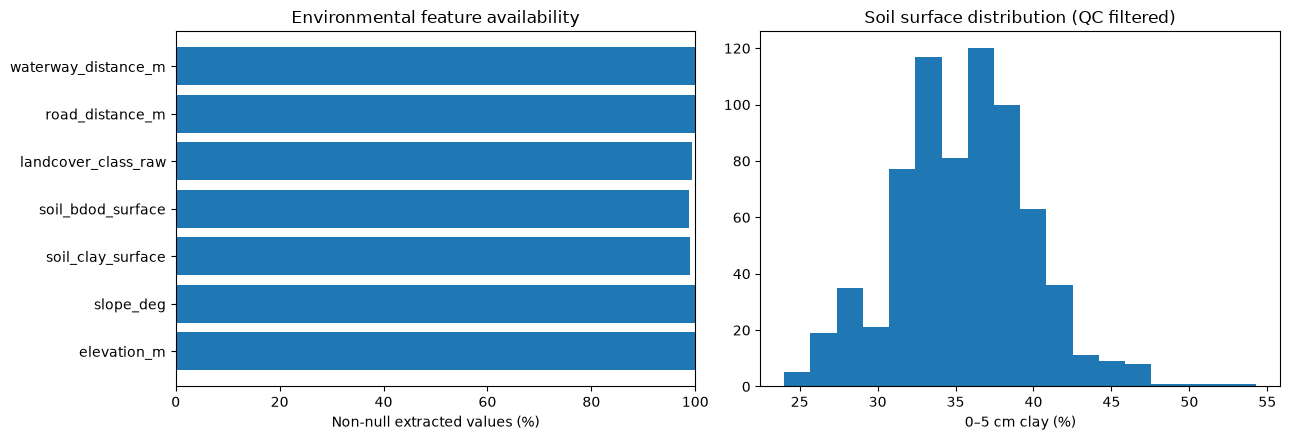

Saved four outputs (three CSV + one PNG):
C:\landslide_fyp\data\processed\features\environmental_features.csv
C:\landslide_fyp\outputs\audits\environmental_layer_audit.csv
C:\landslide_fyp\outputs\audits\environmental_feature_summary.csv
C:\landslide_fyp\outputs\figures\environmental_feature_overview.png


In [32]:
features.drop(columns=['event_dt'],errors='ignore').to_csv(FEATURE_OUT,index=False)
pd.DataFrame(audit).to_csv(AUDIT_OUT,index=False)
summary.to_csv(SUMMARY_OUT,index=False)
full=summary[summary.source=='ALL'].drop_duplicates(['feature']).set_index('feature')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
selected=['elevation_m','slope_deg','soil_clay_surface','soil_bdod_surface','landcover_class_raw','road_distance_m','waterway_distance_m']
axes[0].barh(selected,[float(features[c].notna().mean()*100) for c in selected]);axes[0].set_xlim(0,100)
axes[0].set_xlabel('Non-null extracted values (%)');axes[0].set_title('Environmental feature availability')
if features.soil_clay_surface.notna().any():
    axes[1].hist(features.soil_clay_surface.dropna(),bins=18)
    axes[1].set_xlabel('0–5 cm clay (%)')
else:axes[1].text(.5,.5,'No validated soil values',ha='center',va='center',transform=axes[1].transAxes)
axes[1].set_title('Soil surface distribution (QC filtered)')
fig.tight_layout();fig.savefig(FIG_OUT,dpi=160);plt.show()
print('Saved four outputs (three CSV + one PNG):',FEATURE_OUT,AUDIT_OUT,SUMMARY_OUT,FIG_OUT,sep='\n')

### 10A. Optional historical vegetation, forest-loss, runoff and hydroterrain exploration (case + matched controls)

**Separate enhancement stage; do not rerun Section 6.0A or original Notebook 02.** This code reads the two existing Notebook 03 modelling CSV files, deduplicates shared sample IDs, and generates a **separate sidecar** (`data/processed/features/historical_environmental_enhancement.csv`). It does **not** change the original landslide inventory, controls, `environmental_features.csv`, or the original modelling CSVs.

Use `RUN_ENHANCEMENT=True`, `ENHANCEMENT_MODE='pilot'` first (approximately 12 case-control groups across years and regions). Once the pilot/source audit is acceptable, change mode to `'full'`, keeping the same checkpoint. The Earth Engine cloud service must be available on your computer. A source-dependent masked or unavailable value stays missing, never zero-filled silently. All group controls use their own coordinates and the same `reference_date` as their parent case. The absence of precise dates is distinguished from valid calendar years.

**Definitions:** `ndvi_pre_event`: annual composite for year *Y−1*; `ndvi_change_2y`: NDVI(Y−1) minus NDVI(Y−3), with both complete annual periods; `forest_loss_5y_250m_pct`: 2000 baseline forest pixels (tree cover ≥30%) with detected gross loss in years Y−5..Y−1 / 2000 baseline forest area in a 250 m circle, ×100; `runoff_7d_mm`/`runoff_30d_mm`: ERA5-Land `surface_runoff_sum` over [event−N days, event) multiplied by 1000; `merit_upstream_area_km2`/`merit_hand_m` are ~90 m exploratory hydrotopography. **TWI and profile curvature are deliberately not assigned unverified values:** those require a separate hydrologically and geomorphometrically validated raster workflow.

**Caution:** Landsat annual compositing uses a recent valid pixel; some dates and locations may be cloudy. Hansen gross loss is not a complete regrowth history and year-of-loss is approximate. MERIT terrain layers are not dynamic. These features are experiments only, not approved predictors. Year-specific vegetation features make the static branch historically indexed rather than strictly time-invariant.


In [33]:
# Enhancement stage ONLY: no original environmental features or modelling CSV overwrite.
# Use this cell after the Notebook 02 configuration cell, without re-running expensive earlier extraction.
from pathlib import Path
import pandas as pd, numpy as np, json, hashlib, time
from IPython.display import display

RUN_ENHANCEMENT = False      # Safety default: do not re-fetch completed 1,982-sample extraction
ENHANCEMENT_MODE = 'full'    # 'pilot' (12 groups) or 'full'
ENHANCEMENT_PILOT_GROUPS = 12
ENHANCEMENT_BATCH_SIZE = 30  # conservative Earth Engine calls
ENHANCEMENT_EE_RETRIES = 3
ENHANCEMENT_FOREST_BASELINE_MIN_TREECOVER = 30
ENHANCEMENT_PIPELINE_VERSION = 'histenv_ndvi_hansen_runoff_merit_v1'

ENH_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 if (p/'data'/'processed'/'modelling'/'static_model_dataset.csv').exists()), None)
if ENH_ROOT is None:
    raise FileNotFoundError('Expected data/processed/modelling/static_model_dataset.csv within your FYP project.')
ENH_DIR = ENH_ROOT/'data'/'processed'/'features'
ENH_AUDIT_DIR = ENH_ROOT/'outputs'/'audits'
ENH_DIR.mkdir(parents=True, exist_ok=True)
ENH_AUDIT_DIR.mkdir(parents=True, exist_ok=True)
ENH_OUT = ENH_DIR/'historical_environmental_enhancement.csv'
ENH_CACHE = ENH_DIR/'.historical_environmental_enhancement_checkpoint.csv'
ENH_AUDIT = ENH_AUDIT_DIR/'historical_environmental_enhancement_audit.csv'
ENH_QC = ENH_AUDIT_DIR/'historical_environmental_enhancement_completeness.csv'
ENH_FEATURES = ['ndvi_pre_event','ndvi_change_2y','forest_loss_5y_250m_pct',
                'runoff_7d_mm','runoff_30d_mm','merit_upstream_area_km2','merit_hand_m']

st = pd.read_csv(ENH_ROOT/'data/processed/modelling/static_model_dataset.csv',low_memory=False)
tm = pd.read_csv(ENH_ROOT/'data/processed/modelling/temporal_model_dataset.csv',low_memory=False)
required = {'sample_id','matched_event_id','target','latitude','longitude','reference_date'}
for name,d in [('static',st),('temporal',tm)]:
    if required-set(d.columns):raise ValueError(f'{name} columns missing: {required-set(d.columns)}')
    if d.sample_id.duplicated().any():raise ValueError(f'{name}: duplicate sample_id detected')
all_rows = pd.concat([st.assign(_branch='static'),tm.assign(_branch='temporal')],ignore_index=True)
for sid,g in all_rows.groupby('sample_id'):
    if g[['longitude','latitude','reference_date','target','matched_event_id']].astype('string').fillna('MISSING').drop_duplicates().shape[0]!=1:
        raise ValueError(f'Shared static/temporal sample has conflicting fields: {sid}')
records = all_rows.drop_duplicates('sample_id').copy().reset_index(drop=True)
records['_year'] = pd.to_numeric(records.get('reference_year', pd.Series(index=records.index,dtype=float)),errors='coerce')
records['_date'] = pd.to_datetime(records.reference_date,errors='coerce')
records['_year'] = records['_year'].fillna(records['_date'].dt.year).astype('Int64')
# Only verified day-precision source dates are eligible for event-day runoff.
# Parsing a year-only source as January 1 is prohibited.
if 'date_precision' in records:
    dayok = records.date_precision.astype(str).str.lower().eq('day')
else:
    # Temporal modelling cohort was filtered for event-day eligibility in Notebook 03.
    # Static-only samples must not gain hydrology eligibility from a date-shaped string.
    dayok = (records.sample_id.isin(set(tm.sample_id.astype(str))) &
             records.reference_date.astype(str).str.fullmatch(r'\d{4}-\d{2}-\d{2}'))
records['_day_eligible'] = dayok.fillna(False) & records['_date'].notna()
# Shared event date must match its sampled controls.
for gid,g in records.groupby('matched_event_id',dropna=False):
    if g.target.eq(1).sum()!=1 or not (2<=g.target.eq(0).sum()<=3):
        # Some static/temporal groups selected DIFFERENT second control IDs.
        # Union may contain 3 controls although each input branch has exactly 2.
        raise ValueError(f'Unexpected case/control union in group {gid}')
    if g.reference_date.astype('string').fillna('NA').nunique()!=1:
        raise ValueError(f'Inconsistent control reference dates: {gid}')
records['_key'] = records.apply(lambda r: hashlib.sha256(
    (ENHANCEMENT_PIPELINE_VERSION+'|'+str(r['sample_id'])+'|'+str(r['reference_date'])+'|'+
     f'{float(r.longitude):.7f}|{float(r.latitude):.7f}').encode()).hexdigest(),axis=1)
if ENHANCEMENT_MODE == 'pilot':
    groups = (records.loc[records.target.eq(1),['matched_event_id','_year','longitude']]
              .assign(_decade=lambda x:(x._year.fillna(0)//10)*10,
                      _region=lambda x:np.where(x.longitude<108,'West','East'))
              .sort_values(['_decade','_region','matched_event_id'])
              .groupby(['_decade','_region'],dropna=False).head(3)
              .head(ENHANCEMENT_PILOT_GROUPS))
    selected = records[records.matched_event_id.isin(groups.matched_event_id)].copy()
elif ENHANCEMENT_MODE == 'full':
    selected = records.copy()
else:raise ValueError('ENHANCEMENT_MODE must be pilot or full')

print('Unique sample IDs:',len(records),'selected:',len(selected),'pilot/full:',ENHANCEMENT_MODE)
print('Year-eligible:',int(selected._year.notna().sum()),
      'day-eligible:',int(selected._day_eligible.sum()))

if RUN_ENHANCEMENT:
    import ee
    try:ee.Initialize(project=EE_PROJECT_ID)
    except Exception as err:raise RuntimeError('Initialize Earth Engine or verify EE_PROJECT_ID before running.') from err

    cache = pd.read_csv(ENH_CACHE,low_memory=False) if ENH_CACHE.exists() else pd.DataFrame()
    cache = cache.drop_duplicates('_key',keep='last') if not cache.empty else cache
    done = set(cache.loc[cache.get('fetch_status',pd.Series(index=cache.index,dtype=str)).eq('OK'),'_key']) if not cache.empty else set()
    pending = selected.loc[~selected._key.isin(done)].copy()
    print('Previously completed:',len(selected)-len(pending),'pending:',len(pending))

    annual_ndvi = ee.ImageCollection('LANDSAT/COMPOSITES/C02/T1_L2_ANNUAL_NDVI')
    hansen = ee.Image('UMD/hansen/global_forest_change_2025_v1_13')
    era5 = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
    merit = ee.Image('MERIT/Hydro/v1_0_1')

    def fc_for(batch):
        return ee.FeatureCollection([
            ee.Feature(ee.Geometry.Point([float(r['longitude']),float(r['latitude'])]),{'_key':str(r['_key'])})
            for r in batch.to_dict('records')
        ])
    def fetch(fc,img,scale,selectors):
        # sampling at an image-native scale; missing pixel -> null, not 0.
        # geometries false avoids transmitting coordinates again.
        # Important: sampleRegions drops a point if ANY requested band is masked.
        # Unmask each band to a sentinel ONLY in the temporary sampling image,
        # then convert the sentinel back to None; it never enters the dataset.
        sentinel = -999999.0
        res=img.select(selectors).unmask(sentinel).sampleRegions(
            collection=fc,properties=['_key'],scale=scale,
            geometries=False,tileScale=4).getInfo()
        found={x['properties']['_key']:x['properties'] for x in res.get('features',[])}
        return {k:{c:(None if props.get(c) in (None,sentinel) else props.get(c))
                   for c in selectors} for k,props in found.items()}
    def request_with_retry(callback):
        for attempt in range(ENHANCEMENT_EE_RETRIES):
            try:return callback()
            except Exception:
                if attempt==ENHANCEMENT_EE_RETRIES-1:raise
                time.sleep(min(12,2**(attempt+1)))
    def save_rows(rows):
        df=pd.DataFrame(rows)
        older=pd.read_csv(ENH_CACHE,low_memory=False) if ENH_CACHE.exists() else pd.DataFrame()
        pd.concat([older,df],ignore_index=True).drop_duplicates('_key',keep='last').to_csv(ENH_CACHE,index=False)

    # Year-eligible annual NDVI + forest loss, and static MERIT.
    # Keys in a failed batch are never marked OK: rerunning resumes them.
    successes=[]; failed=[]
    temporal_sample_ids=set(tm.sample_id.astype(str))
    for yr,group in pending.groupby('_year',dropna=False,sort=True):
        for start in range(0,len(group),ENHANCEMENT_BATCH_SIZE):
            batch=group.iloc[start:start+ENHANCEMENT_BATCH_SIZE].copy()
            fc=fc_for(batch)
            rowmap={str(r['_key']):{'_key':str(r['_key']),'sample_id':str(r['sample_id']),
                     'matched_event_id':str(r['matched_event_id']),'reference_date':str(r['reference_date']),
                     '_year':int(r['_year']) if pd.notna(r['_year']) else None,
                     'ndvi_source_year':(int(r['_year'])-1) if pd.notna(r['_year']) else None,
                     'ndvi_comparison_year':(int(r['_year'])-3) if pd.notna(r['_year']) else None,
                     'forest_window_start_year':(int(r['_year'])-5) if pd.notna(r['_year']) else None,
                     'forest_window_end_year':(int(r['_year'])-1) if pd.notna(r['_year']) else None,
                     'runoff_window_end_exclusive':str(r['reference_date']) if str(r['sample_id']) in temporal_sample_ids else None,
                     'source_ndvi':'LANDSAT/COMPOSITES/C02/T1_L2_ANNUAL_NDVI',
                     'source_forest':'UMD/hansen/global_forest_change_2025_v1_13',
                     'source_runoff':'ECMWF/ERA5_LAND/DAILY_AGGR:surface_runoff_sum',
                     'source_hydroterrain':'MERIT/Hydro/v1_0_1',
                     'fetch_status':'OK',**{f:np.nan for f in ENH_FEATURES}}
                    for r in batch.to_dict('records')}
            try:
                # MERIT local point value, irrespective of year.
                mer = request_with_retry(lambda:fetch(fc,merit.select(['upa','hnd']).rename(
                    ['merit_upstream_area_km2','merit_hand_m']),90,
                    ['merit_upstream_area_km2','merit_hand_m']))
                for k,props in mer.items():rowmap[k].update(props)
                if pd.notna(yr):
                    y=int(yr)
                    if 1987<=y<=2026 and 1984<=y-3 and y-1<=2025:
                        def annual_image(year):
                            col=annual_ndvi.filterDate(f'{year}-01-01',f'{year+1}-01-01').select('NDVI')
                            return ee.Image(col.mosaic()).rename('NDVI')
                        current=annual_image(y-1)
                        previous=annual_image(y-3)
                        ndvi=current.rename('ndvi_pre_event').addBands(
                            current.subtract(previous).rename('ndvi_change_2y'))
                        nd = request_with_retry(lambda:fetch(fc,ndvi,30,['ndvi_pre_event','ndvi_change_2y']))
                        for k,props in nd.items():rowmap[k].update(props)
                    if y>=2006 and y<=2026 and y-1<=2025:
                        lo=y-5-2000;hi=y-1-2000
                        # Valid only where baseline tree cover exists; numerator is 5y gross loss.
                        # Pixel area sums computed independently per 250m circle.
                        base=hansen.select('treecover2000').gte(ENHANCEMENT_FOREST_BASELINE_MIN_TREECOVER)
                        loss=base.And(hansen.select('lossyear').gte(lo)).And(
                            hansen.select('lossyear').lte(hi))
                        areas=loss.multiply(ee.Image.pixelArea()).rename('lost_area').addBands(
                            base.multiply(ee.Image.pixelArea()).rename('forest_area'))
                        buffers=ee.FeatureCollection([ee.Feature(ee.Geometry.Point(
                            [float(r['longitude']),float(r['latitude'])]).buffer(250),{'_key':str(r['_key'])})
                            for r in batch.to_dict('records')])
                        sums=request_with_retry(lambda:areas.reduceRegions(
                            collection=buffers,reducer=ee.Reducer.sum(),scale=30,tileScale=4).getInfo())
                        for obj in sums.get('features',[]):
                            prop=obj['properties'];k=prop['_key'];den=prop.get('forest_area');num=prop.get('lost_area')
                            if den is not None and den>0 and num is not None:
                                rowmap[k]['forest_loss_5y_250m_pct']=100*float(num)/float(den)
                # Daily surface runoff: per reference day, no same-event-date assumption for the whole batch.
                for day,g in batch.loc[batch._day_eligible].groupby('_date'):
                    end=ee.Date(day.strftime('%Y-%m-%d'))
                    dayfc=fc_for(g)
                    def runoff_img(days):
                        coll=era5.filterDate(end.advance(-days,'day'),end).select('surface_runoff_sum')
                        return coll.sum().multiply(1000).rename(f'runoff_{days}d_mm')
                    runoff=runoff_img(7).addBands(runoff_img(30))
                    rv=request_with_retry(lambda:fetch(dayfc,runoff,11132,['runoff_7d_mm','runoff_30d_mm']))
                    for k,props in rv.items():rowmap[k].update(props)
                save_rows(list(rowmap.values()))
                successes += list(rowmap.values())
            except Exception as exc:
                failed.append({'year':str(yr),'sample_ids':'|'.join(batch.sample_id.astype(str)),
                               'error':str(exc)[:500]})
                print('Batch failure (not marked completed):',str(exc)[:180],flush=True)
            print('Year',yr,'batch',start//ENHANCEMENT_BATCH_SIZE+1,
                  'success so far',len(successes),'failed batches',len(failed),flush=True)
    # Save merged current-sidecar only for actually completed keys; original model CSVs remain unmodified.
    cache=pd.read_csv(ENH_CACHE,low_memory=False)
    cache=cache.drop_duplicates('_key',keep='last')
    chosen=records[['sample_id','_key']].merge(cache.drop(columns=['sample_id'],errors='ignore'),
        on='_key',how='inner',validate='one_to_one')
    chosen.to_csv(ENH_OUT,index=False)
    pd.DataFrame(failed,columns=['year','sample_ids','error']).to_csv(ENH_AUDIT,index=False)
    qc=chosen[ENH_FEATURES].apply(pd.to_numeric,errors='coerce')
    print('Completed sidecar rows:',len(chosen),'of',len(records),'unique samples')
    display(pd.DataFrame({'feature':ENH_FEATURES,'nonmissing':qc.notna().sum().values,
                          'fraction_available':qc.notna().mean().values,
                          'minimum':qc.min().values,'maximum':qc.max().values}).round(3))
    checks={
      'ndvi_pre_event':(-1,1),'ndvi_change_2y':(-2,2),
      'forest_loss_5y_250m_pct':(0,100),
      'runoff_7d_mm':(0,np.inf),'runoff_30d_mm':(0,np.inf),
      'merit_upstream_area_km2':(0,np.inf),'merit_hand_m':(-1000,20000)
    }
    rows=[]
    for col,(low,high) in checks.items():
        x=qc[col]
        rows.append({'feature':col,'rows':len(x),'available':int(x.notna().sum()),
                     'missing':int(x.isna().sum()),'invalid_range_count':int(((x<low)|(x>high)).sum()),
                     'min':x.min(),'median':x.median(),'max':x.max()})
    pd.DataFrame(rows).to_csv(ENH_QC,index=False)
    print('Sidecar:',ENH_OUT,'QC:',ENH_QC)
else:
    print('Enhancement disabled. Set RUN_ENHANCEMENT=True to execute ONLY this cell.')


Unique sample IDs: 1982 selected: 1982 pilot/full: full
Year-eligible: 1964 day-eligible: 1929
Enhancement disabled. Set RUN_ENHANCEMENT=True to execute ONLY this cell.


### 10B. Post-extraction provenance and missingness QA (read-only)

Run this cell **instead of rerunning Section 10A** after the full 1,982-sample enhancement. It reads existing sidecar/checkpoint and modelling CSVs, validates the stored historical date windows and matched case-control reference dates, separates successful API requests (`fetch_status=OK`) from the presence of valid feature pixels, and writes separate **audit-only** CSVs to `outputs/audits/`. It does not overwrite any inputs. Missing source pixels are **candidate explanations**, not confirmed causes until independently re-queried.

The optional `RUN_ENHANCEMENT_EE_SPOTCHECK=True` independently requests a limited number of source values using point `reduceRegion` instead of the original `sampleRegions`, and re-checks 250 m forest loss with numerator/denominator reporting. Earth Engine credentials are required only when enabled. Forest denominator warnings do not automatically invalidate a sample. Historical data may contain provenance limitations and the year of detected forest loss is not the precise clearing date.

**Important:** These QA outputs do not themselves establish improvements in model performance or permission to use data from after an event. Review abnormal cases and completeness before enabling Section 5K in Notebook 04.

In [34]:
# ============================================================
# 10B. Historical enhancement post-extraction quality audit
# LOCAL BY DEFAULT. NEVER modifies the enhancement checkpoint.
# Optional small independent Earth Engine spot-check: set True.
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

QA_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                if (p/'data/processed/features/historical_environmental_enhancement.csv').exists()), None)
if QA_ROOT is None:
    raise FileNotFoundError('Run inside the FYP project containing the completed enhancement CSV.')
QA_FEATURE_DIR = QA_ROOT/'data/processed/features'
QA_OUT = QA_ROOT/'outputs/audits'
QA_OUT.mkdir(parents=True, exist_ok=True)
QA_SIDECAR = QA_FEATURE_DIR/'historical_environmental_enhancement.csv'
QA_CHECKPOINT = QA_FEATURE_DIR/'.historical_environmental_enhancement_checkpoint.csv'
QA_FEATURES = ['ndvi_pre_event','ndvi_change_2y','forest_loss_5y_250m_pct',
               'runoff_7d_mm','runoff_30d_mm','merit_upstream_area_km2','merit_hand_m']

# These checks NEVER edit/re-fetch data automatically.
RUN_ENHANCEMENT_EE_SPOTCHECK = False
QA_SPOTCHECK_PER_FEATURE = 4
QA_FOREST_DENOMINATOR_MIN_M2 = 1000.0  # QC warning only; no imputation
QA_EE_PROJECT = globals().get('EE_PROJECT_ID','fyplandslide')

qa = pd.read_csv(QA_SIDECAR, low_memory=False)
cache = pd.read_csv(QA_CHECKPOINT, low_memory=False) if QA_CHECKPOINT.exists() else None
if qa['sample_id'].duplicated().any() or qa['_key'].duplicated().any():
    raise AssertionError('Duplicate sample_id or checkpoint key in sidecar.')
if cache is not None:
    if cache['_key'].duplicated().any():
        raise AssertionError('Duplicate checkpoint keys detected; inspect before editing.')
    if set(qa['_key']) != set(cache['_key']):
        print('WARNING: sidecar and checkpoint contain different sample keys.')

# Join only metadata from the existing modelling datasets. Protect identical IDs.
model_dir = QA_ROOT/'data/processed/modelling'
model_frames = []
for branch in ('static','temporal'):
    f = model_dir/f'{branch}_model_dataset.csv'
    if f.exists():
        d = pd.read_csv(f, low_memory=False)
        required = ['sample_id','latitude','longitude','matched_event_id','target','reference_date']
        if set(required)-set(d.columns):
            raise ValueError(f'{branch} missing columns {set(required)-set(d.columns)}')
        model_frames.append(d[required].assign(_branch=branch))
if not model_frames:
    raise FileNotFoundError('Both modelling inputs unavailable: need case/control coordinates for QA.')
model_rows = pd.concat(model_frames, ignore_index=True)
for sid, group in model_rows.groupby('sample_id', sort=False):
    if group[['latitude','longitude','target','matched_event_id','reference_date']].astype('string').fillna('MISSING').drop_duplicates().shape[0] != 1:
        raise ValueError(f'Conflicting static/temporal metadata for {sid}')
model_rows = model_rows.drop_duplicates('sample_id')
qa = qa.merge(model_rows.drop(columns=['_branch']), on='sample_id', how='left',
              suffixes=('','_model'), validate='one_to_one')
# Model metadata is the independent authority for case/control membership.
# Never allow a successful merge to silently accept unmatched identifiers.
if qa['matched_event_id'].isna().any() or qa['target'].isna().any():
    raise AssertionError('Some sidecar sample IDs are absent from the modelling inputs.')
if len(qa) != len(model_rows) or set(qa['sample_id'].astype(str)) != set(model_rows['sample_id'].astype(str)):
    raise AssertionError('Sidecar and modelling-union sample IDs disagree; review before model handover.')
for gid, group in qa.groupby('matched_event_id', dropna=False):
    targets = pd.to_numeric(group['target'], errors='coerce')
    if (targets.eq(1).sum() != 1 or not (2 <= targets.eq(0).sum() <= 3)
            or not targets.isin([0,1]).all()):
        raise AssertionError(f'Unexpected case/control membership in group {gid}')
# The reference year may be verified even if no exact day is available.
reference_year = pd.to_numeric(qa['reference_date'].astype('string').str.extract(r'^(\d{4})')[0], errors='coerce')
stored_year = pd.to_numeric(qa['_year'], errors='coerce')
year_conflict = reference_year.notna() & stored_year.notna() & reference_year.ne(stored_year)
if year_conflict.any():
    raise AssertionError(f'Sidecar reference year conflicts with reference date for {int(year_conflict.sum())} samples.')
if qa['latitude'].isna().any() or qa['longitude'].isna().any():
    raise ValueError('A sidecar sample lacks coordinates in modelling datasets.')
qa['_source'] = qa['matched_event_id'].astype('string').str.split(':', n=1).str[0]
qa['_class'] = np.where(pd.to_numeric(qa['target'],errors='coerce').eq(1),'landslide','background')
qa['_year_num'] = pd.to_numeric(qa['_year'], errors='coerce')
qa['_event_date'] = pd.to_datetime(qa['reference_date'], errors='coerce')
qa['_runoff_end'] = pd.to_datetime(qa['runoff_window_end_exclusive'],errors='coerce')

# Validate the saved historical provenance (window starts and ends).
valid_year = qa['_year_num'].notna()
for col, offset in [('ndvi_source_year',-1),('ndvi_comparison_year',-3),
                    ('forest_window_start_year',-5),('forest_window_end_year',-1)]:
    stored = pd.to_numeric(qa[col], errors='coerce')
    inconsistent = valid_year & stored.notna() & stored.ne(qa['_year_num']+offset)
    if inconsistent.any():
        raise AssertionError(f'{col} mismatches reference year for {int(inconsistent.sum())} samples.')
ends = qa['_runoff_end'].notna()
end_mismatches = ends & qa['_event_date'].ne(qa['_runoff_end'])
if end_mismatches.any():
    raise AssertionError('Some runoff windows end on a date other than their own reference date.')
# Date consistency of each case and its controls in union dataset.
for group_id, group in qa.groupby('matched_event_id', dropna=False):
    if group['reference_date'].astype('string').fillna('MISSING').nunique()!=1:
        raise AssertionError(f'Inconsistent case/control reference_date for {group_id}')

reason_rows = []
for feature in QA_FEATURES:
    vals = pd.to_numeric(qa[feature],errors='coerce').replace([np.inf,-np.inf],np.nan)
    for idx in qa.index:
        rec=qa.loc[idx]
        val=vals.loc[idx]
        yr=rec['_year_num']; eligible_day=pd.notna(rec['_runoff_end'])
        if pd.notna(val):
            reason='AVAILABLE'
        elif feature in ('merit_upstream_area_km2','merit_hand_m'):
            reason='MISSING_SOURCE_PIXEL_OR_EXTRACTION'
        elif pd.isna(yr):
            reason='NO_VERIFIED_YEAR'
        elif feature.startswith('ndvi'):
            if yr<1987 or yr>2026:
                reason='ANNUAL_COMPOSITE_YEARS_OUTSIDE_SUPPORTED_WINDOW'
            else:
                reason='MISSING_OR_MASKED_LANDSAT_PIXEL_OR_COMPOSITE'
        elif feature=='forest_loss_5y_250m_pct':
            if yr<2006 or yr>2026:
                reason='FIVE_YEAR_WINDOW_OUTSIDE_HANSEN_LOSS_COVERAGE'
            else:
                reason='SOURCE_MASK_OR_ZERO_BASELINE_FOREST_AREA_OR_EXTRACTION'
        else:  # runoff
            if not eligible_day:
                reason='DAY_PRECISION_INELIGIBLE_OR_WINDOW_NOT_REQUESTED'
            else:
                reason='DATE_ELIGIBLE_BUT_NO_ERA5_PIXEL_OR_EXTRACTION'
        reason_rows.append({'sample_id':rec['sample_id'],'matched_event_id':rec['matched_event_id'],
                            'source':rec['_source'],'sample_class':rec['_class'],
                            'reference_date':rec['reference_date'],'reference_year':yr,
                            'feature':feature,'value':val,'reason':reason})
reasons=pd.DataFrame(reason_rows)
reasons.to_csv(QA_OUT/'historical_feature_missing_reasons.csv',index=False)
reason_summary=(reasons.groupby(['feature','reason'],dropna=False).size()
                .rename('samples').reset_index().sort_values(['feature','samples'],ascending=[True,False]))
reason_summary.to_csv(QA_OUT/'historical_feature_missing_reason_summary.csv',index=False)
source_class=(reasons.assign(available=lambda d:d['reason'].eq('AVAILABLE'))
              .groupby(['source','sample_class','feature'],dropna=False)
              .agg(total=('available','size'),available=('available','sum'))
              .reset_index())
source_class['missing_pct']=(1-source_class.available/source_class.total)*100
source_class.to_csv(QA_OUT/'historical_feature_source_class_audit.csv',index=False)

missing_runoff=qa.loc[qa['runoff_7d_mm'].isna() | qa['runoff_30d_mm'].isna()].copy()
missing_runoff['runoff_reason']=np.where(missing_runoff['_runoff_end'].notna(),
    'DATE_ELIGIBLE_BUT_MISSING','DAY_INELIGIBLE_OR_NOT_REQUESTED')
missing_runoff[['sample_id','matched_event_id','latitude','longitude','reference_date','_year',
                'runoff_window_end_exclusive','runoff_7d_mm','runoff_30d_mm','runoff_reason']].to_csv(
                    QA_OUT/'historical_runoff_missing_review.csv',index=False)
ndvi_2021=qa.loc[qa['_year_num'].eq(2021) & (qa['ndvi_pre_event'].isna() | qa['ndvi_change_2y'].isna())]
ndvi_2021[['sample_id','matched_event_id','latitude','longitude','reference_date',
           'ndvi_source_year','ndvi_comparison_year','ndvi_pre_event','ndvi_change_2y']].to_csv(
               QA_OUT/'historical_2021_ndvi_missing_review.csv',index=False)

# Local checks: paired temporal values, forest percentage extremes, and matching dates.
run7=pd.to_numeric(qa.runoff_7d_mm,errors='coerce')
run30=pd.to_numeric(qa.runoff_30d_mm,errors='coerce')
inconsistent_runoff=qa.loc[run7.notna() & run30.notna() & ((run30+1e-5 < run7) | (run7 < -1e-5))]
forest=pd.to_numeric(qa.forest_loss_5y_250m_pct,errors='coerce')
forest_extremes=qa.loc[forest.ge(90)].copy()
forest_extremes[['sample_id','matched_event_id','latitude','longitude','_year',
                 'forest_loss_5y_250m_pct']].to_csv(QA_OUT/'historical_forest_high_fraction_review.csv',index=False)
if len(inconsistent_runoff):
    print('WARNING: anomalous runoff totals:',len(inconsistent_runoff))
# A batch-level OK is not a feature-level validity flag.
if qa[QA_FEATURES].apply(pd.to_numeric,errors='coerce').isin([np.inf,-np.inf]).any().any():
    raise AssertionError('Infinite environmental values detected.')
invalid_ranges = {
    'ndvi_pre_event':(-1,1), 'ndvi_change_2y':(-2,2),
    'forest_loss_5y_250m_pct':(0,100),
    'runoff_7d_mm':(0,np.inf), 'runoff_30d_mm':(0,np.inf),
    'merit_upstream_area_km2':(0,np.inf), 'merit_hand_m':(-1000,20000)
}
for feature, (low, high) in invalid_ranges.items():
    values = pd.to_numeric(qa[feature],errors='coerce')
    bad = values.notna() & ~values.between(low-1e-6, high+1e-6)
    if bad.any():
        raise AssertionError(f'{feature} has {int(bad.sum())} values outside the expected range.')
print('Rows:',len(qa),'| Checkpoint OK:',int(qa.fetch_status.eq('OK').sum()))
print('Missing runoff with stored eligible day:',int(missing_runoff._runoff_end.notna().sum()))
print('Missing NDVI in reference year 2021:',len(ndvi_2021))
print('Forest-loss >=90% (check baseline denominator with EE):',len(forest_extremes))
display(reason_summary)

# ============================================================
# OPTIONAL: independent Earth Engine spot checks using
# reduceRegion (original enhancement used sampleRegions/reduceRegions).
# These calls are READ-ONLY and do not overwrite the sidecar.
# ============================================================
if RUN_ENHANCEMENT_EE_SPOTCHECK:
    import ee
    ee.Initialize(project=QA_EE_PROJECT)
    annual=ee.ImageCollection('LANDSAT/COMPOSITES/C02/T1_L2_ANNUAL_NDVI')
    hansen=ee.Image('UMD/hansen/global_forest_change_2025_v1_13')
    era=ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
    merit=ee.Image('MERIT/Hydro/v1_0_1')
    spot=[]
    def pick_rows(subset,n):
        if subset.empty:return subset
        return subset.sort_values('sample_id').iloc[np.linspace(0,len(subset)-1,min(n,len(subset)),dtype=int)]
    checks=[('ndvi_pre_event',qa.loc[qa.ndvi_pre_event.notna() & qa._year_num.notna()]),
            ('ndvi_pre_event_missing_2021',ndvi_2021),
            ('runoff_7d_mm_missing',qa.loc[qa.runoff_7d_mm.isna() & qa._runoff_end.notna()]),
            ('runoff_7d_mm',qa.loc[qa.runoff_7d_mm.notna() & qa._runoff_end.notna()]),
            ('forest_loss_5y_250m_pct',qa.loc[forest.notna() & qa._year_num.ge(2006)]),
            ('forest_high_fraction',forest_extremes)]
    for group_name,pool in checks:
        for _,r in pick_rows(pool,QA_SPOTCHECK_PER_FEATURE).iterrows():
            p=ee.Geometry.Point([float(r.longitude),float(r.latitude)])
            observed=np.nan
            detail='';denominator=np.nan; numerator=np.nan
            try:
                if group_name.startswith('ndvi'):
                    y=int(r._year_num)-1
                    image=annual.filterDate(f'{y}-01-01',f'{y+1}-01-01').select('NDVI').mosaic()
                    observed=image.reduceRegion(ee.Reducer.first(),p,scale=30,maxPixels=100000).get('NDVI').getInfo()
                    stored=r.ndvi_pre_event
                elif group_name.startswith('runoff'):
                    end=ee.Date(pd.Timestamp(r._runoff_end).strftime('%Y-%m-%d'))
                    image=era.filterDate(end.advance(-7,'day'),end).select('surface_runoff_sum').sum().multiply(1000)
                    observed=image.reduceRegion(ee.Reducer.first(),p,scale=11132,maxPixels=100000).get('surface_runoff_sum').getInfo()
                    stored=r.runoff_7d_mm
                else:
                    y=int(r._year_num); lo=y-5-2000; hi=y-1-2000
                    baseline=hansen.select('treecover2000').gte(30)
                    loss=baseline.And(hansen.select('lossyear').gte(lo)).And(hansen.select('lossyear').lte(hi))
                    region=p.buffer(250)
                    sums=loss.multiply(ee.Image.pixelArea()).rename('loss_area').addBands(
                        baseline.multiply(ee.Image.pixelArea()).rename('forest_area')).reduceRegion(
                            reducer=ee.Reducer.sum(),geometry=region,scale=30,maxPixels=100000).getInfo()
                    numerator=sums.get('loss_area');denominator=sums.get('forest_area')
                    observed=(100*numerator/denominator if numerator is not None and denominator is not None and denominator>0 else np.nan)
                    stored=r.forest_loss_5y_250m_pct
                    if pd.notna(denominator) and denominator<QA_FOREST_DENOMINATOR_MIN_M2:
                        detail='SMALL_BASELINE_FOREST_DENOMINATOR'
                spot.append({'group':group_name,'sample_id':r.sample_id,'stored':stored,
                             'independent':observed,'abs_error':abs(float(stored)-float(observed))
                                if pd.notna(stored) and observed is not None and pd.notna(observed) else np.nan,
                             'baseline_forest_area_m2':denominator,'lost_area_m2':numerator,
                             'flag':detail,'query_status':'OK'})
            except Exception as exc:
                spot.append({'group':group_name,'sample_id':r.sample_id,'stored':r.get(group_name,np.nan),
                             'independent':np.nan,'abs_error':np.nan,'baseline_forest_area_m2':np.nan,
                             'lost_area_m2':np.nan,'flag':str(exc)[:250],'query_status':'ERROR'})
        print('Spot-check group complete:',group_name,flush=True)
    spot_df=pd.DataFrame(spot)
    spot_df.to_csv(QA_OUT/'historical_environmental_independent_spotcheck.csv',index=False)
    display(spot_df)
else:
    print('Optional independent Earth Engine spot-check OFF. Set RUN_ENHANCEMENT_EE_SPOTCHECK=True when ready.')

print('Completed local QA. External source-pixel causes remain unverified without independent EE checks.')


Rows: 1982 | Checkpoint OK: 1982
Missing runoff with stored eligible day: 23
Missing NDVI in reference year 2021: 55
Forest-loss >=90% (check baseline denominator with EE): 15


,feature,reason,samples
0,forest_loss_5y_250m_pct,AVAILABLE,1906
3,forest_loss_5y_250m_pct,SOURCE_MASK_OR_ZERO_BASELINE_FOREST_AREA_OR_EX...,40
1,forest_loss_5y_250m_pct,FIVE_YEAR_WINDOW_OUTSIDE_HANSEN_LOSS_COVERAGE,18
2,forest_loss_5y_250m_pct,NO_VERIFIED_YEAR,18
4,merit_hand_m,AVAILABLE,1982
5,merit_upstream_area_km2,AVAILABLE,1982
6,ndvi_change_2y,AVAILABLE,1846
7,ndvi_change_2y,MISSING_OR_MASKED_LANDSAT_PIXEL_OR_COMPOSITE,118
8,ndvi_change_2y,NO_VERIFIED_YEAR,18
9,ndvi_pre_event,AVAILABLE,1846


Optional independent Earth Engine spot-check OFF. Set RUN_ENHANCEMENT_EE_SPOTCHECK=True when ready.
Completed local QA. External source-pixel causes remain unverified without independent EE checks.


### 10C. Targeted source-level recovery and extreme forest-loss verification (optional)

**Run after 10B**. This step is **off by default**, never reprocesses the complete 1,982-sample cohort, and does **not overwrite** the original enhancement CSV, checkpoint, Notebook 03 datasets or existing model outputs. Set `RUN_TARGETED_EE_QA=True` only after authenticating Earth Engine. Default limits check up to 12 NDVI gaps (prioritising the independently recoverable example), 8 runoff gaps, and all 15 high forest-loss observations; increase limits deliberately in later passes. An audit file records the original values, independent per-band observations, source image counts, masks, historical windows and any proposed recovery. Candidate values go into a **separate reviewed sidecar** and are *not adopted automatically* for Notebook 04. For runoff, this uses the original point and reduction scale rather than an arbitrary replacement pixel.

The file `historical_environmental_independent_spotcheck.csv` from 10B is kept untouched. Confirm new records using the audit and validate the candidate sidecar before incorporating changes in downstream experiments.


In [35]:
# ============================================================
# 10C. OPTIONAL bounded historical source QA / recovery
# Original sidecar, checkpoint, modelling datasets and models untouched.
# ============================================================
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

RUN_TARGETED_EE_QA = True  # Set False after successful verification
TARGET_NDVI_MAX = 20
TARGET_RUNOFF_MAX = 15
TARGET_FOREST_MAX = 15
TARGET_FOREST_MISSING_MAX = 20
TARGET_PRIORITIZED_NDVI = 'ctrl:JMG_original:00031:2'
TARGET_FOREST_MIN_DENOM_M2 = 1000.0  # Warning threshold only

T_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
               if (p / 'data/processed/features/historical_environmental_enhancement.csv').is_file()
               and (p / 'data/processed/modelling/static_model_dataset.csv').is_file()), None)
if T_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the FYP project.')
T_FEATURES = T_ROOT / 'data/processed/features'
T_AUDITS = T_ROOT / 'outputs/audits'
T_AUDITS.mkdir(parents=True, exist_ok=True)
T_SOURCE = T_FEATURES / 'historical_environmental_enhancement.csv'
T_AUDIT_OUT = T_AUDITS / 'historical_targeted_source_verification.csv'
T_RECOVERY_OUT = T_FEATURES / 'historical_environmental_enhancement_recovery_REVIEW.csv'
T_BEFORE_AFTER = T_AUDITS / 'historical_targeted_before_after_completeness.csv'
T_FLAGS = T_AUDITS / 'historical_targeted_verification_summary.csv'
T_COLS = ['ndvi_pre_event', 'ndvi_change_2y', 'forest_loss_5y_250m_pct',
          'runoff_7d_mm', 'runoff_30d_mm', 'merit_upstream_area_km2', 'merit_hand_m']

source = pd.read_csv(T_SOURCE, low_memory=False)
static = pd.read_csv(T_ROOT / 'data/processed/modelling/static_model_dataset.csv', low_memory=False)
temporal = pd.read_csv(T_ROOT / 'data/processed/modelling/temporal_model_dataset.csv', low_memory=False)
if source.sample_id.duplicated().any():
    raise AssertionError('Duplicate enhancement sample IDs.')
union = pd.concat([static, temporal], ignore_index=True)
for sid, g in union.groupby('sample_id', sort=False):
    for c in ['latitude', 'longitude', 'reference_date', 'matched_event_id', 'target']:
        if g[c].astype('string').fillna('<NA>').nunique() != 1:
            raise AssertionError(f'Conflicting {c} for shared sample {sid}')
union = union.drop_duplicates('sample_id')
if set(source.sample_id.astype(str)) != set(union.sample_id.astype(str)):
    raise AssertionError('Source and modelling sample keys differ.')
extra = union[['sample_id', 'latitude', 'longitude', 'target']].copy()

# Resume from cumulative review; never replace earlier verified recoveries.
if T_RECOVERY_OUT.exists():
    review = pd.read_csv(T_RECOVERY_OUT, low_memory=False)
    if not review.columns.equals(source.columns) or not review.sample_id.equals(source.sample_id):
        raise AssertionError('Existing review columns or sample order differ from source.')
    for c in source.columns:
        if c in T_COLS:
            existing = source[c].notna()
            if not source.loc[existing, c].equals(review.loc[existing, c]):
                raise AssertionError(f'Original feature altered in recovery review: {c}')
        elif not source[c].equals(review[c]):
            raise AssertionError(f'Non-feature provenance altered in recovery review: {c}')
else:
    review = source.copy()

previous_checks = (pd.read_csv(T_AUDIT_OUT, low_memory=False)
                   if T_AUDIT_OUT.exists() else pd.DataFrame())
checked = set()
if not previous_checks.empty:
    needed = {'sample_id', 'source_group', 'status'}
    if not needed.issubset(previous_checks.columns):
        raise AssertionError(f'Previous verification CSV missing: {needed - set(previous_checks.columns)}')
    good = previous_checks.loc[previous_checks.status.astype(str).eq('OK')]
    checked = set(zip(good.sample_id.astype(str), good.source_group.astype(str)))

work = review.merge(extra, on='sample_id', validate='one_to_one')
year = pd.to_numeric(work['_year'], errors='coerce')
ndvi_pool = work.loc[(work.ndvi_pre_event.isna() | work.ndvi_change_2y.isna())
                     & year.between(1987, 2026) & (year - 1 <= 2025)].copy()
ndvi_pool = ndvi_pool.loc[~ndvi_pool.sample_id.astype(str).map(lambda s: (s, 'NDVI') in checked)]
ndvi_pool['_rank'] = ndvi_pool.sample_id.astype(str).ne(TARGET_PRIORITIZED_NDVI).astype(int)
ndvi_pool = ndvi_pool.sort_values(['_rank', 'sample_id']).head(TARGET_NDVI_MAX)

runoff_pool = work.loc[(work.runoff_7d_mm.isna() | work.runoff_30d_mm.isna())
                       & pd.to_datetime(work.runoff_window_end_exclusive, errors='coerce').notna()].copy()
runoff_pool = runoff_pool.loc[~runoff_pool.sample_id.astype(str).map(lambda s: (s, 'RUNOFF') in checked)]
runoff_pool = runoff_pool.sort_values('sample_id').head(TARGET_RUNOFF_MAX)

forest_pool = work.loc[pd.to_numeric(work.forest_loss_5y_250m_pct, errors='coerce').ge(90)].copy()
forest_pool = forest_pool.loc[~forest_pool.sample_id.astype(str).map(lambda s: (s, 'FOREST_EXTREME') in checked)]
forest_pool = forest_pool.sort_values('sample_id').head(TARGET_FOREST_MAX)
forest_missing_pool = work.loc[work.forest_loss_5y_250m_pct.isna()
                               & year.between(2006, 2026)].copy()
forest_missing_pool = forest_missing_pool.loc[
    ~forest_missing_pool.sample_id.astype(str).map(lambda s: (s, 'FOREST_MISSING') in checked)]
forest_missing_pool = forest_missing_pool.sort_values('sample_id').head(TARGET_FOREST_MISSING_MAX)
print('New source checks:', {'NDVI': len(ndvi_pool), 'RUNOFF': len(runoff_pool),
                             'FOREST_EXTREME': len(forest_pool), 'FOREST_MISSING': len(forest_missing_pool)})

def safe_value(v, lo=-np.inf, hi=np.inf):
    try:
        f = float(v)
        return f if np.isfinite(f) and lo - 1e-9 <= f <= hi + 1e-9 else np.nan
    except (ValueError, TypeError, OverflowError):
        return np.nan

def completeness_report(before, after):
    return pd.DataFrame([{'feature': c, 'before_nonmissing': int(before[c].notna().sum()),
                          'after_nonmissing': int(after[c].notna().sum()),
                          'recovered': int(after[c].notna().sum() - before[c].notna().sum())}
                         for c in T_COLS])


if RUN_TARGETED_EE_QA:
    import ee

    # Use the existing FYP Earth Engine Cloud Project.
    # Section 10C can now run independently of Section 10B.
    EE_PROJECT = (
        globals().get('EE_PROJECT_ID')
        or globals().get('QA_EE_PROJECT')
        or 'fyplandslide'
    )

    try:
        ee.Initialize(project=EE_PROJECT)
        print(f'Google Earth Engine initialized: {EE_PROJECT}')

    except Exception as exc:
        raise RuntimeError(
            f'Earth Engine initialization failed for project '
            f'{EE_PROJECT}. Verify your authentication and '
            f'Cloud Project permissions.'
        ) from exc

    # Existing environmental data sources.
    annual = ee.ImageCollection(
        'LANDSAT/COMPOSITES/C02/T1_L2_ANNUAL_NDVI'
    )

    era = ee.ImageCollection(
        'ECMWF/ERA5_LAND/DAILY_AGGR'
    )

    hansen = ee.Image(
        'UMD/hansen/global_forest_change_2025_v1_13'
    )

    proposed = review.set_index('sample_id').copy()
    original = source.set_index('sample_id')
    audit = []

    def point_band(img, band, point, scale):
        sampled = img.select([band]).addBands(
            img.select([band]).mask().rename('pixel_valid')
        ).reduceRegion(reducer=ee.Reducer.first(), geometry=point,
                       scale=scale, maxPixels=100000).getInfo() or {}
        return sampled.get(band), sampled.get('pixel_valid')

    for _, r in ndvi_pool.iterrows():
        sid, yr = str(r.sample_id), int(r['_year'])
        entry = {'sample_id': sid, 'source_group': 'NDVI', 'status': 'OK', 'year': yr,
                 'historical_start': f'{yr-3}-01-01', 'historical_end_exclusive': f'{yr}-01-01',
                 'y1_count': np.nan, 'y3_count': np.nan, 'y1_value': np.nan,
                 'y3_value': np.nan, 'y1_valid': np.nan, 'y3_valid': np.nan, 'note': ''}
        try:
            point = ee.Geometry.Point([float(r.longitude), float(r.latitude)])
            col1 = annual.filterDate(f'{yr-1}-01-01', f'{yr}-01-01').select('NDVI')
            col3 = annual.filterDate(f'{yr-3}-01-01', f'{yr-2}-01-01').select('NDVI')
            entry['y1_count'], entry['y3_count'] = int(col1.size().getInfo()), int(col3.size().getInfo())
            v1, m1 = point_band(col1.mosaic().rename('NDVI'), 'NDVI', point, 30) if entry['y1_count'] else (None, None)
            v3, m3 = point_band(col3.mosaic().rename('NDVI'), 'NDVI', point, 30) if entry['y3_count'] else (None, None)
            entry.update(y1_value=v1, y3_value=v3, y1_valid=m1, y3_valid=m3)
            n1, n3 = safe_value(v1, -1, 1), safe_value(v3, -1, 1)
            if pd.notna(n1) and pd.isna(proposed.at[sid, 'ndvi_pre_event']):
                proposed.at[sid, 'ndvi_pre_event'] = n1
            if pd.notna(n1) and pd.notna(n3) and pd.isna(proposed.at[sid, 'ndvi_change_2y']):
                proposed.at[sid, 'ndvi_change_2y'] = n1 - n3
            entry['note'] = ('BOTH_VALID' if pd.notna(n1) and pd.notna(n3)
                             else 'Y1_ONLY' if pd.notna(n1)
                             else 'Y3_ONLY' if pd.notna(n3) else 'BOTH_MASKED_OR_UNAVAILABLE')
        except Exception as exc:
            entry.update(status='ERROR', note=str(exc)[:300])
        audit.append(entry)

    for _, r in runoff_pool.iterrows():
        sid = str(r.sample_id)
        entry = {'sample_id': sid, 'source_group': 'RUNOFF', 'status': 'OK',
                 'historical_end_exclusive': str(r.runoff_window_end_exclusive),
                 'runoff_7d_mm': np.nan, 'runoff_30d_mm': np.nan, 'note': ''}
        try:
            point = ee.Geometry.Point([float(r.longitude), float(r.latitude)])
            end_date = pd.Timestamp(r.runoff_window_end_exclusive).strftime('%Y-%m-%d')
            end = ee.Date(end_date)
            entry['historical_end_exclusive'] = end_date
            for days in (7, 30):
                col = era.filterDate(end.advance(-days, 'day'), end).select('surface_runoff_sum')
                count = int(col.size().getInfo())
                entry[f'days_{days}_image_count'] = count
                valid_count, _ = point_band(col.count().rename('valid_days'), 'valid_days', point, 11132) if count else (None, None)
                entry[f'days_{days}_valid_pixel_count'] = valid_count
                value, mask = point_band(col.sum().multiply(1000).rename('runoff_mm'),
                                         'runoff_mm', point, 11132) if count else (None, None)
                entry[f'runoff_{days}d_mask'] = mask
                entry[f'runoff_{days}d_mm'] = (
                    safe_value(value, 0) if count == days and safe_value(valid_count) == days
                    and safe_value(mask) == 1 else np.nan
                )
            v7, v30 = entry['runoff_7d_mm'], entry['runoff_30d_mm']
            if pd.notna(v7) and pd.notna(v30) and v7 > v30 + 1e-5:
                entry['note'] = 'INCONSISTENT_WINDOW_TOTALS_REVIEW'
            else:
                if pd.notna(v7) and pd.isna(proposed.at[sid, 'runoff_7d_mm']):
                    proposed.at[sid, 'runoff_7d_mm'] = v7
                if pd.notna(v30) and pd.isna(proposed.at[sid, 'runoff_30d_mm']):
                    proposed.at[sid, 'runoff_30d_mm'] = v30
                entry['note'] = 'CHECKED_INDEPENDENT_WINDOWS'
        except Exception as exc:
            entry.update(status='ERROR', note=str(exc)[:300])
        audit.append(entry)

    for group_name, group_df in [('FOREST_EXTREME', forest_pool),
                                  ('FOREST_MISSING', forest_missing_pool)]:
        for _, r in group_df.iterrows():
            sid, yr = str(r.sample_id), int(r['_year'])
            start, last = yr - 5, yr - 1
            entry = {'sample_id': sid, 'source_group': group_name, 'status': 'OK',
                     'historical_start_year': start, 'historical_end_year': last,
                     'stored_pct': r.forest_loss_5y_250m_pct, 'note': ''}
            try:
                if start < 2001 or last > 2025:
                    raise ValueError('Forest-loss years exceed 2001–2025 coverage.')
                point = ee.Geometry.Point([float(r.longitude), float(r.latitude)])
                base = hansen.select('treecover2000').gte(30)
                loss = (base.And(hansen.select('lossyear').gte(start - 2000))
                        .And(hansen.select('lossyear').lte(last - 2000)))
                area = ee.Image.pixelArea()
                sums = (loss.multiply(area).rename('lost_m2')
                        .addBands(base.multiply(area).rename('forest_m2'))
                        .reduceRegion(ee.Reducer.sum(), geometry=point.buffer(250),
                                      scale=30, maxPixels=100000).getInfo() or {})
                num, den = safe_value(sums.get('lost_m2'), 0), safe_value(sums.get('forest_m2'), 0)
                pct = 100 * num / den if pd.notna(num) and pd.notna(den) and den > 0 else np.nan
                stored = safe_value(r.forest_loss_5y_250m_pct, 0, 100)
                error = abs(pct - stored) if pd.notna(pct) and pd.notna(stored) else np.nan
                entry.update(lost_area_m2=num, baseline_forest_area_m2=den,
                             checked_pct=pct, abs_error=error)
                if pd.isna(pct) or not 0 <= pct <= 100:
                    entry['note'] = 'NO_VALID_BASELINE_FOREST_OR_MASKED'
                elif group_name == 'FOREST_MISSING':
                    if pd.isna(proposed.at[sid, 'forest_loss_5y_250m_pct']):
                        proposed.at[sid, 'forest_loss_5y_250m_pct'] = pct
                    entry['note'] = ('RECOVERED_SMALL_DENOMINATOR' if den < TARGET_FOREST_MIN_DENOM_M2
                                     else 'RECOVERED_VERIFIED_SOURCE')
                else:
                    entry['note'] = ('PCT_MISMATCH_REVIEW' if pd.notna(error) and error > 1e-4
                                     else 'SMALL_BASELINE_DENOMINATOR' if den < TARGET_FOREST_MIN_DENOM_M2
                                     else 'MATCHED')
            except Exception as exc:
                entry.update(status='ERROR', note=str(exc)[:300])
            audit.append(entry)

    # Assert before writing anything: original features/provenance cannot be altered.
    proposed = proposed.reset_index().reindex(columns=source.columns)
    assert proposed.sample_id.equals(source.sample_id)
    for c in source.columns:
        if c in T_COLS:
            existing = source[c].notna()
            if not source.loc[existing, c].equals(proposed.loc[existing, c]):
                raise AssertionError(f'Existing feature changed unexpectedly: {c}')
        elif not source[c].equals(proposed[c]):
            raise AssertionError(f'Non-feature provenance changed: {c}')

    new_checks = pd.DataFrame(audit)
    audit_df = pd.concat([previous_checks, new_checks], ignore_index=True)
    if not audit_df.empty:
        audit_df = audit_df.drop_duplicates(['sample_id', 'source_group'], keep='last')
    before_after = completeness_report(source, proposed)
    summary = (audit_df.groupby(['source_group', 'status', 'note'], dropna=False).size()
               .rename('samples').reset_index() if not audit_df.empty
               else pd.DataFrame(columns=['source_group', 'status', 'note', 'samples']))

    # Derived outputs only. Keep backups of existing review/audit before first run.
    audit_df.to_csv(T_AUDIT_OUT, index=False)
    proposed.to_csv(T_RECOVERY_OUT, index=False)
    before_after.to_csv(T_BEFORE_AFTER, index=False)
    summary.to_csv(T_FLAGS, index=False)
    print('Cumulative independent source verification:')
    display(summary)
    print('Cumulative completeness versus original:')
    display(before_after)
    print('New checks this run:', len(new_checks))
    print('Original feature sidecar, extraction checkpoint and modelling data untouched.')
else:
    print('Targeted Earth Engine checks OFF; no recovery or output writes performed.')
    print('Unverified candidates:', len(ndvi_pool), 'NDVI;', len(runoff_pool), 'runoff;',
          len(forest_pool), 'forest extreme;', len(forest_missing_pool), 'forest missing.')

New source checks: {'NDVI': 20, 'RUNOFF': 0, 'FOREST_EXTREME': 0, 'FOREST_MISSING': 0}
Google Earth Engine initialized: fyplandslide
Cumulative independent source verification:


,source_group,status,note,samples
0,FOREST_EXTREME,OK,MATCHED,14
1,FOREST_EXTREME,OK,SMALL_BASELINE_DENOMINATOR,1
2,FOREST_MISSING,OK,NO_VALID_BASELINE_FOREST_OR_MASKED,40
3,NDVI,OK,BOTH_MASKED_OR_UNAVAILABLE,2
4,NDVI,OK,Y1_MISSING_OR_MASKED,3
5,NDVI,OK,Y1_ONLY,44
6,NDVI,OK,Y3_ONLY,23
7,RUNOFF,OK,CHECKED_INDEPENDENT_WINDOWS,23


Cumulative completeness versus original:


,feature,before_nonmissing,after_nonmissing,recovered
0,ndvi_pre_event,1846,1890,44
1,ndvi_change_2y,1846,1846,0
2,forest_loss_5y_250m_pct,1906,1906,0
3,runoff_7d_mm,1906,1906,0
4,runoff_30d_mm,1906,1906,0
5,merit_upstream_area_km2,1982,1982,0
6,merit_hand_m,1982,1982,0


New checks this run: 20
Original feature sidecar, extraction checkpoint and modelling data untouched.


## Handover: inventory features versus matched-sample enhancements

The original `environmental_features.csv` from Sections 1–10 contains **candidate landslide** attributes inherited from the combined inventory. These include the original candidate coordinates, source and eligibility flags, plus locally/externally extracted factors. **These candidate-level attributes should not automatically be used as a classifier's positive-only feature columns.**

Notebook 03 generates controls and samples core static predictors uniformly for **cases and controls**, and matches historical weather to the corresponding observation date. **After Notebook 03 exists**, optional Sections 10A–10D of this notebook generate additional sample-level vegetation, hydrological and terrain values for **both** classes. The final read-only join and feature/coverage QA is in Notebook 03's concluding documentation section.

In Chapter 4, show the provenance, missingness and distributions of features here; show the final matched case/background counts, merged features and class-conditional environmental visualisations in Notebook 03. Scaling and imputation for machine learning belong strictly inside training-fold pipelines in Notebook 04, not these data-extraction steps.


### 10D-1. Optional Earth Engine API → local terrain GeoTIFFs (no Drive downloads)

**Run this first**, after Notebook 03 has created the frozen modelling CSVs. It needs an authenticated **Google Earth Engine Python account/project**, `earthengine-api`, `geedim`, and `rasterio`. Install once in your VS Code terminal: `python -m pip install -U earthengine-api geedim rasterio`.

Set `EE_PROJECT_ID` to the Cloud project already used in your Earth Engine account, then set `RUN_TERRAIN_API_DOWNLOAD = True`. This reads **only sample coordinates** (both cases and controls) from the two *existing* modelling datasets, builds half-degree tiles around occupied cells with a small overlap, and downloads **unaltered native-grid SRTM `elevation` and MERIT Hydro `elv`/`upa`**. No geographical label or held-out outcomes are used. Overlapping tile padding supports local 5×5 curvature windows; this is **not** adequate to derive fresh upstream flow accumulation, which is why the precomputed MERIT `upa` band is used.

**Privacy / protocol note:** Although this uses the geographical footprint of the frozen modelling CSVs to define raster coverage, it never uses held-out labels, covariate values, or evaluation results to tune a model or buffer. Both historical partition assignments remain frozen. To avoid external calls before you approve them, the download switch defaults to `False`.

**Download safety:** Existing valid GeoTIFFs are reused; new files are written to `.partial.tif`, checked, then renamed. On failed requests, rerun the cell. Do not delete existing SRTM, MERIT or modelling outputs. The export can use substantial disk/network time for widespread points; choose a small test limit first. Files are kept in `data/raw/references/terrain/srtm` and `.../merit_elv`. Output list is `outputs/audits/terrain_api_download_inventory_v2.csv`. Native pixel size is angular (1 or 3 arc-seconds), not a constant 30/90 m everywhere; metre-scale slope/curvature computation happens in the next cell.


In [36]:
# OPTIONAL: GEE Python API direct download → local SRTM & MERIT GeoTIFFs.
# Do not rerun Sections 1–10C. Requires earthengine-api + geedim installed.
RUN_TERRAIN_API_DOWNLOAD = True
EE_PROJECT_ID = "fyplandslide"  # Set to your registered Earth Engine Cloud project ID.
TILE_DEGREES = 0.5
TILE_PADDING_DEGREES = 0.025  # ~2.8 km N-S; overlap for 5x5 local DEM windows
MAX_TEST_TILES = None         # Start with 1; use None for all occupied tiles.

from pathlib import Path
import math, numpy as np, pandas as pd, rasterio
from rasterio.transform import Affine
from IPython.display import display

_API_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                  if (p/'data/processed/modelling/static_model_dataset.csv').is_file()), None)
if _API_ROOT is None:
    raise FileNotFoundError('Open the existing FYP project root in VS Code before running.')
_API_RAW = _API_ROOT/'data/raw/references/terrain'
_API_AUDIT = _API_ROOT/'outputs/audits'


def _native_grid_box(west, south, east, north, native):
    """Snap a WGS84 tile bounding box to the source's exact raster grid."""
    if native['crs'] != 'EPSG:4326':
        raise ValueError('Unexpected native CRS; audit before exporting: '+str(native['crs']))
    a,b,x0,d,e,y0 = map(float,native['transform'])
    if a<=0 or e>=0 or abs(b)>1e-12 or abs(d)>1e-12:
        raise ValueError('Unsupported source rotation or grid transform: '+str(native))
    left = x0 + math.floor((west-x0)/a)*a
    right = x0 + math.ceil((east-x0)/a)*a
    top = y0 + math.floor((north-y0)/e)*e  # e<0; floor goes upward
    bottom = y0 + math.ceil((south-y0)/e)*e
    width = int(round((right-left)/a))
    height = int(round((top-bottom)/(-e)))
    if width<=0 or height<=0:
        raise ValueError('Invalid native tile extent')
    return [a,0,left,0,e,top], [height,width]


def _check_tiff(path, bands, native):
    try:
        with rasterio.open(path) as ds:
            # Note: comparing only native scale/origin phase, not identical tile top-left.
            a,_,x0,_,e,y0 = map(float,native['transform'])
            ok = (ds.count==bands and ds.crs is not None and ds.crs.to_epsg()==4326
                  and ds.width>=5 and ds.height>=5
                  and abs(ds.transform.a-a)<1e-10 and abs(ds.transform.e-e)<1e-10
                  and abs(((ds.transform.c-x0)/a)-round((ds.transform.c-x0)/a))<1e-5
                  and abs(((ds.transform.f-y0)/e)-round((ds.transform.f-y0)/e))<1e-5)
            return bool(ok), f'{ds.width}x{ds.height}; bands={ds.count}; CRS={ds.crs}'
    except Exception as exc:
        return False, str(exc)


if RUN_TERRAIN_API_DOWNLOAD:
    if not EE_PROJECT_ID.strip():
        raise ValueError('Provide EE_PROJECT_ID from your registered Google Cloud Earth Engine project.')
    try:
        import ee, geedim  # geedim adds the .gd image accessor
    except ImportError as exc:
        raise ImportError('Install in the notebook Python environment: pip install -U earthengine-api geedim') from exc
    try:
        ee.Initialize(project=EE_PROJECT_ID)
    except Exception as exc:
        raise RuntimeError('Earth Engine authentication/initialization failed. Run `earthengine authenticate` in VS Code terminal, then retry.') from exc

    sources={
       'srtm': ee.Image('USGS/SRTMGL1_003').select(['elevation']),
       'merit': ee.Image('MERIT/Hydro/v1_0_1').select(['elv','upa']),
    }
    native = {key: img.select(0).projection().getInfo() for key,img in sources.items()}
    # Deduplicate actual coordinates from both frozen modelling branches.
    pieces=[]
    for branch in ('static','temporal'):
        f=_API_ROOT/f'data/processed/modelling/{branch}_model_dataset.csv'
        pieces.append(pd.read_csv(f,usecols=['sample_id','longitude','latitude'],dtype={'sample_id':str}))
    pts=pd.concat(pieces,ignore_index=True).drop_duplicates('sample_id')
    if pts[['longitude','latitude']].isna().any().any():
        raise ValueError('Missing coordinate(s) in frozen modelling samples')
    if not pts.longitude.between(95,125).all() or not pts.latitude.between(-2,10).all():
        raise ValueError('At least one sample lies outside broad Malaysian study bounds; inspect sample positions.')
    ix=np.floor(pts.longitude.to_numpy()/TILE_DEGREES).astype(int)
    iy=np.floor(pts.latitude.to_numpy()/TILE_DEGREES).astype(int)
    cells=sorted(set(zip(ix,iy)))
    if MAX_TEST_TILES is not None:
        cells=cells[:int(MAX_TEST_TILES)]
    print(f'Unique modelling sample locations: {len(pts)} | selected occupied geographic cells: {len(cells)}')
    print('This downloads occupied sample tiles, not a continuous full-Malaysia DEM.')
    _API_AUDIT.mkdir(parents=True,exist_ok=True)
    rows=[]
    for i,(cx,cy) in enumerate(cells,1):
        bbox=(cx*TILE_DEGREES-TILE_PADDING_DEGREES,
              cy*TILE_DEGREES-TILE_PADDING_DEGREES,
              (cx+1)*TILE_DEGREES+TILE_PADDING_DEGREES,
              (cy+1)*TILE_DEGREES+TILE_PADDING_DEGREES)
        tile=f'X{cx:+04d}_Y{cy:+04d}'
        for product,image in sources.items():
            folder=_API_RAW/('srtm' if product=='srtm' else 'merit_elv')
            folder.mkdir(parents=True,exist_ok=True)
            target=folder/f'{product.upper()}_{tile}.tif'
            nband=1 if product=='srtm' else 2
            rec={'tile':tile,'product':product,'file':str(target.relative_to(_API_ROOT)),
                 'west':bbox[0],'south':bbox[1],'east':bbox[2],'north':bbox[3]}
            ok,info=_check_tiff(target,nband,native[product]) if target.exists() else (False,'missing')
            if ok:
                rec.update(status='reused',details=info)
                rows.append(rec)
                continue
            if target.exists():
                raise RuntimeError(f'Existing raster failed QA: {target} ({info}). Archive/repair it before continuing.')
            partial=target.with_name(target.stem+'.partial.tif')
            partial.unlink(missing_ok=True)
            # Native source grid, no arbitrary 30/90-m resampling.
            trans,shape=_native_grid_box(*bbox,native[product])
            try:
                prepared=image.gd.prepareForExport(crs=native[product]['crs'],
                                     crs_transform=trans,shape=tuple(shape),dtype='float32')
                print(f'[{i}/{len(cells)}] Download {product} {tile} to {target.name}',flush=True)
                prepared.gd.toGeoTIFF(partial,max_requests=4,max_tile_size=4)
                good,details=_check_tiff(partial,nband,native[product])
                if not good:
                    raise RuntimeError('Downloaded file failed native-grid QA: '+details)
                partial.replace(target)
                rec.update(status='downloaded',details=details)
            except Exception as exc:
                partial.unlink(missing_ok=True)
                rec.update(status='failed',details=str(exc))
                rows.append(rec)
                pd.DataFrame(rows).to_csv(_API_AUDIT/'terrain_api_download_inventory_v2.csv',index=False)
                raise
            rows.append(rec)
            pd.DataFrame(rows).to_csv(_API_AUDIT/'terrain_api_download_inventory_v2.csv',index=False)
    print('Raster downloads completed and native grids verified.')
    display(pd.DataFrame(rows).groupby(['product','status']).size().rename('files').reset_index())
else:
    print('Direct Earth Engine download is OFF. Set EE_PROJECT_ID and RUN_TERRAIN_API_DOWNLOAD=True to enable.')


Unique modelling sample locations: 1982 | selected occupied geographic cells: 114
This downloads occupied sample tiles, not a continuous full-Malaysia DEM.
Raster downloads completed and native grids verified.


,product,status,files
0,merit,reused,114
1,srtm,reused,114


## 10D. Optional **local** curvature and MERIT-consistent TWI extraction (after Notebook 03)

**Only run this standalone section after Notebook 03 has produced the final matched case/control sample coordinates.** This is a new sidecar, not an edit to Notebook 02's established outputs or Notebook 03's modelling CSVs. It reads unique `sample_id`, `matched_event_id`, `latitude`, `longitude` from the two model datasets and retains provenance. It does **not** contact Earth Engine.

**Source preflight (important):** In the supplied project tree `data/raw/references/terrain/` is **empty**, even though the earlier notebook has `elevation_m` and `slope_deg`. Those point values are insufficient to reconstruct local terrain curvature or flow accumulation. Place a validated **SRTM 30 m DEM GeoTIFF/mosaic** (covering all modelling coordinates) in `data/raw/references/terrain/srtm/` to compute curvature. Place **MERIT Hydro `elv` 90 m** raster tile(s) in `data/raw/references/terrain/merit_elv/` if you want TWI; `merit_upstream_area_km2` is already supplied by the existing reviewed Notebook 02 enhancement sidecar. If MERIT `elv` is missing, TWI remains missing and is **not invented**. Do not provide resampled SRTM as MERIT `elv`.

**Methods and assumptions:** A local quadratic surface is fitted to a 5×5 DEM window using bilinear resampling within an automatically chosen WGS84 UTM zone (EPSG:32647 or EPSG:32648 depending on longitude), at nominal 30 m for SRTM curvature and 90 m for MERIT slope. The surface Hessian is projected along the local steepest-gradient direction (**profile curvature**) and across its perpendicular contour direction (**plan curvature**). Values are elevation-concavity components in **m⁻¹**, *positive = locally concave-up; negative = locally convex-up*, not the GRASS-specific sign convention. Set curvature to missing for near-flat surfaces below 0.5° (unstable orientation), invalid 5×5 windows and raster edges. This is an explicitly documented local quadratic finite-difference approximation; **not claimed identical to GRASS `r.slope.aspect`**. For a published GIS algorithm reference, compare against GRASS `r.slope.aspect` outputs if a GRASS installation is available: https://grass.osgeo.org/grass-stable/manuals/r.slope.aspect.html.

TWI uses **MERIT Hydro** already-hydrologically-conditioned upstream drainage area `upa` (km²) and slope calculated from the **same-product** hydrologically adjusted `elv` (metres), both nominally 90 m. For a 90 m cell width, specific upslope contributing area is `max(upa × 1,000,000, 90²) / 90` metres and `TWI = ln(specific_area_m / max(tan(slope_radians), tan(0.5°)))`. The 0.5° floor avoids infinite TWI at zero slope and is recorded. MERIT drainage area already incorporates upstream catchments; **do not compute TWI from an arbitrary small raster window**. Original SRTM and MERIT grids are not mixed in the TWI calculation; curvature and TWI nevertheless operate at different native product scales and must be reported as such. References: https://global-hydrodynamics.github.io/MERIT_Hydro/ and https://developers.google.com/earth-engine/datasets/catalog/MERIT_Hydro_v1_0_1.

Outputs (all new): `data/processed/features/terrain_derivatives_v1.csv`, `outputs/audits/terrain_derivatives_quality_v1.csv`, `outputs/audits/terrain_derivatives_source_inventory_v1.csv`. **Do not enable until appropriate DEM rasters are available.**

In [38]:
# Optional, self-contained local extraction. Does not depend on executing Sections 1–10C.
RUN_LOCAL_TERRAIN_DERIVATIVES = True  # Switch on AFTER direct downloads complete
import contextlib, math
from pathlib import Path
import numpy as np, pandas as pd, rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.windows import Window
from pyproj import Transformer
from IPython.display import display

_TROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
               if (p/'data/processed/modelling/static_model_dataset.csv').is_file()), None)
if _TROOT is None:
    raise FileNotFoundError('Open VS Code inside your FYP project root.')
_TREF = _TROOT/'data/raw/references/terrain'
_TOUT = _TROOT/'data/processed/features/terrain_derivatives_v1.csv'
_TAUDIT = _TROOT/'outputs/audits'

# Explicit per-product folders prevent accidental use of slope rasters or mismatched DEMs.
SRTM_FILES = sorted((p for p in (_TREF/'srtm').rglob('*.tif') if '.partial.' not in p.name)) if (_TREF/'srtm').exists() else []
MERIT_ELV_FILES = sorted((p for p in (_TREF/'merit_elv').rglob('*.tif') if '.partial.' not in p.name)) if (_TREF/'merit_elv').exists() else []
print('SRTM DEM rasters:', len(SRTM_FILES), '| MERIT Hydro elv rasters:', len(MERIT_ELV_FILES))
print('Neither a vector of spot elevations nor MERIT upa alone can replace these rasters.')

def _quadratic_derivatives(z, cell_m):
    # Coordinates x=east, y=north; fit z=c0+px+qy+0.5*r*x^2+s*x*y+0.5*t*y^2.
    ys, xs = np.mgrid[-2:3, -2:3]
    x=(xs*cell_m).ravel(); y=(-ys*cell_m).ravel()
    design=np.column_stack([np.ones(25),x,y,x*x/2,x*y,y*y/2])
    z=np.asarray(z,dtype=float)
    if z.shape!=(5,5) or not np.isfinite(z).all():
        return np.nan,np.nan,np.nan
    c=np.linalg.lstsq(design,z.ravel(),rcond=None)[0]
    p,q,r,s,t=c[1:]
    g2=p*p+q*q
    slope_deg=np.degrees(np.arctan(np.sqrt(g2)))
    if g2 < np.tan(np.radians(0.5))**2:
        return np.nan,np.nan,slope_deg
    profile=(r*p*p+2*s*p*q+t*q*q)/g2/(1+g2)**1.5
    plan=(r*q*q-2*s*p*q+t*p*p)/g2/np.sqrt(1+g2)
    return float(profile),float(plan),float(slope_deg)

# Built-in sanity: planar DEM is flat-curvature; a concave-up parabola is positive.
_x,_y=np.meshgrid(np.arange(-2,3)*30,np.arange(-2,3)*30)
assert abs(_quadratic_derivatives(200+0.15*_x,30)[0]) < 1e-9
assert _quadratic_derivatives(200+0.15*_x+0.0002*_x**2,30)[0] > 0


def _utm_zone(lon,lat):
    if not (-80 <= lat <= 84): raise ValueError('Point is outside supported UTM latitude bounds.')
    zone=int(np.floor((lon+180)/6)+1)
    return (32600 if lat >= 0 else 32700)+zone


def _dem_window(stack, lon, lat, resolution, band=1):
    """Sample a 5x5 window, lazily caching per-raster/per-UTM/per-band VRTs."""
    epsg=_utm_zone(lon,lat)
    xx,yy=Transformer.from_crs(4326,epsg,always_xy=True).transform(lon,lat)
    for path in stack['files']:
        if path not in stack['sources']:
            src=stack['contexts'].enter_context(rasterio.open(path))
            if not src.crs: raise ValueError('DEM without CRS: '+str(path))
            stack['sources'][path]=src
        src=stack['sources'][path]
        # Avoid opening a huge reprojected view for a tile outside this point.
        if src.crs.to_epsg()==4326 and not (
            src.bounds.left <= lon <= src.bounds.right and
            src.bounds.bottom <= lat <= src.bounds.top
        ):
            continue
        if src.count < band:
            raise ValueError(f'Missing requested raster band {band}: {path}')
        key=(str(path),epsg,band)
        if key not in stack['zones']:
            stack['zones'][key]=stack['contexts'].enter_context(WarpedVRT(
                src,crs=f'EPSG:{epsg}',resolution=resolution,
                resampling=Resampling.nearest if band==2 else Resampling.bilinear,
                nodata=src.nodata if src.nodata is not None else -9999.0))
        ds=stack['zones'][key]
        if not (ds.bounds.left < xx < ds.bounds.right and ds.bounds.bottom < yy < ds.bounds.top):
            continue
        row,col=ds.index(xx,yy)
        if row<2 or col<2 or row>=ds.height-2 or col>=ds.width-2:
            continue
        a=ds.read(band,window=Window(col-2,row-2,5,5),masked=True)
        if a.shape!=(5,5) or np.ma.getmaskarray(a).any():
            continue
        vals=np.asarray(a,dtype=float)
        if np.isfinite(vals).all():
            return vals,str(path.relative_to(_TROOT)),epsg
    return None,'',epsg


def _stack(paths, contexts):
    return {'files':paths,'zones':{},'sources':{},'contexts':contexts}

if RUN_LOCAL_TERRAIN_DERIVATIVES:
    _frames=[]
    for _branch in ('static','temporal'):
        _f=pd.read_csv(_TROOT/f'data/processed/modelling/{_branch}_model_dataset.csv',
                       usecols=['sample_id','matched_event_id','target','longitude','latitude'],
                       dtype={'sample_id':str,'matched_event_id':str})
        _f['branch']=_branch
        _frames.append(_f)
    _all=pd.concat(_frames,ignore_index=True)
    _coord_check=_all.groupby('sample_id')[['longitude','latitude']].agg(['min','max'])
    assert np.allclose(_coord_check[('longitude','min')],_coord_check[('longitude','max')],atol=1e-8)
    assert np.allclose(_coord_check[('latitude','min')],_coord_check[('latitude','max')],atol=1e-8)
    assert _all.groupby('sample_id').matched_event_id.nunique().eq(1).all()
    _points=_all.drop_duplicates('sample_id').reset_index(drop=True)
    _side_path=_TROOT/'data/processed/features/historical_environmental_enhancement_recovery_REVIEW.csv'
    if not _side_path.is_file(): raise FileNotFoundError('Reviewed MERIT upa sidecar missing: '+str(_side_path))
    _upa=pd.read_csv(_side_path,usecols=['sample_id','merit_upstream_area_km2'],dtype={'sample_id':str})
    assert _upa.sample_id.is_unique
    _points=_points.merge(_upa,on='sample_id',how='left',validate='one_to_one',sort=False)
    if not SRTM_FILES:
        raise FileNotFoundError('No SRTM 30 m raster in '+str(_TREF/'srtm')+'; existing spot elevation is insufficient.')
    _out=[]
    with contextlib.ExitStack() as _contexts:
        _srtm=_stack(SRTM_FILES,_contexts);_merit=_stack(MERIT_ELV_FILES,_contexts)
        for _i,_r in _points.iterrows():
            lon,lat=float(_r.longitude),float(_r.latitude)
            item={'sample_id':str(_r.sample_id),'matched_event_id':str(_r.matched_event_id),
                  'longitude':lon,'latitude':lat,'profile_curvature_m_inv':np.nan,
                  'plan_curvature_m_inv':np.nan,'topographic_wetness_index':np.nan,
                  'srtm_utm_epsg':np.nan,'srtm_dem_source':'','merit_elv_source':'',
                  'curvature_status':'NO_SRTM_COVERAGE','twi_status':'NO_MERIT_ELV_SOURCE',
                  'merit_upa_raster_km2':np.nan,'merit_upa_previous_km2':float(_r.merit_upstream_area_km2) if pd.notna(_r.merit_upstream_area_km2) else np.nan}
            z,p,epsg=_dem_window(_srtm,lon,lat,30)
            if z is not None:
                profile,plan,slope=_quadratic_derivatives(z,30)
                item.update(srtm_utm_epsg=epsg,srtm_dem_source=p,
                    profile_curvature_m_inv=profile,plan_curvature_m_inv=plan,
                    curvature_status='VALID' if np.isfinite(profile) and np.isfinite(plan)
                                     else 'FLAT_OR_INVALID_GRADIENT')
            if MERIT_ELV_FILES:
                zm,mp,_=_dem_window(_merit,lon,lat,90,band=1)
                # Native MERIT upstream area (km2) from band 2 of the SAME downloaded product.
                upa_window,upa_path,_=_dem_window(_merit,lon,lat,90,band=2)
                area=float(upa_window[2,2]) if upa_window is not None else np.nan
                old_area=pd.to_numeric(pd.Series([_r.merit_upstream_area_km2]),errors='coerce').iloc[0]
                if zm is None: item['twi_status']='NO_MERIT_ELV_COVERAGE'
                elif upa_window is None or upa_path != mp: item['twi_status']='NO_MATCHED_MERIT_UPA' 
                elif not (np.isfinite(area) and area>0): item['twi_status']='MISSING_MERIT_UPA'
                else:
                    item['merit_upa_raster_km2']=area
                    _,_,mslope=_quadratic_derivatives(zm,90)
                    specific_area=max(float(area)*1e6,90*90)/90
                    twi=np.log(specific_area/max(np.tan(np.radians(mslope)),np.tan(np.radians(0.5))))
                    if np.isfinite(twi):
                        item.update(topographic_wetness_index=float(twi),twi_status='VALID',merit_elv_source=mp)
                    else: item['twi_status']='INVALID_MERIT_TWI'
            _out.append(item)
            if (_i+1)%250==0: print('Processed local terrain points:',_i+1,'/',len(_points),flush=True)
    _result=pd.DataFrame(_out)
    assert _result.sample_id.is_unique and len(_result)==len(_points)
    assert (_result[['sample_id','matched_event_id']].astype(str).values ==
            _points[['sample_id','matched_event_id']].astype(str).values).all()
    
    # ------------------------------------------------------------
    # Save or reuse existing versioned terrain derivatives
    # ------------------------------------------------------------

    from datetime import datetime

    _TOUT.parent.mkdir(parents=True, exist_ok=True)
    _TAUDIT.mkdir(parents=True, exist_ok=True)

    if _TOUT.exists():
        print("Existing terrain derivatives file detected:", _TOUT)

        existing = pd.read_csv(
            _TOUT,
            dtype={
                "sample_id": str,
                "matched_event_id": str
            },
            low_memory=False
        )

        # Validate that the existing file represents the same samples.
        if (
            "sample_id" not in existing.columns
            or existing["sample_id"].duplicated().any()
        ):
            raise ValueError(
                "Existing terrain file has missing or duplicated sample IDs."
            )

        new_ids = set(_result["sample_id"].astype(str))
        old_ids = set(existing["sample_id"].astype(str))

        if new_ids != old_ids:
            raise ValueError(
                "Existing terrain file contains different sample IDs. "
                "Do not overwrite it without reviewing the sample changes."
            )

        # Align rows by sample ID before comparing values.
        old_aligned = existing.set_index("sample_id").sort_index()
        new_aligned = _result.set_index("sample_id").sort_index()

        missing_columns = (
            set(new_aligned.columns) - set(old_aligned.columns)
        )

        if missing_columns:
            raise ValueError(
                "Existing terrain file is missing columns: "
                + str(sorted(missing_columns))
            )

        # Compare sample identity and all calculated values.
        differences = []

        for col in new_aligned.columns:
            old_values = old_aligned[col]
            new_values = new_aligned[col]

            if pd.api.types.is_numeric_dtype(new_values):
                old_num = pd.to_numeric(old_values, errors="coerce")
                new_num = pd.to_numeric(new_values, errors="coerce")

                same = np.isclose(
                    old_num.to_numpy(dtype=float),
                    new_num.to_numpy(dtype=float),
                    rtol=1e-6,
                    atol=1e-8,
                    equal_nan=True
                )
            else:
                same = (
                    old_values.fillna("<MISSING>").astype(str).to_numpy()
                    ==
                    new_values.fillna("<MISSING>").astype(str).to_numpy()
                )

            difference_count = int((~same).sum())

            if difference_count:
                differences.append({
                    "column": col,
                    "different_records": difference_count
                })

        if not differences:
            print("Existing file matches the newly calculated results.")
            print("Reusing the existing terrain derivatives.")
            _result = existing.copy()

        
        else:
            # Preserve the existing approved dataset.
            # Save the recomputed results separately for comparison.
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

            review_path = _TOUT.with_name(
                f"{_TOUT.stem}_rerun_review_{timestamp}.csv"
            )

            _result.to_csv(review_path, index=False)

            print("\nWARNING: Differences detected between existing and recomputed terrain values.")
            display(pd.DataFrame(differences))

            print("\nExisting dataset preserved:", _TOUT)
            print("Recomputed dataset saved separately:", review_path)

            # Continue the notebook using the existing approved version.
            # This prevents accidental changes to model inputs.
            _result = existing.copy()

            print("\nContinuing with the ORIGINAL terrain derivatives.")
            print("No existing terrain feature values were overwritten.")
            print("Review the differences before considering any future replacement.")


    else:
        # First successful execution
        _result.to_csv(_TOUT, index=False)
        print("Created new terrain derivatives file:", _TOUT)

    _q=[]
    for v in ['profile_curvature_m_inv','plan_curvature_m_inv','topographic_wetness_index']:
        for t,part in _points.groupby('target'):
            merged=part[['sample_id']].merge(_result[['sample_id',v]],on='sample_id',validate='one_to_one')
            a=merged[v].dropna()
            _q.append(dict(feature=v,target=t,total=len(merged),valid=len(a),
               completeness_pct=round(100*len(a)/len(merged),2),
               min=a.min(),median=a.median(),p01=a.quantile(.01),p99=a.quantile(.99),max=a.max()))
    pd.DataFrame(_q).to_csv(_TAUDIT/'terrain_derivatives_quality_v1.csv',index=False)
    _result.groupby(['curvature_status','twi_status'],dropna=False).size().rename('count').to_csv(
           _TAUDIT/'terrain_derivatives_source_inventory_v1.csv')
    print('Saved',_TOUT);display(pd.DataFrame(_q).round(4))
    print('Review CRS, 30/90 m differences, coverage, edge statuses and outliers before Notebook 05.')
else:
    print('Terrain extraction OFF. Set RUN_LOCAL_TERRAIN_DERIVATIVES=True only after placing validated DEM rasters.')

SRTM DEM rasters: 114 | MERIT Hydro elv rasters: 114
Neither a vector of spot elevations nor MERIT upa alone can replace these rasters.
Processed local terrain points: 250 / 1982
Processed local terrain points: 500 / 1982
Processed local terrain points: 750 / 1982
Processed local terrain points: 1000 / 1982
Processed local terrain points: 1250 / 1982
Processed local terrain points: 1500 / 1982
Processed local terrain points: 1750 / 1982
Existing terrain derivatives file detected: C:\landslide_fyp\data\processed\features\terrain_derivatives_v1.csv



,column,different_records
0,merit_elv_source,4



Existing dataset preserved: C:\landslide_fyp\data\processed\features\terrain_derivatives_v1.csv
Recomputed dataset saved separately: C:\landslide_fyp\data\processed\features\terrain_derivatives_v1_rerun_review_20261124_031709.csv

Continuing with the ORIGINAL terrain derivatives.
No existing terrain feature values were overwritten.
Review the differences before considering any future replacement.
Saved C:\landslide_fyp\data\processed\features\terrain_derivatives_v1.csv


,feature,target,total,valid,completeness_pct,min,median,p01,p99,max
0,profile_curvature_m_inv,0,1326,1267,95.55,-0.0088,0.0001,-0.0055,0.0051,0.0091
1,profile_curvature_m_inv,1,656,650,99.09,-0.0109,0.0002,-0.0067,0.0054,0.0101
2,plan_curvature_m_inv,0,1326,1267,95.55,-0.0161,-0.0001,-0.0062,0.0054,0.0089
3,plan_curvature_m_inv,1,656,650,99.09,-0.0146,-0.0001,-0.0069,0.0070,0.0176
4,topographic_wetness_index,0,1326,1322,99.70,5.0885,8.4120,5.5500,17.1067,21.8765
5,topographic_wetness_index,1,656,656,100.00,4.9656,7.6095,5.5774,16.3413,19.9804


Review CRS, 30/90 m differences, coverage, edge statuses and outliers before Notebook 05.


## 11. Chapter 4 evidence — candidate-level feature quality (read-only)

**Run only this section** to produce screenshots for **4.3 Missing Values / Standardisation / Transformation** and **4.4 Variables / Observations / Histograms**. It reads already saved files; it does **not** contact Earth Engine, resample backgrounds, fill missing values, or rewrite the environmental feature dataset. Additional matched-sample predictor completeness appears in Notebook 03.


Inventory-candidate observations: 713 | columns: 222
Inventory sources and counts:


,observations
source,
COOLR,236
GFLD,61
JMG_archive,364
JMG_original,52


,feature,available,missing,missing_pct,median,p01,p99
0,elevation_m,713,0,0.00,-3.402823e+38,-3.402823e+38,232.000
1,slope_deg,713,0,0.00,0.000000e+00,0.000000e+00,28.389
2,aspect_deg,713,0,0.00,0.000000e+00,0.000000e+00,308.527
3,soil_clay_surface,706,7,0.98,3.570000e+01,2.600000e+01,46.000
4,soil_sand_surface,706,7,0.98,3.535000e+01,2.340500e+01,55.000
5,soil_silt_surface,706,7,0.98,2.800000e+01,1.605000e+01,36.300
6,soil_bdod_surface,705,8,1.12,1.120000e+00,7.700000e-01,1.440
7,road_distance_m,713,0,0.00,4.461800e+01,5.930000e-01,2757.385
8,waterway_distance_m,713,0,0.00,3.713810e+02,8.353000e+00,5018.386
9,landcover_class_raw,708,5,0.70,5.200000e+01,1.000000e+01,190.000


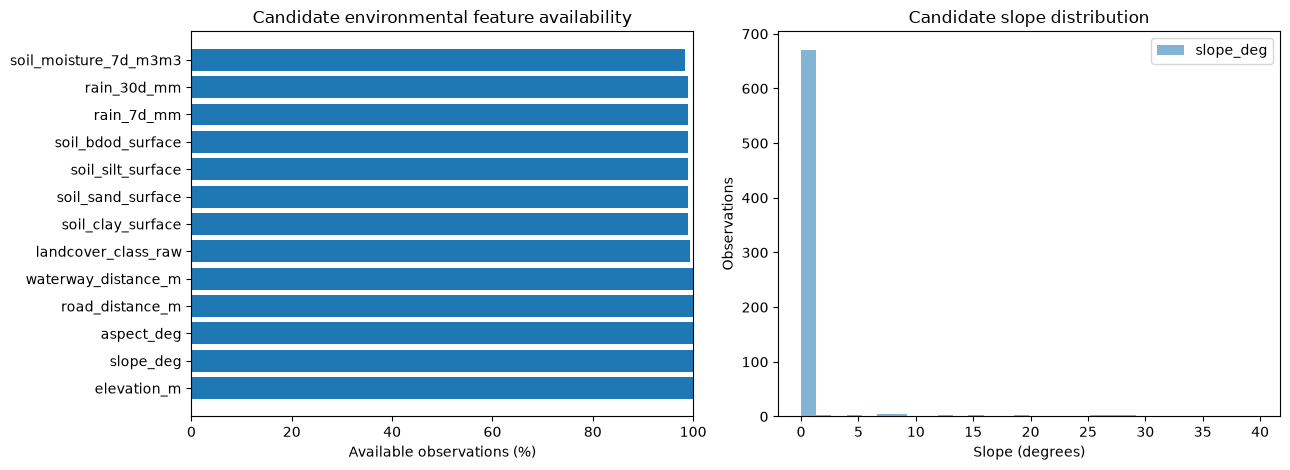

Documentation outputs: C:\landslide_fyp\outputs\documentation\notebook02
Note: these are candidate-level descriptive statistics, NOT the final case/background model dataset.


In [39]:
# Independent documentation-only analysis of the saved inventory-candidate features.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
_DOC_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p/'data/processed/features/environmental_features.csv').is_file()), None)
if _DOC_ROOT is None:
    raise FileNotFoundError('Run after original Notebook 02 feature extraction inside the FYP project.')
_doc = pd.read_csv(_DOC_ROOT/'data/processed/features/environmental_features.csv', low_memory=False)
_doc_dir = _DOC_ROOT/'outputs'/'documentation'/'notebook02'
_doc_dir.mkdir(parents=True,exist_ok=True)
print('Inventory-candidate observations:', len(_doc), '| columns:',len(_doc.columns))
print('Inventory sources and counts:')
if 'source' in _doc:
    display(_doc.groupby('source', dropna=False).size().rename('observations').to_frame())

# Explicitly select candidate-level factors, not target or provenance columns.
_candidate_factors = [c for c in ['elevation_m','slope_deg','aspect_deg',
                                  'soil_clay_surface','soil_sand_surface','soil_silt_surface',
                                  'soil_bdod_surface','road_distance_m','waterway_distance_m',
                                  'landcover_class_raw','rain_7d_mm','rain_30d_mm',
                                  'soil_moisture_7d_m3m3'] if c in _doc]
if not _candidate_factors:
    raise ValueError('None of the expected feature columns exists in environmental_features.csv.')
_q = pd.DataFrame([{'feature':c,'available':int(pd.to_numeric(_doc[c],errors='coerce').notna().sum()),
                    'missing':int(pd.to_numeric(_doc[c],errors='coerce').isna().sum()),
                    'missing_pct':round(100*pd.to_numeric(_doc[c],errors='coerce').isna().mean(),2),
                    'median':pd.to_numeric(_doc[c],errors='coerce').median(),
                    'p01':pd.to_numeric(_doc[c],errors='coerce').quantile(.01),
                    'p99':pd.to_numeric(_doc[c],errors='coerce').quantile(.99)}
                   for c in _candidate_factors])
_q.to_csv(_doc_dir/'01_candidate_feature_missingness_summary.csv',index=False)
display(_q.round(3))

fig,axes=plt.subplots(1,2,figsize=(13,4.8))
_v=_q.sort_values('missing_pct',ascending=True)
axes[0].barh(_v['feature'],100-_v['missing_pct'])
axes[0].set_xlim(0,100);axes[0].set_xlabel('Available observations (%)')
axes[0].set_title('Candidate environmental feature availability')
plotted=False
for c in ['slope_deg']:
    if c in _doc:
        z=pd.to_numeric(_doc[c],errors='coerce').dropna()
        if len(z):
            axes[1].hist(z,bins=30,alpha=.55,label=c)
            plotted=True
if plotted:axes[1].legend()
axes[1].set_title('Candidate slope distribution')
axes[1].set_xlabel('Slope (degrees)')
axes[1].set_ylabel('Observations')
fig.tight_layout()
fig.savefig(_doc_dir/'02_candidate_feature_quality.png',dpi=160,bbox_inches='tight')
plt.show()
print('Documentation outputs:',_doc_dir)
print('Note: these are candidate-level descriptive statistics, NOT the final case/background model dataset.')

In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

root = Path(r"C:\landslide_fyp")

for branch in ("static", "temporal"):
    path = (
        root / "data" / "processed" / "modelling"
        / f"{branch}_model_dataset_integrated_v1.csv"
    )

    df = pd.read_csv(path, low_memory=False)
    values = pd.to_numeric(
        df["elevation_m"], errors="coerce"
    ).to_numpy(dtype=float)

    invalid = (
        ~np.isfinite(values)
        | (values < -500)
        | (values > 9000)
    )

    print(f"\n{branch.upper()}")
    print("Total records:", len(values))
    print("Invalid elevation values:", int(invalid.sum()))
    print("Valid elevation values:", int((~invalid).sum()))



STATIC
Total records: 1968
Invalid elevation values: 0
Valid elevation values: 1968

TEMPORAL
Total records: 1929
Invalid elevation values: 0
Valid elevation values: 1929
